In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy import integrate
from matplotlib.colors import LogNorm
from matplotlib import colors as mcolors
import matplotlib.pyplot as plt
import csv
from scipy.integrate import cumulative_trapezoid
import matplotlib.ticker as ticker
import scipy as sp
from sklearn.metrics import r2_score

# Set the default figure size for all plots in inches (width, height)
plt.rcParams['figure.figsize'] = (10, 6) 

# Optionally, you can also increase the default DPI (dots per inch) for higher resolution
plt.rcParams['figure.dpi'] = 150 
colors = list(mcolors.TABLEAU_COLORS)

In [2]:
def RMSD_func(t,bt0,bt1,return_a = False):
    P = bt0
    Q = bt1
    a = np.trapezoid(P * Q,t) / np.trapezoid(Q**2,t)
    if return_a:
        return np.sqrt(np.trapezoid((P-a*Q)**2,t)/np.trapezoid(P**2,t)),a
    else:
        return np.sqrt(np.trapezoid((P-a*Q)**2,t)/np.trapezoid(P**2,t))

In [3]:
def ADE_analytical_basic(x,t,deltax,deltat,bound_cond):
    n_interp = 4
    x_interp = (x + np.linspace(-deltax/2,deltax/2,n_interp+1)[:-1,None]+deltax/(2*n_interp)).T.flatten()
    t_interp = (t + np.linspace(-deltat/2,deltat/2,n_interp+1)[:-1,None]+deltat/(2*n_interp)).T.flatten()
    if bound_cond == 'semi-infinite-conc':
        c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),x_interp/np.sqrt(4*np.pi*(t_interp**3)[...,None])*np.exp(-(x_interp-t_interp[...,None])**2/(4*t_interp[...,None])))
    if bound_cond == 'infinite':
        c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),1/np.sqrt(4*np.pi*t_interp[...,None])*np.exp(-(x_interp-t_interp[...,None])**2/(4*t_interp[...,None])))
    return np.mean(np.mean(c_interp.reshape((len(t),n_interp,len(x),n_interp)), axis = 1),axis = 2)

In [4]:
def ADE_forced_analytical_basic(x,t,deltax,deltat,bound_cond,k):
    n_interp = 4
    x_interp = (x + np.linspace(-deltax/2,deltax/2,n_interp+1)[:-1,None]+deltax/(2*n_interp)).T.flatten()
    t_interp = (t + np.linspace(-deltat/2,deltat/2,n_interp+1)[:-1,None]+deltat/(2*n_interp)).T.flatten()
    # if bound_cond == 'semi-infinite-conc':
        # c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),x_interp/np.sqrt(4*np.pi*(t_interp**3)[...,None])*np.exp(-(x_interp-t_interp[...,None])**2/(4*t_interp[...,None])))
    if bound_cond == 'infinite':
        c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),1/np.sqrt(4*np.pi*t_interp[...,None])*np.exp(-k*t_interp[...,None]-(x_interp-t_interp[...,None])**2/(4*t_interp[...,None])))
    return np.mean(np.mean(c_interp.reshape((len(t),n_interp,len(x),n_interp)), axis = 1),axis = 2)

In [5]:
def ADE_forced_analytical_exp_params(x,t,deltax,deltat,bound_cond,k,v_fac,D_fac,k_fac,alpha_v,alpha_D,alpha_k):
    n_interp = 4
    x_interp = (x + np.linspace(-deltax/2,deltax/2,n_interp+1)[:-1,None]+deltax/(2*n_interp)).T.flatten()
    t_interp = (t + np.linspace(-deltat/2,deltat/2,n_interp+1)[:-1,None]+deltat/(2*n_interp)).T.flatten()
    v_int_f = lambda t: (t-(v_fac-1)/alpha_v*(np.exp(-alpha_v*t)-1))
    D_int_f = lambda t: (t-(D_fac-1)/alpha_D*(np.exp(-alpha_D*t)-1))
    k_int_f = lambda t: k*(t-(k_fac-1)/alpha_k*(np.exp(-alpha_k*t)-1))
    v_int = v_int_f(t_interp)
    D_int = D_int_f(t_interp)
    k_int = k_int_f(t_interp)
    # if bound_cond == 'semi-infinite-conc':
        # c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),x_interp/np.sqrt(4*np.pi*(t_interp**3)[...,None])*np.exp(-(x_interp-v_int[...,None])**2/(4*v_int[...,None])))
    if bound_cond == 'infinite':
        c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),1/np.sqrt(4*np.pi*D_int[...,None])*np.exp(-k_int[...,None]-(x_interp-v_int[...,None])**2/(4*D_int[...,None])))
    return np.mean(np.mean(c_interp.reshape((len(t),n_interp,len(x),n_interp)), axis = 1),axis = 2)

In [6]:
def ADE_analytical_exp_params(x,t,v_fac,D_fac,alpha_v,alpha_D):
    v_int_f = lambda t: (t-(v_fac-1)/alpha_v*(np.exp(-alpha_v*t)-1))
    D_int_f = lambda t: (t-(D_fac-1)/alpha_D*(np.exp(-alpha_D*t)-1))
    v_int = v_int_f(t)
    D_int = D_int_f(t)
    c = np.where(t[...,None]<=0,np.zeros_like(x+t[...,None]),1/np.sqrt(4*np.pi*D_int[...,None])*np.exp(-(x-v_int[...,None])**2/(4*D_int[...,None])))
    return c

In [7]:
data = np.load("effective_params.npz")

thetas = data["thetas"]
a_s = data["a_s"]
v_effs_central = data["v_effs_central"]
D_effs_central = data["D_effs_central"]
k_effs_central = data["k_effs_central"]
v_effs_bound = data["v_effs_bound"]
D_effs_bound = data["D_effs_bound"]
k_effs_bound = data["k_effs_bound"]
v_effs_uniform = data["v_effs_uniform"]
D_effs_uniform = data["D_effs_uniform"]
k_effs_uniform = data["k_effs_uniform"]

In [8]:
def ADE_forced_analytical_derived_params(x,t,deltax,deltat,k_inf,D_fac,kappa,a,loc):
    n_interp = 4
    x_interp = (x + np.linspace(-deltax/2,deltax/2,n_interp+1)[:-1,None]+deltax/(2*n_interp)).T.flatten()
    t_interp = (t + np.linspace(-deltat/2,deltat/2,n_interp+1)[:-1,None]+deltat/(2*n_interp)).T.flatten()
    if loc=='center':
        v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_central.T])
        D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_central.T])
        k_effs = k_effs_central
    if loc=='uniform':
        v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_uniform.T])
        D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_uniform.T])
        k_effs = k_effs_uniform
    if loc == 'bound':
        v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_bound.T])
        D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_bound.T])
        k_effs = k_effs_bound
    vs = np.interp(t_interp/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,v_effs_a,right = 1.0)
    Ds = np.interp(t_interp/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,D_effs_a*(6*(a+3)*(2*a+3)), left = 0.0,right = 1)*(1-D_fac)+D_fac
    ks = (np.interp(t_interp/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,k_effs,right = 1.0)*(1-kappa)+kappa)*k_inf
    v_int = cumulative_trapezoid(vs,x = t_interp, initial = 0.0)
    D_int = cumulative_trapezoid(Ds,x = t_interp, initial = 0.0)
    k_int = cumulative_trapezoid(ks,x = t_interp, initial = 0.0)
    if bound_cond == 'infinite':
        c_interp = np.where(t_interp[...,None]<=0,np.zeros_like(x_interp+t_interp[...,None]),1/np.sqrt(4*np.pi*D_int[...,None])*np.exp(-k_int[...,None]-(x_interp-v_int[...,None])**2/(4*D_int[...,None])))
    return np.mean(np.mean(c_interp.reshape((len(t),n_interp,len(x),n_interp)), axis = 1),axis = 2)

In [9]:
def int_D_ratio_uniform(T_,Pe,D_fac,a):
    n_interp = 4
    ts = np.linspace(0,T_*Pe, int(200*T_))
    D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_uniform.T])
    Ds = np.interp(ts/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,D_effs_a*(6*(a+3)*(2*a+3)), left = 0.0,right = 1)*(1-D_fac)+D_fac
    D_int =  cumulative_trapezoid(Ds,x = ts, initial = 0.0)
    return D_int/ts

In [10]:
def ADE_analytical_derived_params(x,t,D_fac,a,loc):
    if loc=='center':
        v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_central.T])
        D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_central.T])
    if loc == 'bound':
        v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_bound.T])
        D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_bound.T])
    vs = np.interp(t/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,v_effs_a,right = 1.0)
    Ds = np.interp(t/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,D_effs_a*(6*(a+3)*(2*a+3)), left = 0.0,right = 1)*(1-D_fac)+D_fac
    v_int = cumulative_trapezoid(vs,x = t, initial = 0.0)
    D_int = cumulative_trapezoid(Ds,x = t, initial = 0.0)
    c = np.where(t[...,None]<=0,np.zeros_like(x+t[...,None]),1/np.sqrt(4*np.pi*D_int[...,None])*np.exp(-(x-v_int[...,None])**2/(4*D_int[...,None])))
    return c

# Validation

In [11]:

import numpy as np
# This is a python translation of the program written by Hollenbeck, K. J. (1998)
#
# DEHOOG - numerical inverse Laplace transform
#
# Description: 
#   algorithm: de Hoog et al's quotient difference method with accelerated 
#   convergence for the continued fraction expansion
#
#   [de Hoog, F. R., Knight, J. H., and Stokes, A. N. (1982). An improved 
#   method for numerical inversion of Laplace transforms. S.I.A.M. J. Sci. 
#   and Stat. Comput., 3, 357-366.]
#
#   Modification: The time vector is split in segments of equal magnitude
#   which are inverted individually. This gives a better overall accuracy.   
#
#   Details: de Hoog et al's algorithm f4 with modifications (T->2*T and 
#    introduction of tol). Corrected error in formulation of z.
#
#   Copyright: Karl Hollenbeck
#             Department of Hydrodynamics and Water Resources
#             Technical University of Denmark, DK-2800 Lyngby
#             email: karl@isv16.isva.dtu.dk
#
#   22 Nov 1996, MATLAB 5 version 27 Jun 1997 updated 1 Oct 1998
#   IF YOU PUBLISH WORK BENEFITING FROM THIS M-FILE, PLEASE CITE IT AS:
#       Hollenbeck, K. J. (1998) INVLAP.M: A matlab function for numerical 
#       inversion of Laplace transforms by the de Hoog algorithm, 
#       http://www.isva.dtu.dk/staff/karl/invlap.htm 
#
#   Renamed by P. Renard to be integrated in the hytool toolbox.
#
# example: 
#   identity function in Laplace space:
#   F = lambda s: 1/(s**2)        
#   invlap(F, np.array([1,2,3]))                # gives [1,2,3]
#
# See also: stefhest
#

import numpy as np 
import warnings

warnings.filterwarnings('ignore', 'overflow')
warnings.filterwarnings('ignore', 'invalid')
warnings.filterwarnings('ignore', 'divide')

def invlap(F, t,args, alpha=0, tol=1e-10,M = 200):
    """
    F      = laplace-space function (string refering to an m-file),must
             have form F(s, args), where s is the Laplace parameter 
             and return column vector as result
    t      = column vector of times for which real-space function values
             are sought
    args   = other parameters of F
    alpha  = largest pole of F (default zero)
    tol    = numerical tolerance of approaching pole (default 1e-10)
    f      = vector of real-space values f(t)   
    """
    f = []
    # Split up t vector in pieces of the same order of magnitude, invert one piece
    # at a time. Simultaneous inversion for times covering several orders of
    # magnitudes gives inaccurate results for the small times.
    allt = t
    logallt = np.log10(allt)
    iminlogallt = int(np.floor(np.min(logallt)))
    imaxlogallt = int(np.ceil(np.max(logallt)))

    for ilogt in range(iminlogallt, imaxlogallt + 1):
        t = allt[(logallt >= ilogt) & (logallt < (ilogt + 1))]
        if t.size > 0:  # Maybe no elements in that magnitude
            T = np.max(t) * 2
            gamma = alpha - np.log(tol) / (2 * T)
            # NOTE: The correction alpha -> alpha-log(tol)/(2*T) is not in de Hoog's
            #   paper, but in Mathematica's Mathsource (NLapInv.m) implementation of
            #   inverse transforms
            nt = len(t)
            run = np.arange(2 * M + 1)  # so there are 2M+1 terms in Fourier series expansion

            # Find F argument, call F with it, get 'a' coefficients in power series
            s = gamma + 1j * np.pi * run / T
            a = F(s, *args)
            a = a.flatten()
            a[0] = a[0] / 2  # zero term is halved

            # Build up e and q tables. Superscript is now row index, subscript column
            # CAREFUL: paper uses null index, so all indices are shifted by 1 here
            e = np.zeros((2 * M + 1, M + 1), dtype=complex)
            q = np.zeros((2 * M, M + 1), dtype=complex)  # Column 0 (here: 1) does not exist
            e[:, 0] = np.zeros(2 * M + 1)
            q[:, 1] = a[1:2 * M + 1] / a[:2 * M]
            for r in range(2, M + 2):  # Step through columns (called r...)
                e[:2 * (M - r+1), r-1] = q[1:2 * (M - r+1) + 1, r-1] - q[:2 * (M - r+1), r-1] + e[1:2 * (M - r+1) + 1, r - 2]
                if r < M:  # One column fewer for q
                    rq = r + 1
                    q[:2 * (M - rq) + 2, rq-1] = q[1:2 * (M - rq) + 3, rq - 2] * e[1:2 * (M - rq) + 3, rq - 2] / e[:2 * (M - rq) + 2, rq - 2]

            # Build up d vector (index shift: 1)
            d = np.zeros(2 * M + 1, dtype=complex)
            d[0] = a[0]
#             d[1::2] = -q[:M, 1:M + 1].diagonal()
#             d[2::2] = -e[:M, 1:M + 1].diagonal()
            d[1::2] = -q[0, 1:M + 1].T
            d[2::2] = -e[0, 1:M + 1].T

            # Build up A and B vectors (index shift: 2)co
            # - now make into matrices, one row for each time
            A = np.zeros((2 * M + 2, nt), dtype=complex)
            B = np.zeros((2 * M + 2, nt), dtype=complex)
            A[1, :] = d[0] * np.ones(nt)
            B[:2, :] = np.ones((2, nt))
            z = np.exp(1j * np.pi * t / T)  # Row vector

            dz = np.outer(d, z)
            
            for n in range(2, 2 * M + 2):
                A[n, :] = A[n - 1, :] + dz[n - 1, :] * A[n - 2, :]
                B[n, :] = B[n - 1, :] + dz[n - 1, :] * B[n - 2, :]


            # Double acceleration
            h2M = 0.5 * (1 + (d[2 * M - 1] - d[2 * M]) * z)
            R2Mz = -h2M * (1 - np.sqrt(1 + d[2 * M] * z / (h2M**2)))
            A[2 * M + 1, :] = A[2 * M, :] + R2Mz * A[2 * M - 1, :]
            B[2 * M + 1, :] = B[2 * M, :] + R2Mz * B[2 * M - 1, :]

            # Inversion, vectorized for times, make result a column vector
            fpiece = (1 / T * np.exp(gamma * t) * np.real(A[2 * M + 1, :] / B[2 * M + 1, :])).flatten()
            f.extend(fpiece)

    return np.array(f)

from scipy.special import expn
from mpmath import expint

def ADEMF_1D(ts, xs, v, Pe, beta, g_params, memory_func, bound_cond):
    """
    Solves the memory function advection-dispersion-immobile-exchange model with constant coefficients
    ts = Array. Times after release
    xs = Array. Distance from the point of release
    v = Float. Advection velocity
    Pe = Float. Peclet number
    beta = Float. Ratio between the effective immobile phase area and the mobile phase area
    g_params = List of the parameters of the corresponding memory function
                'first order' takes [k_f,k_r]
                'power law' takes [alpha,1-gamma]   
    memory_func = Either 'first order' or 'power law', others can be added editing c_lap_space
    bound_cond = Either 'semi-infinite-conc', 'semi-infinite-mixed', or 'infinite'
                'semi-infinite-conc' is a domain x>0 with vc(x=0,t)=M_0 delta(t)
                'semi-infinite-mixed' is a domain x>0 with vc(x=0,t)- 2 D dc/dx (x=0,t) =M_0 delta(t)
                'infinite' is a domain x>0 with vc(x=0,t)-2 D dc/dx (x=0,t) =M_0 delta(t). The solution to this problem is equivalent to the solution in the infinite domain
    """
    exp_int_ = np.vectorize(lambda s: complex(expint(g_params[1]+1,s/g_params[0])))
    def sol_lap_space(s, x):
        """
        Auxilitary function for c_lap_solver
        """
        if memory_func == 'first order':
            G = lambda s,g_params: g_params[0]/(g_params[1] + s)
        if memory_func == 'power law':
            G = lambda s,g_params: g_params[0]*s**(-g_params[1])
        if memory_func == 'gamma':
            G = lambda s,g_params: g_params[1]*np.exp(s/g_params[0])*exp_int_(s)
        b = s + beta * s * G(s,g_params)
        if bound_cond == 'semi-infinite-conc':
            c = np.exp(x*(Pe- np.sqrt(Pe*(4*b+Pe)))/2)
        if bound_cond == 'semi-infinite-mixed':
            c = 1/(1/2+np.sqrt(4*b+Pe)/(2*np.sqrt(Pe)))*np.exp(x*(Pe- np.sqrt(Pe*(4*b+Pe)))/2)
        if bound_cond == 'infinite':
            c = np.sqrt(Pe/(4*b+Pe)) * np.exp((Pe*x- np.sqrt(Pe*x**2*(4*b+Pe)))/2)
        return c
    cis = np.array([invlap(sol_lap_space, ts*v/xs[-1], [x/xs[-1]]) for x in xs])*v/xs[-1]
    cis = np.nan_to_num(np.array(cis).T, 0.0)
    return cis

In [12]:
import scipy
def moms_analyt(params,x,bound_cond, exchange):
    """
    Calculates analytical moments as derived Aghababaei, M., & Ginn, T. R. (2023). Temporal moments of one-dimensional advective-dispersive transport with exchange represented via memory function models: Application to river corridor transport. Advances in Water Resources, 172, 104383. https://doi.org/10.1016/j.advwatres.2023.104383
    The formulation for different boundary conditions is original to this work.
    params = List of independent parameters [v,Pe,beta,k_r/v*x] (all parameters but the velocity are dimensionless)
    x = Float. Sampling location.
    bound_cond = Either 'semi-infinite-conc', 'semi-infinite-mixed', or 'infinite'
                'semi-infinite-conc' is a domain x>0 with vc(x=0,t)=M_0 delta(t)
                'semi-infinite-mixed' is a domain x>0 with vc(x=0,t)- 2 D dc/dx (x=0,t) =M_0 delta(t)
                'infinite' is a domain x>0 with vc(x=0,t)-2 D dc/dx (x=0,t) =M_0 delta(t). The solution to this problem is equivalent to the solution in the infinite domain
    :returns: Array of first 4 analytical kth central moments to the power 1/k, such that they all have the same dimension [T].
    """
    if bound_cond == 'semi-infinite-conc':
        n_BC = 0
    if bound_cond == 'semi-infinite-mixed':
        n_BC = 1
    if bound_cond == 'infinite':
        n_BC = 2
    
    A_1 = lambda beta,ex_par: 1+beta
    if exchange == 'first order':
        A_2 = lambda beta,ex_par: 2*beta/ex_par
        A_3 = lambda beta,ex_par: 6*beta/ex_par**2
        A_4 = lambda beta,ex_par: 24*beta/ex_par**3
    if exchange == 'gamma':
        A_2 = lambda beta,ex_par: 2*beta/(ex_par[0]*(ex_par[1]-1))
        A_3 = lambda beta,ex_par: 6*beta/(ex_par[0]**2*(ex_par[1]-1)*(ex_par[1]-2))
        A_4 = lambda beta,ex_par: 24*beta/(ex_par[0]**3*(ex_par[1]-1)*(ex_par[1]-2)*(ex_par[1]-3))

    a_11 = lambda v,D,beta,ex_par: A_1(beta,ex_par)/v
    mu1 = lambda x,v,D,beta,ex_par: a_11(v,D,beta,ex_par)*(x+D/v*n_BC)

    a_21 = lambda v,D,beta,ex_par: 2*A_1(beta,ex_par)**2*D/v**3+(A_2(beta,ex_par)+2*A_1(beta,ex_par)*mu1(0,v,D,beta,ex_par))/v
    a_22 = lambda v,D,beta,ex_par: a_11(v,D,beta,ex_par)**2
    mu2 = lambda x,v,D,beta,ex_par: a_21(v,D,beta,ex_par)*(x+D/v*n_BC)+a_22(v,D,beta,ex_par)*(x**2)

    a_31 = lambda v,D,beta,ex_par: (A_3(beta,ex_par)+3*A_1(beta,ex_par)*mu2(0,v,D,beta,ex_par)+3*A_2(beta,ex_par)*mu1(0,v,D,beta,ex_par))/v +6*(A_2(beta,ex_par)*A_1(beta,ex_par)*D+A_1(beta,ex_par)**2*D*mu1(0,v,D,beta,ex_par))/v**3 +12*A_1(beta,ex_par)**3*D**2/v**5
    a_32 = lambda v,D,beta,ex_par: 3*A_1(beta,ex_par)*(A_2(beta,ex_par)+A_1(beta,ex_par)*mu1(0,v,D,beta,ex_par))/v**2 +6*A_1(beta,ex_par)**3*D/v**4
    a_33 = lambda v,D,beta,ex_par: a_11(v,D,beta,ex_par)**3
    mu3 = lambda x,v,D,beta,ex_par: a_31(v,D,beta,ex_par)*(x+D/v*n_BC)+a_32(v,D,beta,ex_par)*(x**2)+a_33(v,D,beta,ex_par)*(x**3)

    a_41 = lambda v,D,beta,ex_par: (A_4(beta,ex_par)+4*A_1(beta,ex_par)*mu3(0,v,D,beta,ex_par)+6*A_2(beta,ex_par)*mu2(0,v,D,beta,ex_par)+4*A_3(beta,ex_par)*mu1(0,v,D,beta,ex_par))/v +(8*A_1(beta,ex_par)*A_3(beta,ex_par)*D+6*A_2(beta,ex_par)**2*D+24*A_1(beta,ex_par)*A_2(beta,ex_par)*D*mu1(0,v,D,beta,ex_par)+12*A_1(beta,ex_par)**2*D*mu2(0,v,D,beta,ex_par))/v**3 + (72*A_1(beta,ex_par)**2*A_2(beta,ex_par)*D**2+48*A_1(beta,ex_par)**3*D**2*mu1(0,v,D,beta,ex_par))/v**5 +120*A_1(beta,ex_par)**4*D**3/v**7
    a_42 = lambda v,D,beta,ex_par: ((3*A_2(beta,ex_par)**2+4*A_1(beta,ex_par)*A_3(beta,ex_par))+12*A_1(beta,ex_par)*A_2(beta,ex_par)*mu1(0,v,D,beta,ex_par)+6*A_1(beta,ex_par)**2*mu2(0,v,D,beta,ex_par))/v**2 + (36*A_1(beta,ex_par)**2*A_2(beta,ex_par)*D+24*A_1(beta,ex_par)**3*D*mu1(0,v,D,beta,ex_par))/v**4 + 60*A_1(beta,ex_par)**4*D**2/v**6
    a_43 = lambda v,D,beta,ex_par: (6*A_1(beta,ex_par)**2*A_2(beta,ex_par)+4*A_1(beta,ex_par)**3*mu1(0,v,D,beta,ex_par))/v**3 + 12*A_1(beta,ex_par)**4*D/v**5
    a_44 = lambda v,D,beta,ex_par: a_11(v,D,beta,ex_par)**4
    mu4 = lambda x,v,D,beta,ex_par: a_41(v,D,beta,ex_par)*(x+D/v*n_BC)+a_42(v,D,beta,ex_par)*(x**2)+a_43(v,D,beta,ex_par)*(x**3)+a_44(v,D,beta,ex_par)*(x**4)

    m1_analytical =lambda x,v,D,beta,ex_par: a_11(v,D,beta,ex_par)*(x+D/v*n_BC)
    m2_analytical =lambda x,v,D,beta,ex_par: a_21(v,D,beta,ex_par)*(x+D/v*n_BC)-a_11(v,D,beta,ex_par)**2*(2*x*D/v*n_BC+(D/v*n_BC)**2)
    m3_analytical =lambda x,v,D,beta,ex_par: mu3(x,v,D,beta,ex_par)-3*mu1(x,v,D,beta,ex_par)*mu2(x,v,D,beta,ex_par)+2*mu1(x,v,D,beta,ex_par)**3
    m4_analytical =lambda x,v,D,beta,ex_par: mu4(x,v,D,beta,ex_par)-4*mu1(x,v,D,beta,ex_par)*mu3(x,v,D,beta,ex_par)+6*mu2(x,v,D,beta,ex_par)*mu1(x,v,D,beta,ex_par)**2-3*mu1(x,v,D,beta,ex_par)**4

    mi_analytical_t_dim = [lambda x,v,D,beta,ex_par: m1_analytical(x,v,D,beta,ex_par),
                         lambda x,v,D,beta,ex_par: (m2_analytical(x,v,D,beta,ex_par))**(1/2),
                         lambda x,v,D,beta,ex_par: (m3_analytical(x,v,D,beta,ex_par))**(1/3),
                         lambda x,v,D,beta,ex_par: (m4_analytical(x,v,D,beta,ex_par))**(1/4)]
    if exchange == 'first order':
        return np.array([mi_analytical_t_dim[i](x,params[0],x*params[0]/params[1],params[2],params[3]*params[0]/x) for i in range(4)])
    if exchange == 'gamma':
        return np.array([mi_analytical_t_dim[i](x,params[0],x*params[0]/params[1],params[2],[params[3]*params[0]/x,params[4]]) for i in range(4)])



In [13]:
def moms_meas(t,btc):
    """
    Computes the first 4 kth central moments of the measured breakthrough curve, using the trapezoidal rule of integration.
    t = Times of measurement of concentrations
    btc = Measured concentrations (same length as t)
    :returns: Array of first 4 measured kth central moments to the power 1/k, such that they all have the same dimension [T].
    """
    mu_i = [np.trapezoid(btc*t**j,x=t)/np.trapezoid(btc,x=t) for j in range(5)]
    m_i = [mu_i[1],
           mu_i[2]-mu_i[1]**2,
           mu_i[3]-3*mu_i[1]*mu_i[2]+2*mu_i[1]**3,
           mu_i[4]-4*mu_i[1]*mu_i[3]+6*mu_i[2]*mu_i[1]**2-3*mu_i[1]**4]
    return np.array(m_i)

## Errors in phase exposure independent

In [13]:
Pes_est_str = ["912.070253052059", "2036.04931523501", "2127.35574513866", "2145.06766555603", "1970.23116459073", "739.840890383797", "970.543809887417", "1454.6167650621", "1270.93679401997", "1622.98897670797", "1766.02085801798", "1852.44989366055", "2145.70061621696", "990.706058891737", "856.438412495257", "15251.07316965", "1699.01996526365", "2777.92207954958", "927.195790722503", "1319.96739146922", "10154.4328479027", "5690.64251628373", "1010.50026303974", "1617.91114796621", "1897.03060805722", "1418.79683161671", "1082.45927833645", "4237.43970371855", "2057.18329948713", "4955.71266672854", "3381.73883637888", "3554.68051349186", "2233.4209758403", "2947.35895785317", "1732.39787960129", "5649.9905149957", "17779.2395106453", "4549.44285417161", "6081.34522636305", "2565.38308744858", "4497.23335669262", "12034.1888527889", "1698.79555147273", "1300.22826494725", "15781.402655055", "9534.33918997109", "1793.65238342832", "1700.09077573891", "11972.7910581499", "5476.51465751859", "8167.54750832198", "724.332947099968", "1745.82558365087", "1318.62205881275", "1458.0952411171", "109.098755933822", "142.526425444365", "132.002292616892", "4163.40115199694", "463.93390481472", "298.59039575477", "2740.63073330019", "5501.20828031926", "3994.65781822226", "16542.4419999915", "241.309443433204", "8940.35895380611", "10328.7067476518", "142.222756152265", "42.275444795549", "32.8299678615845", "37.9193277722762", "152.023666432519", "30.1421062744577", "102.042940734216", "159.29497016272", "40.574395999632", "87.188120261832", "28.9302541000503", "85.5464685097508", "129.519110307803", "44.7681958600064", "4953.51818851419", "113.355689123623", "90.8157969974169", "47.4153574372396", "180.012687129735", "47.6498654383278", "131.241140260812", "44.6673140431853", "90.1805490638571", "158.0936266534", "39.8432424411941", "47.6354060086113", "51.3322161428142", "89.3189018719923", "37.3686097589846", "140.495852600636", "161.284318498962", "40.8952753350963", "129.5392992632", "40.2671212015593", "107.633978595638", "185.462721954993", "32.6384323943347", "100.540947962913", "139.729240402512", "61.451546115395", "126.462663452267", "27.2104196701857", "70.4780015321714", "40.4437422515189", "90.042162539158", "130.803166703291", "40.0698098180148", "64.4209500794493", "31.8825374953188", "71.1481462136634", "160.945478120056", "66.6078908061507", "150.59847543512", "240.837068558197", "50.0856056975774", "150.851208805705", "57.440572785925", "161.003344247953", "200.938385356842", "45.1647545815258", "132.567423425284", "106.826644566541", "53.4788949748033", "179.590907425353", "68.4755051456719", "129.575469116254", "46.2133092695595", "151.870927125294", "209.122116111516", "59.6829538680174", "227.030104696074", "222.381212653752", "118.470591832652", "66.56805117717", "139.01962659935", "158.738813172503", "37.2572029728199", "129.161022848063", "27.7460571786085", "126.903995448741", "122.84558835039", "35.372824156663", "972.786048251153", "705.849463214054", "1626.91756677678", "2057.96490001273", "2247.30347249971", "2985.5591136949", "1988.40733373717", "1986.38542067394", "1324.83322129384", "1220.46030209431", "1981.3221784709", "2420.64653699262", "2419.8305092301", "636.885778319601", "1101.68416088393", "1716.81791183526", "2400.20776064909", "63.149767330674", "207.884070872383", "348.404778264759", "916.140995634623", "2376.52857400123", "3550.9530186869", "8049.00428087897", "4416.42441440955", "4844.20319533709", "661.524524334371", "707.753345485919", "2019.11492573221", "1916.06411305792", "2108.54253859092", "2380.96580961216", "6648.14410760256", "313.841198173208", "499.28238369548", "785.492950336368", "919.614154054113", "11306.9119032138", "1275.97055533376", "5176.14374222385", "974.476317253678", "869.163136044101", "1378.14989956006", "1679.11609100342", "2602.99455114387", "2443.28597809168", "2386.23560706881", "757.864485220676", "1089.88709906316", "290.0847650335", "433.153214120942", "965.992964475125", "2694.00577391695", "624.648273653843", "870.402491365629", "569.732029759257", "2237.09978988951", "427.240759374852", "6267.42844614862", "15557.5963268999", "3756.79281994656", "5751.08337364767", "10933.6210175988", "4622.67323245386", "918.850104454098", "593.38408814949", "410.110506675263", "1037.75929852595", "593.49018275912", "1040.39238180606", "1012.67546013211", "1001.16686070405", "945.189520535629", "608.23813542474", "6317.41748543534", "819.234468368968", "979.605173004026", "1432.43432078071", "940.518827142729", "1619.78907137093", "2701.10555063403", "2857.6883050402", "3795.63000294524", "2083.33001199203", "1275.01606742404", "2304.14587019387", "3496.656636275", "3273.965723322", "1620.89277354304", "1150.22373941864", "5171.68263436003", "3776.69854370438", "6702.30986388852", "2638.78960965424", "1119.00978946255", "1824.09447454257", "544.124890605211", "335.30385175625", "1175.48733718073", "157.228191467579", "10493.7713677172", "20420.853534519", "243.029942767063", "198.103231111212", "1956.79750678585", "571.282443169739", "18.1246278228947", "886.515101560572", "8220.12394806138", "179.186580577226", "1261.24294302492", "2495.19075583026", "870.737941353511", "2683.47537524795", "2893.12361466217", "3612.39982800786", "963.047603382854", "2886.68834119772", "1096.96888957256", "1433.88441733514", "1437.01476426989", "1749.32994309597", "5448.9933943073", "7236.46633812952", "1857.7367015561", "3852.48699153673", "1678.03506572257", "982.35052793717", "496.1413164253", "5503.83863461584", "2319.08000079186", "579.582456921703", "847.198781776941", "1077.83657545351", "2113.83960666268", "4133.665604896", "886.751153366548", "980.101748154186", "7764.37692862368", "1414.26607178239", "1242.43071617275", "506.56553722346", "1970.1450743325", "278.072622119325", "572.021019276574"]
Pes_est = np.array(Pes_est_str).astype(float)

In [14]:
beta_kf_est_str = ["2.4136903332102", "0.43627539368556", "0.506632814955258", "0.468827061401809", "0.563593500899347", "0.58273558276996", "0.441633339044363", "0.450830999478404", "0.281231280093048", "0.523641672642644", "0.381064254486182", "0.432063041302067", "0.461748487900804", "1.8169115505728", "1.20002326398573", "7.43923678034275", "0.952841660196296", "1.82721822521695", "2.22394774677075", "0.745922478485097", "9.20134291132421", "2.5975052274269", "0.8301288923681", "1.19949904494707", "1.23072693006669", "1.37224770911378", "0.712752241181732", "3.00729071994213", "0.165601284640107", "4.7282283031672", "1.5694168797652", "1.7688135286231", "1.1165916158003", "3.50705162653956", "1.49690806631841", "0.704208250196212", "55.5232886674543", "0.959368126381444", "9.27971283568117", "1.13355131330219", "1.23244569847658", "5.38344182365798", "4.85990556418846", "0.192396572790166", "32.038471848454", "12.0319418667473", "2.35997682719399", "3.6184769452979", "28.8710023544138", "17.013868584308", "4.14296650519374", "0.547489397430142", "1.03328551265991", "0.720239188558996", "1.05889848098362", "0.361208052667063", "0.834026913587225", "0.66915559827052", "3.91318225930625", "2.72954069162367", "1.77410513360037", "0.0745124046014582", "0.411482211936347", "1.19535292153129", "5.47341898359774", "2.63046514064902", "0.511721687388373", "1.70692845609562", "1.7766613128", "1.11213854122549", "0.422274233824461", "0.612960680811393", "1.18404384912401", "0.679600473543988", "0.358570880279962", "0.496416812503638", "0.57258062831903", "0.302803494829749", "0.520147021630383", "0.341901413741016", "0.345855068538461", "1.2410662510166", "18.692340226243", "0.583049854548943", "0.426654974570273", "0.697551790192934", "0.656587604630675", "0.689096583124324", "0.853065691992108", "1.85780576480492", "0.264116066449345", "0.541308284880175", "1.83151716306897", "0.667565997900625", "0.72340096559054", "0.541396720952867", "1.8044539904619", "0.600189191990817", "0.530048616239346", "0.367704185361199", "0.5848158650936", "0.564815617546991", "0.381668591766431", "0.494579911670456", "0.372069236380164", "0.532664283348853", "0.552216735259889", "0.560562649233668", "0.573912043763539", "0.339541896542471", "0.455812284166961", "0.553049762894432", "0.408348744333637", "0.501214521352558", "0.933742877679765", "0.666917235564639", "0.0837710975450082", "0.809097324790655", "0.459204977242762", "0.788165174620997", "0.469189179741778", "0.593853123214146", "0.595737003758019", "0.494023489065177", "0.590684009287227", "0.595414612860581", "0.50385281947572", "0.780704352315167", "0.524052316315231", "0.511088872495917", "1.45466380869714", "0.545805840517031", "0.995078547215796", "0.603959268405518", "0.716192038335021", "0.460963167217027", "0.497826863051077", "0.439317886413237", "1.31903668317969", "1.11425044587698", "0.452990457734458", "0.57118846717184", "0.503891194807026", "0.443539226031257", "0.43495703440231", "0.926127011276274", "0.850238058896273", "0.700631010101844", "0.508646721850436", "1.77609557064091", "2.32533421856329", "0.58167402111634", "0.746577852207413", "0.970892450933129", "0.628204729443324", "1.27669883518652", "2.47965256331496", "3.65881144173272", "1.64486406154921", "0.81012752817969", "1.25016697220524", "1.40453047092845", "1.20119071535646", "4.85836883989385", "0.654026112711333", "0.448286897241833", "0.755388494598772", "1.01146846377084", "1.09696191242321", "2.06204922547278", "3.84957061963927", "4.16680598383163", "4.29732356852124", "12.7884505476325", "1.05808980592469", "0.979294002809692", "2.31353919514497", "0.544804351105577", "1.94280226992546", "2.70211805542133", "1.32112319324546", "0.482231347376101", "1.78381966360031", "0.913960013937963", "1.64234417534133", "1.26660019517981", "1.53520309063153", "8.8809657569829", "0.943935038527429", "3.16671307291893", "9.2544253019595", "1.44403243695572", "0.162830378310884", "0.393541462423837", "1.05047878261127", "0.765340866602748", "0.744884591425738", "0.570241726897616", "0.689553377441747", "2.27193456625735", "0.281143100530748", "0.70252455824127", "1.36450841507271", "0.871122944523067", "1.15942079001838", "0.242459424994679", "1.15933930844864", "1.93351730688785", "23.0666856278855", "34.9333973262631", "7.30045918861624", "5.53102104870994", "36.434270551212", "1.8400244182249", "1.09780373206748", "1.28886947160912", "0.290187024081556", "2.62359283963569", "0.286197370150472", "0.871300581021068", "0.870619679869316", "0.908615575485784", "1.0497154917569", "0.591822829265594", "3.99156476624772", "1.21288858152487", "0.48616932233443", "1.55365447008436", "0.840606837477692", "0.303959638503676", "0.622670331645769", "0.694219662847019", "1.101791806199", "0.873532817031821", "1.29478368220382", "1.5522087533723", "1.89796978854844", "2.44797222453859", "1.4962102541139", "24.6308875879276", "2.93215937827356", "1.63311340734248", "1.75519974196258", "1.71872708424892", "1.27377031303059", "2.55992360501324", "1.60270254016002", "1.95307430914017", "2.38951277336871", "1.41973008239343", "7.26973144643053", "3.73852595357646", "0.64177494444487", "1.10046307031809", "4.2528949723351", "2.03600005645357", "2.43332769621049", "3.72530565179643", "48.7815460299118", "3.58826140223543", "1.06468478499349", "1.74406980945848", "2.77473966290121", "0.800998288011947", "0.70176835380769", "0.94984160501713", "1.37941640612681", "1.64809046446817", "0.876922294230082", "2.05116200017689", "2.02624712605545", "1.91740128208943", "5.70522931951983", "21.3649084026704", "1.16744681179583", "2.92149146031799", "2.64043421770074", "2.73449248307334", "0.417480635820201", "3.79179750651429", "2.82370861279955", "1.18438254157087", "1.32031233011406", "1.90306219436074", "3.04389449284725", "6.10621967411304", "1.37683140075055", "5.24960191783562", "5.19193504586521", "2.49355486371262", "1.40584554171126", "1.77464280524758", "4.06149909887565", "0.863557182315654", "1.39077531364899"]
beta_kf_est = np.array(beta_kf_est_str).astype(float)

In [15]:
krs_est_str = ["20.7273159393572", "2.6298636556622", "4.05711183762929", "3.03023459107745", "4.30811285183158", "12.4990421023887", "11.3468391174776", "12.3959512693211", "3.83943910078175", "16.2073521381217", "2.80635531372568", "4.42764452280606", "3.58488567946568", "9.35805666839555", "19.6608953273013", "57.4814441476116", "26.1649246014289", "6.52266136649981", "23.0987253899206", "13.8003220829791", "81.7479123643855", "11.1421075611242", "22.8136816152526", "32.3581346500064", "39.7578378359301", "11.3357535126576", "21.9511420360677", "51.625510957103", "1.23871171472129", "28.7853149660846", "36.7989590433244", "44.5271389763188", "9.44830594323061", "7.51942139303014", "34.3029684022006", "25.8621391506669", "165.311632200405", "55.2513394510056", "75.2886076068847", "37.0653903232729", "44.4795946960374", "452.833412092293", "52.3008036334262", "5.80427084362069", "150.187051673485", "149.21315542396", "13.8905428756709", "38.9433239021962", "133.974787518894", "131.979856294135", "28.9969369810255", "9.60100678013272", "14.0080910976806", "10.5248449846765", "12.0372812490547", "1.62933397312482", "5.00983533867963", "6.37687266070446", "14.2227579008591", "13.0805683346213", "14.3309040903613", "2.29940370340249", "1.68860984335477", "3.21571591969315", "6.5083421740135", "4.83067198473772", "2.41832472679884", "4.38491744002436", "8.17375127647611", "3.30773403959656", "3.0698381684839", "3.96447499449631", "8.44703919852328", "2.90041766089681", "4.78447955411224", "7.2032321084186", "4.74824904211138", "3.8326806462952", "2.70545358829693", "4.31258749993868", "3.58265878417506", "4.61600802495396", "42.1145950238917", "8.57763993470743", "4.12082952942391", "3.97845634380105", "10.4256341212199", "4.17761369870942", "7.88942891763674", "5.63605953446781", "3.58366686967221", "7.87750843609999", "6.03813014872118", "3.87616263977663", "4.06596558751026", "3.91263594017271", "4.89678789698912", "4.28811704930055", "2.44134902642089", "2.16749776417057", "4.18822598627223", "3.13203722886163", "2.97670971194787", "4.15299983571511", "2.27795312792689", "5.02221157913262", "4.39003600057099", "4.12635562444958", "5.02451542572188", "1.94128917595934", "3.7021469197468", "1.82030160921435", "2.97098785766899", "3.42773665391143", "4.88920388553368", "4.57334178865086", "1.47671057848892", "5.00205525627659", "3.79694119449264", "3.65789546250811", "4.00499317000862", "5.88129000173071", "4.05154598339665", "5.33249688009059", "3.67671830785261", "6.2173334732489", "5.22422272847673", "2.9473234483944", "4.82820496974402", "4.4101875486778", "2.71771750579599", "3.55277670721592", "3.20395569195652", "4.18982136916312", "3.62220133901314", "3.08197953788891", "2.79819500912547", "2.83514612748239", "6.67270752302292", "6.44350083366479", "3.47737356396083", "2.9066584161756", "4.64017904575349", "3.55101402812862", "3.11035859486019", "7.01366449911785", "2.91375995650809", "5.26144422009233", "3.70618779431765", "2.60380794297658", "24.1987842344084", "12.9068459575549", "20.0285683078953", "24.502683407685", "17.0313853606224", "38.5454291304397", "15.5807087525802", "33.9442748897619", "25.7319191763091", "17.9440076324777", "32.5876353666022", "36.371117907324", "46.1410259573341", "35.5517009272166", "20.6714163053432", "18.2472363753892", "28.5612800172837", "4.33090446497853", "7.01555877547694", "17.652219730853", "55.8406739725314", "63.8781107701716", "77.919569897786", "139.849768072411", "48.525055038691", "55.1640222639175", "16.4119695776669", "12.4089548716439", "32.2705202038234", "45.7992291780416", "33.2199148383486", "37.3877568967624", "55.2397141674979", "8.15324378324691", "12.7526970377494", "13.2815219377831", "28.6954397065947", "61.8059122912571", "28.6002489726737", "53.5251151435065", "29.7174988639631", "30.6668032868496", "4.52607736006224", "18.1420808344665", "34.4342605826045", "27.0211362095339", "27.1910574093058", "11.7818311194336", "13.1112682068667", "14.6137704928068", "6.15820167465061", "15.8713335247861", "24.6829037883157", "12.9646205827465", "16.6730042836581", "5.5878697348246", "17.3352189779395", "12.5211411727113", "87.6139136770499", "130.860740452767", "46.2209696527636", "22.5681107569642", "146.993376048583", "80.3891139700419", "6.83464438407443", "6.79704504390573", "0.521073177273151", "27.9044279899608", "3.06733427939299", "18.3230218604847", "16.7397149903859", "12.9868385167388", "11.6808056638928", "10.0711563169876", "21.1816881285958", "22.0062780843572", "11.6908216217165", "25.4670636592419", "23.604406163707", "7.7751954325007", "18.6888093896768", "16.2920679356937", "19.6433525305882", "12.9623218603548", "14.237499419927", "14.7398956740799", "23.0756527027894", "25.6055547354081", "19.0538917100021", "67.7298691190398", "25.115395683617", "18.7650780344392", "20.1076309806985", "20.4393744625524", "17.442568488353", "11.6046742795787", "11.7723816523703", "9.91654329639733", "17.5845300334346", "6.80971373063705", "22.8090120828336", "21.1025441309869", "3.2107479108669", "8.7367714577454", "16.9096713910474", "13.7878463252061", "5.42748857452358", "8.62450543994859", "143.796937170035", "11.1241865348556", "21.4385662990973", "22.1996654727467", "21.9587332213077", "19.4014543226248", "9.8003036288389", "9.56327823814704", "12.9602010710513", "24.2029057194165", "11.31391949353", "14.3163196851674", "16.4663102731038", "28.0294498579114", "42.872006161734", "101.760047420262", "25.2868509734092", "21.2666935247856", "21.5011976519151", "25.6548743989484", "9.09309231378817", "15.8009728957064", "19.9528909582669", "16.362256236063", "15.4765709762597", "15.0213470292407", "23.6546427541176", "39.4308004602124", "22.8141481909977", "19.9550802028278", "33.5732068512466", "22.9822638425494", "22.0480302071175", "8.84343180881619", "17.9157781568686", "8.97628452176332", "8.74494385864058"]
krs_est = np.array(krs_est_str).astype(float)

In [16]:
betas_est = beta_kf_est/krs_est

In [17]:
np.percentile(Pes_est,[1,99]),np.percentile(betas_est,[1,99]),np.percentile(krs_est,[1,99])

(array([   28.85920228, 15827.06501575]),
 array([0.01772908, 0.54527612]),
 array([  1.62017657, 149.2715892 ]))

In [254]:
import mpmath
def run_TSM(params, bound_cond, Nx_,T_,N_terms,extra_left,exchange = 'first order'):
    if exchange == 'first order':
        Pe, beta, k = params
    if exchange == 'gamma':
        Pe, beta, gamma_hat, eta = params
        k = gamma_hat*eta
        
    Nt_ = int(T_*Nx_)
    deltax_ = Pe/Nx_
    deltat_ = T_*Pe/Nt_
    if bound_cond == 'semi-infinite-conc':
        extra_left_points = 0
    if bound_cond == 'infinite':
        extra_left_points = min((int(extra_left//(Pe/Nx_)))//2*2+2,Nx_)
    x_s = np.linspace(-extra_left_points*deltax_,Pe, extra_left_points+Nx_+1)
    t_s = np.linspace(0,T_*Pe, Nt_+1)
    t_s_ker = np.linspace(-T_*Pe,T_*Pe, 2*Nt_+1)
    x_s_ker = np.linspace(-Pe,Pe, 2*Nx_+1)
    
    kernel_C =  ADE_forced_analytical_basic(x_s_ker,t_s_ker,deltax_,deltat_,bound_cond,beta*k/Pe)
    
    Ci = np.zeros((N_terms,Nt_+1,extra_left_points+Nx_+1))
   
    Ci[0] = ADE_forced_analytical_basic(x_s,t_s,deltax_,deltat_,bound_cond,beta*k/Pe)
    
    
    Si = np.zeros((N_terms,Nt_+1,extra_left_points+Nx_+1))
    rhSi = k/Pe*Ci[0]


    #Convolution of S
    
    nfft = 1*(Nt_+1)  # zero pad to avoid circular wrap
    freqs = 2*np.pi*np.fft.fftfreq(nfft, d=deltat_)  # angular frequencies
    # frequency response of kernel
    if exchange == 'first order':
        H = 1 / (1j*freqs + k/Pe)   # same shape as freqs
    if exchange == 'gamma':
        H = []
        for w in freqs:
            iw = 1j * w
            val = complex(expint(2+eta, iw*Pe/gamma_hat))
            H.append(Pe/gamma_hat*(1 + eta)/eta*val*np.exp(iw*Pe/gamma_hat))
        H = np.array(H, dtype=np.complex128)
    
    for j in range(rhSi.shape[1]):
        frhSi = np.fft.fft(rhSi[:,j], nfft)
        fS = frhSi * H
        s_tmp = np.fft.ifft(fS).real[:Nt_+1]
        Si[0][:,j] =  s_tmp
            
    
    for i in range(1, N_terms):
        rhCi = beta*Si[i-1]
        Ci[i] = signal.fftconvolve(rhCi, kernel_C, mode='same') * deltat_* deltax_
        rhSi = k/Pe*Ci[i]
        for j in range(rhSi.shape[1]):
            frhSi = np.fft.fft(rhSi[:,j], nfft)
            fS = frhSi * H
            s_tmp = np.fft.ifft(fS).real[:Nt_+1]
            # s_tmp *= (np.sum(rhSi[:,j])*deltat_/(k/Pe))/(np.sum(s_tmp)*deltat_)
            Si[i][:,j] =  s_tmp
        # print('   ',rhSi[:,-1].sum()*deltat_/(k/Pe),Si[i][:,-1].sum()*deltat_)
                    
    btc = sum([Ci[i]*(k/Pe)**(i) for i in range(N_terms)])[:,-1]*Pe
    print([round(par,3) for par in [Pe,beta,k]])
    return btc,np.array([Ci[i]*(k/Pe)**(i) for i in range(N_terms)])*Pe

### Estimated parameters

In [25]:
%%time
T_ = 15
N_terms = 25
extra_left = 50
Nx_ = 120
exchange = 'first order'
if exchange == 'first order':
    output2 = [run_TSM([Pe,beta,k],'infinite',Nx_,T_,N_terms,extra_left,exchange = exchange) for Pe,beta,k in zip(Pes_est,betas_est,krs_est)]
elif exchange == 'gamma':
    eta = 3.5
    output2 = [run_TSM([Pe,beta,k/eta,eta],'infinite',Nx_,T_,N_terms,extra_left,exchange = exchange) for Pe,beta,k in zip(Pes_est,betas_est,krs_est)]

[np.float64(912.07), np.float64(0.116), np.float64(20.727)]
[np.float64(2036.049), np.float64(0.166), np.float64(2.63)]
[np.float64(2127.356), np.float64(0.125), np.float64(4.057)]
[np.float64(2145.068), np.float64(0.155), np.float64(3.03)]
[np.float64(1970.231), np.float64(0.131), np.float64(4.308)]
[np.float64(739.841), np.float64(0.047), np.float64(12.499)]
[np.float64(970.544), np.float64(0.039), np.float64(11.347)]
[np.float64(1454.617), np.float64(0.036), np.float64(12.396)]
[np.float64(1270.937), np.float64(0.073), np.float64(3.839)]
[np.float64(1622.989), np.float64(0.032), np.float64(16.207)]
[np.float64(1766.021), np.float64(0.136), np.float64(2.806)]
[np.float64(1852.45), np.float64(0.098), np.float64(4.428)]
[np.float64(2145.701), np.float64(0.129), np.float64(3.585)]
[np.float64(990.706), np.float64(0.194), np.float64(9.358)]
[np.float64(856.438), np.float64(0.061), np.float64(19.661)]
[np.float64(15251.073), np.float64(0.129), np.float64(57.481)]
[np.float64(1699.02), np.

In [102]:
Nt_ = T_*Nx_
t_ = np.linspace(0,T_, Nt_+1)[1:]
NRMSEs2 = np.zeros((len(output2),N_terms))
min_btcs2 = np.zeros((len(output2),N_terms))
moments_ratio = np.zeros((len(output2),N_terms,5))
for i in range(len(output2)):
    Pe,beta,k = Pes_est[i],betas_est[i],krs_est[i]
    if exchange == 'gamma':
        gamma_hat = k/eta
    out = output2[i]
    btcs = np.cumsum(out[1],axis = 0)[:,:,-1]
    if exchange == 'first order':
        btc_lap = ADEMF_1D(np.linspace(0,T_, Nt_+1)[1:], [1.0], 1.0, Pes_est[i], betas_est[i], [krs_est[i],krs_est[i]], exchange, 'infinite')[:,-1]
    if exchange == 'gamma':
        btc_lap = ADEMF_1D(np.linspace(0,T_, Nt_+1)[1:], [1.0], 1.0, Pes_est[i], betas_est[i], [krs_est[i]/eta,eta], exchange, 'infinite')[:,-1]
    for j in range(N_terms):
        btc = btcs[j][1:]
        NRMSEs2[i][j] = RMSD_func(t_,btc_lap,btc)
        if exchange == 'first order':
            moments_ratio[i][j] = np.concatenate(([np.trapezoid(btc,t_)],moms_meas(t_,btc)/moms_analyt([1.0,Pe,beta,k],1.0,'infinite',exchange)))
        if exchange == 'gamma':
            moments_ratio[i][j] = np.concatenate(([np.trapezoid(btc,t_)],moms_meas(t_,btc)/moms_analyt([1.0,Pe,beta,gamma_hat,eta],1.0,'infinite',exchange)))
        min_btcs2[i][j] = (np.abs(np.min(btc/np.trapezoid(btc,t_))/np.max(btc_lap)))

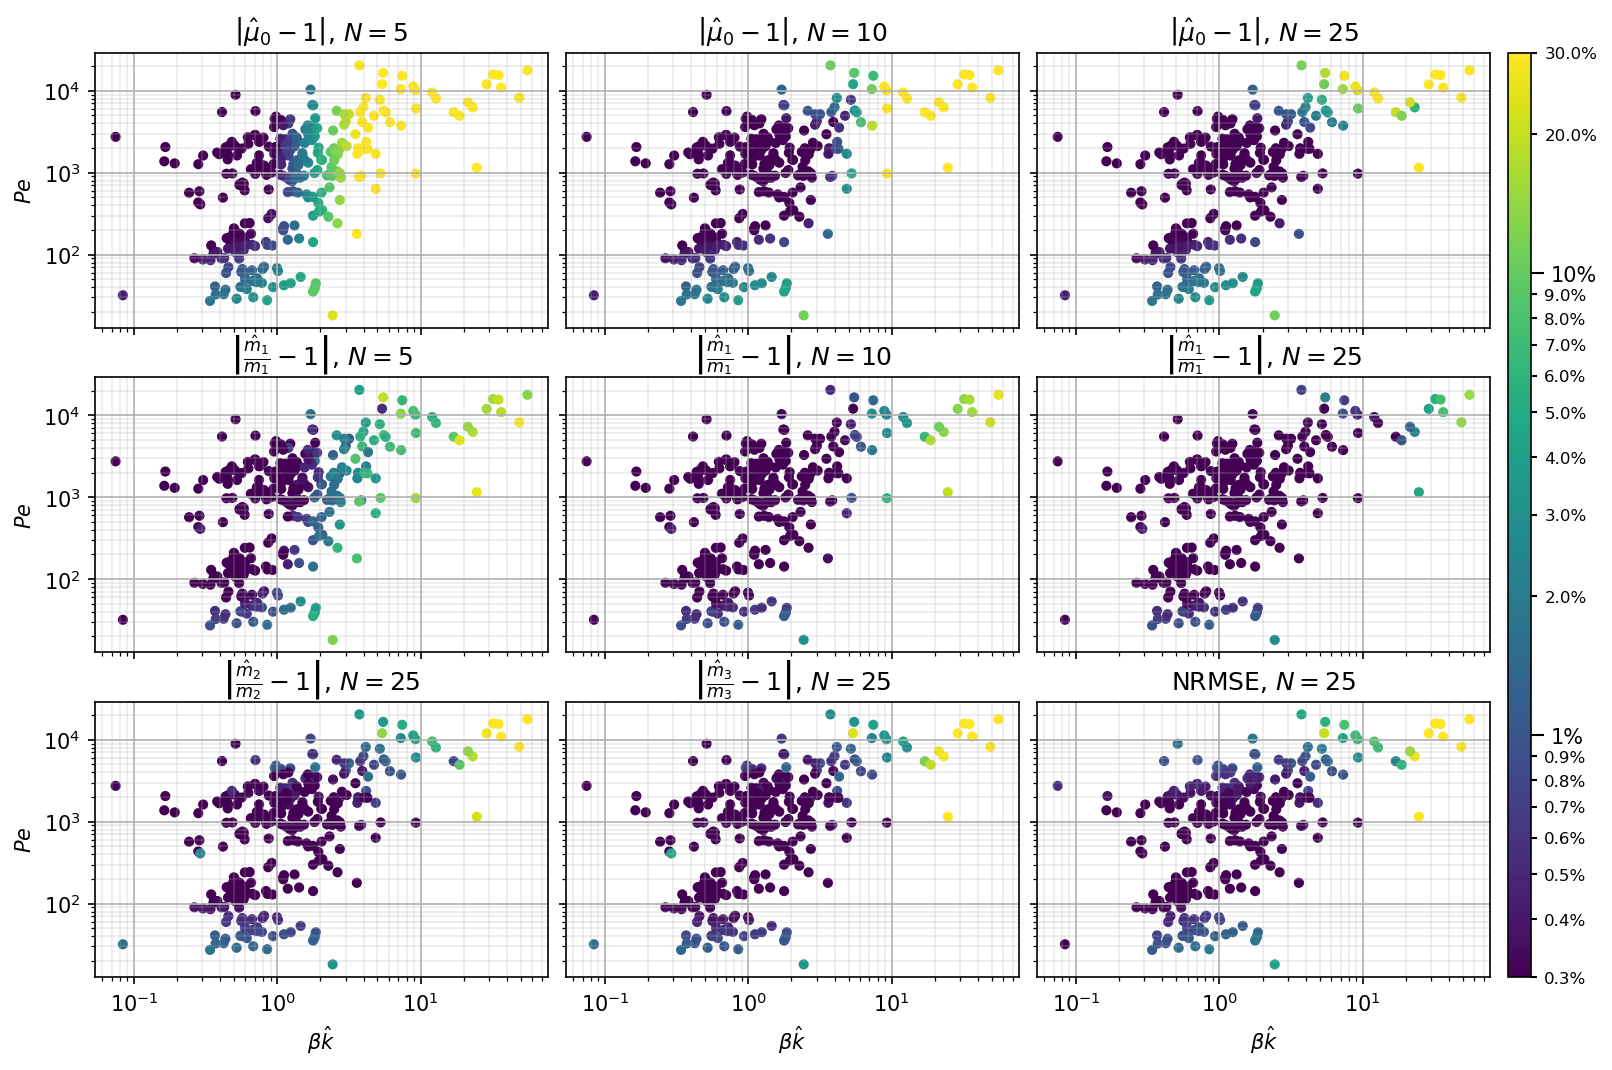

In [178]:
fig, axes = plt.subplots(ncols = 3, nrows = 3, figsize=(12, 8), sharex=True, sharey=True)
vmin = 0.3*10**-2
vmax = 0.3
k=0
for ii,i in enumerate([5,10,25]):
        ax = axes[k][ii]
        sc = ax.scatter((betas_est*krs_est),Pes_est,c = np.abs(moments_ratio[:,i-1,k]-1), norm = LogNorm(vmin=vmin, vmax=vmax),s = 15)
        # cbar = fig.colorbar(sc,pad = 0.01)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(r'$\beta \hat{k}$')
        ax.set_ylabel(r"$Pe$")
        ax.set_title(fr'$\left|\hat{{\mu}}_{{{0}}}-1\right|$, $N={i}$')
        ax.grid(which = 'major')
        ax.grid(which = 'minor', linewidth = 0.2)

k=1
for ii,i in enumerate([5,10,25]):
        ax = axes[k][ii]
        sc = ax.scatter((betas_est*krs_est),Pes_est,c = np.abs(moments_ratio[:,i-1,k]-1), norm = LogNorm(vmin=vmin, vmax=vmax),s = 15)
        # cbar = fig.colorbar(sc,pad = 0.01)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(r'$\beta \hat{k}$')
        ax.set_ylabel(r"$Pe$")
        ax.set_title(fr'$\left|\frac{{\hat{{m}}_{{{k}}}}}{{m_{{{k}}}}}-1\right|$, $N={i}$')
        ax.grid(which = 'major')
        ax.grid(which = 'minor', linewidth = 0.2)


i = 25
for ii,k in enumerate([2,3]):
    ax = axes[2][ii]
    sc = ax.scatter((betas_est*krs_est),Pes_est,c = np.abs(moments_ratio[:,i-1,k]-1), norm = LogNorm(vmin=vmin, vmax=vmax),s = 15)
    # cbar = fig.colorbar(sc,pad = 0.01)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta \hat{k}$')
    ax.set_ylabel(r"$Pe$")
    ax.set_title(fr'$\left|\frac{{\hat{{m}}_{{{k}}}}}{{m_{{{k}}}}}-1\right|$, $N={i}$')
    ax.grid(which = 'major')
    ax.grid(which = 'minor', linewidth = 0.2)

ax = axes[2][2]
sc = ax.scatter((betas_est*krs_est),Pes_est,c = NRMSEs2[:,-1], norm = LogNorm(vmin=vmin, vmax=vmax),s = 15)
# cbar = fig.colorbar(sc,pad = 0.01)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\beta \hat{k}$')
ax.set_ylabel(r"$Pe$")
ax.set_title(fr'NRMSE, $N={i}$')
ax.grid(which = 'major')
ax.grid(which = 'minor', linewidth = 0.2)

for ax in axes.flat:
    ax.label_outer()

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), orientation='vertical',anchor = (1.22, 0.5),aspect=40)


# 3. Configure Major Ticks & Labels
cbar.ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=[1.0]))
cbar.ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=0))

# 4. Configure Minor Ticks & Labels (Show .2, .4, .6, etc.)
cbar.ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
cbar.ax.yaxis.set_minor_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))

# 5. Fine-tune visual spacing and appearance
cbar.ax.tick_params(which='both', width=1)
cbar.ax.tick_params(which='major', length=6)
cbar.ax.tick_params(which='minor', length=3, labelsize=8)
plt.subplots_adjust(wspace=0.04, hspace=0.18) 
# plt.tight_layout()

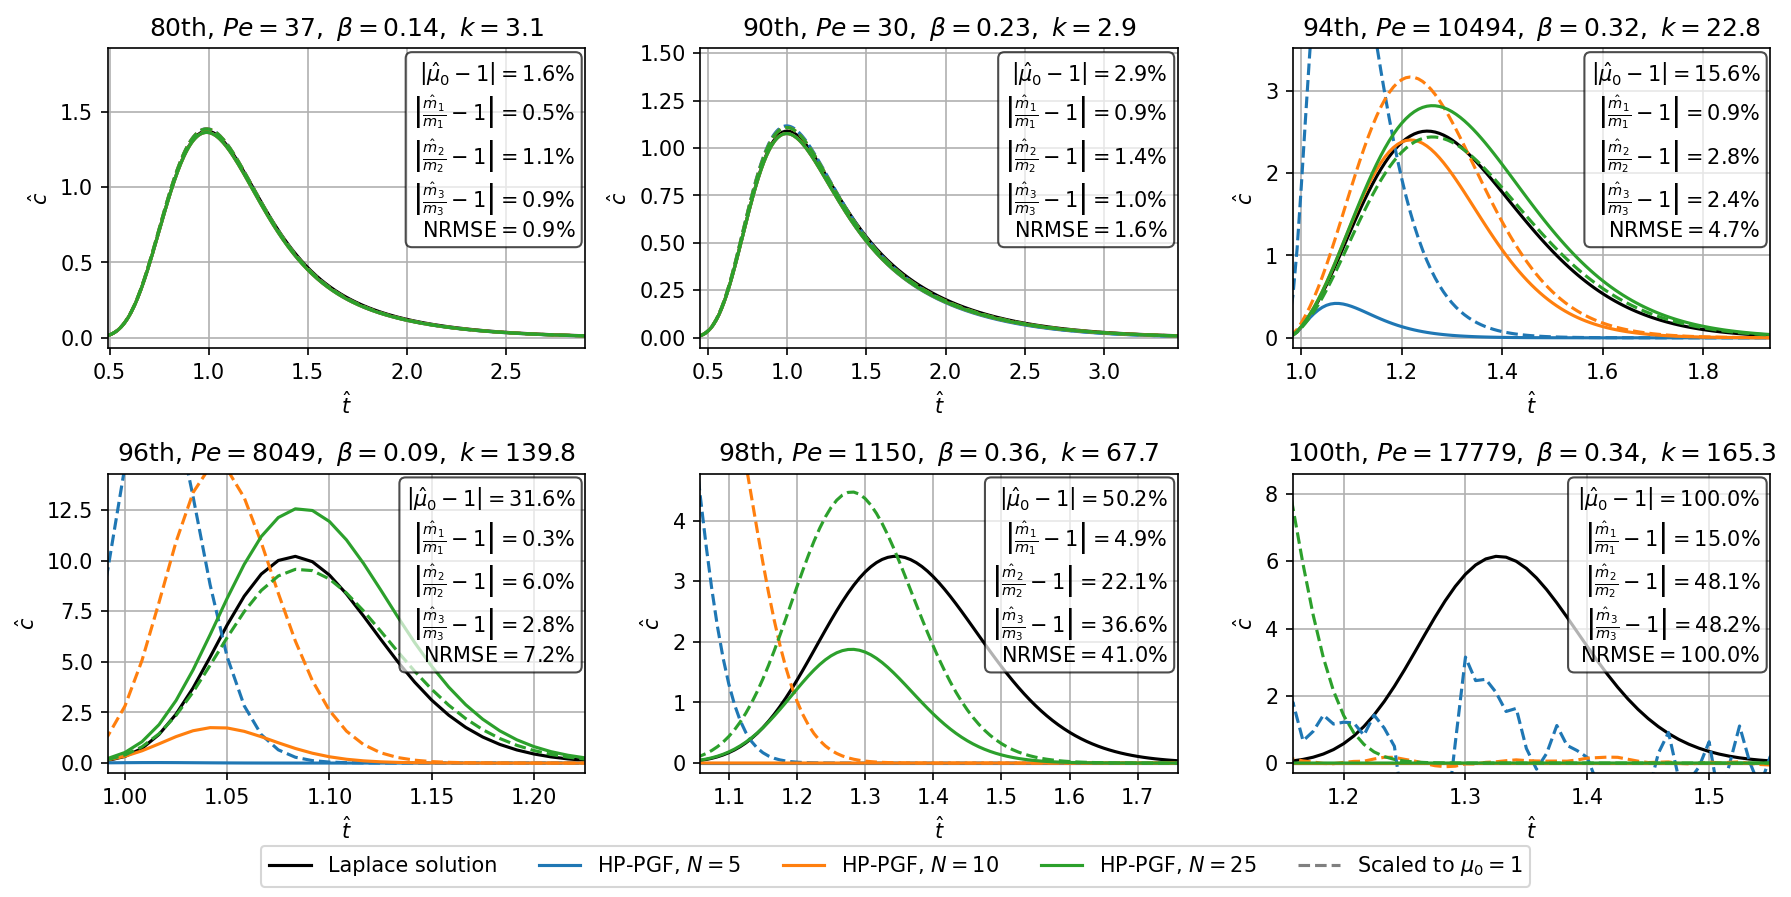

In [175]:
from matplotlib.lines import Line2D
n_cols = 3
n_rows = 2
fig, ax = plt.subplots(ncols = n_cols, nrows = n_rows,figsize=(12, 6))
n_plot = n_rows*n_cols
percentiles = np.array([0.8,0.9,0.94,0.96,0.98,1.0])
ind_plots = np.argsort(NRMSEs2[:,-1])[np.argmin(np.abs(percentiles*(len(output2)-1)-np.arange(0,len(output2))[:,None]),axis = 0)]#[np.argmin(np.abs(np.linspace(0,len(output2)-1,n_plot)-np.arange(0,len(output2))[:,None]),axis = 0)]

for ii,i in enumerate(ind_plots):
    if exchange == 'first order':
        btc_lap = ADEMF_1D(np.linspace(0,T_, Nt_+1)[1:], [1.0], 1.0, Pes_est[i], betas_est[i], [krs_est[i],krs_est[i]], exchange, 'infinite')[:,-1]
    if exchange == 'gamma':
        btc_lap = ADEMF_1D(np.linspace(0,T_, Nt_+1)[1:], [1.0], 1.0, Pes_est[i], betas_est[i], [krs_est[i]/eta,eta], exchange, 'infinite')[:,-1]
    ax[ii//n_cols][ii%n_cols].plot(t_,btc_lap, c = 'k')
    for nn,n in enumerate([4,9,24]):
        ax[ii//n_cols][ii%n_cols].plot(t_,np.sum(output2[i][1][:n,1:,-1],axis = 0),c=['tab:blue','tab:orange','tab:green'][nn])
        ax[ii//n_cols][ii%n_cols].plot(t_,np.sum(output2[i][1][:n,1:,-1],axis = 0)/np.trapezoid(np.sum(output2[i][1][:n,1:,-1],axis = 0),t_),c=['tab:blue','tab:orange','tab:green'][nn], linestyle = 'dashed')
    ax[ii//n_cols][ii%n_cols].set_xlim(t_[btc_lap>np.max(btc_lap)*0.01][0],t_[btc_lap>np.max(btc_lap)*0.01][-1])
    ax[ii//n_cols][ii%n_cols].set_ylim(np.max(btc_lap)*-0.05,np.max(btc_lap)*1.4)
    ax[ii//n_cols][ii%n_cols].grid()
    ax[ii//n_cols][ii%n_cols].set_title(fr"{int(100*percentiles[ii])}th, $Pe={Pes_est[i]:.0f},\ \beta={betas_est[i]:.2f},\ k={krs_est[i]:.1f}$")
    ax[ii//n_cols][ii%n_cols].text(
    0.98, 0.96,                  # x, y in axes fraction coordinates
    r'$\left|\hat{\mu}_{0}-1\right|='+format(100*np.abs(moments_ratio[i,-1,0]-1),'.1f')+r'\%$' 
        +'\n'+ '\n'.join([fr'$\left|\frac{{\hat{{m}}_{{{jj+1}}}}}{{m_{{{jj+1}}}}}-1\right|='+format(100*j,'.1f')
                          +r'\%$' for jj,j in enumerate(np.abs(moments_ratio[i,-1,1:-1]-1))])+'\n '+fr'$\text{{NRMSE}}={100*NRMSEs2[i][-1]:.1f}\%$',
    transform=ax[ii//n_cols][ii%n_cols].transAxes,      # interpret coords in axes [0,1] system
    ha="right", va="top",         # align to top-left corner
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7)
)
    ax[ii//n_cols][ii%n_cols].set_xlabel(r'$\hat{t}$')
    ax[ii//n_cols][ii%n_cols].set_ylabel(r'$\hat{c}$')

fig.legend(handles=[
        plt.Line2D([0], [0], color="k", label="Laplace solution"),
        plt.Line2D([0], [0], color="tab:blue", label="HP-PGF, $N = 5$"),
        plt.Line2D([0], [0], color="tab:orange", label="HP-PGF, $N = 10$"),
        plt.Line2D([0], [0], color="tab:green", label="HP-PGF, $N = 25$"),
        plt.Line2D([0], [0], color="gray", linestyle = 'dashed' , label=r"Scaled to $\mu_{0} = 1$")], loc="lower center", ncol=5)
plt.tight_layout(rect=[0,0.03,1,1])

# Phase Exposure Dependent

In [14]:
exchange = 'first order'
bound_cond = 'infinite'    

In [15]:

def run_PhEDEx2(Pe,beta,k, D_fac, kappa, a,initial = 'uniform', T_ = 3, N_terms = 5,Nx_ = 120, extra_left = 50):
    
    params = [Pe,beta,k, D_fac, kappa, a]
    Nt_ = int(T_*Nx_)
    deltax_ = Pe/Nx_
    deltat_ = T_*Pe/Nt_
    extra_left_points = min((int(extra_left//(Pe/Nx_)))//2*2+2,Nx_)
    x_s = np.linspace(-extra_left_points*deltax_,Pe, extra_left_points+Nx_+1)
    t_s = np.linspace(0,T_*Pe, Nt_+1)
    t_s_ker = np.linspace(-T_*Pe,T_*Pe, 2*Nt_+1)
    x_s_ker = np.linspace(-Pe,Pe, 2*Nx_+1)
    C0_2D = ADE_forced_analytical_derived_params(x_s,t_s,deltax_,deltat_,beta*k/Pe, D_fac, kappa, a, initial)
    Ci_3D = np.zeros((N_terms,Nt_+1,Nt_+1,extra_left_points+Nx_+1))
    Ci_3D[0,np.arange(Nt_+1),np.arange(Nt_+1),:] = C0_2D/deltat_
    kernel_C = ADE_forced_analytical_derived_params(x_s_ker,t_s,deltax_,deltat_,beta*k/Pe, D_fac, kappa, a, 'bound')/(deltat_)
    if initial == 'uniform':
        k_f_initial = (np.interp(t_s/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,k_effs_uniform,right = 1.0)*(1-kappa)+kappa)*k
    if initial == 'central':
        k_f_initial = (np.interp(t_s/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,k_effs_central,right = 1.0)*(1-kappa)+kappa)*k
    k_f_bound = (np.interp(t_s/((1-D_fac)*6*(a+3)*(2*a+3)),thetas,k_effs_bound,right = 1.0)*(1-kappa)+kappa)*k
    
    nfft = 2*(Nt_+1)  # zero pad to avoid circular wrap
    freqs = 2*np.pi*np.fft.fftfreq(nfft, d=deltat_)  # angular frequencies
    # frequency response of kernel
    if exchange == 'first order':
        H = 1 / (1j*freqs + k/Pe)   # same shape as freqs
    if exchange == 'gamma':
        H = []
        for w in freqs:
            iw = 1j * w
            val = complex(expint(2+eta, iw*Pe/gamma_hat))
            H.append(Pe/gamma_hat*(1 + eta)/eta*val*np.exp(iw*Pe/gamma_hat))
        H = np.array(H, dtype=np.complex128)
    
    for n in range(N_terms-1):
        if n == 0:
            k_f_ = k_f_initial
        else:
            k_f_ = k_f_bound
        C_int = np.trapezoid(k_f_[None,:,None]*Ci_3D[n],t_s,axis = 1)
        
        
        rhSi = beta*k/Pe*C_int
        frhSi = np.fft.fft(rhSi, nfft, axis = 0)
        fS = frhSi * H[:,None]
        fi = np.fft.ifft(fS, axis = 0).real[:Nt_+1]
        
        for i in range(Nt_+1):
            for j in range(i+1):
                Ci_3D[n+1,i,i-j] = signal.fftconvolve(fi[j],kernel_C[i-j], mode = 'same')*deltax_/(k/Pe*Nx_)
    Ci_2D = np.trapezoid(Ci_3D,t_s, axis = 2)
    print(params)
    C2Ds = np.sum([C*params[0]*(params[2]/params[0])**(n) for n,C in enumerate(Ci_2D)],axis = 0)
    return x_s/Pe,t_s/Pe,C2Ds

In [74]:
np.log10(np.percentile(beta_kf_est,[10,90])),np.log10(np.percentile(krs_est,[10,90]))

(array([-0.36102742,  0.65857098]), array([0.49401956, 1.6627985 ]))

In [75]:
def rand_params(seed):
    np.random.seed(seed)
    Pe = 10**(np.random.uniform(1.8,3.3))#10**(np.random.uniform(3,3.4))
    betak = 10**(np.random.uniform(-1.5,0.0))
    k = 10**(np.random.uniform(0.5,1.8))
    D_fac = 10**np.random.uniform(-2.0,0.0)
    kappa = 10**np.random.uniform(-2.0,0.0)
    a = np.random.uniform(1.0,6.0)
    beta = betak/k
    return Pe,beta,k,D_fac,kappa,a

In [191]:
%%time
output_PhEDEx2 = [run_PhEDEx2(Pe,beta,k,D_fac,kappa,a) for Pe,beta,k,D_fac,kappa,a in [rand_params(seed) for seed in range(100)]]

[419.97192208100034, 0.019462187876560975, 19.212876401177883, 0.12296071107325704, 0.07035737028722146, 4.229470565333281]
[266.39925566372443, 0.12032006362473407, 3.1633604989468522, 0.04024066464714609, 0.019656753051200317, 1.461692973843989]
[284.4411024387639, 0.0021102219031257897, 16.38933080677348, 0.07424116619296475, 0.06930037811020538, 2.651674105019371]
[422.8602418647689, 0.048310949519662826, 7.553985738814667, 0.10511270449351966, 0.610792799614582, 5.48146544466719]
[1780.5113994410272, 0.0036004659309592725, 58.141959993074735, 0.2689255016027697, 0.24857511510709868, 2.080447477901882]
[135.82814094845807, 0.10898420419715489, 5.871308520890452, 0.6874194498027419, 0.09480306482679782, 4.058719314513229]
[1378.1301280009325, 0.0026938403141301345, 36.94858915747406, 0.012116948204672058, 0.016417739478477446, 3.975260321031201]
[82.12255147642637, 0.039805784498988625, 11.7471361119394, 0.2798532505338012, 0.9036058293737204, 3.6924793520521684]
[1288.6770794779395

KeyboardInterrupt: 

In [922]:
Ci_2Ds = [out[1] for out in output_PhEDEx2]
params = np.array([out[0] for out in output_PhEDEx2])
C2Ds = [np.sum([C*param_[0]*(param_[2]/param_[0])**(n) for n,C in enumerate(Ci_2D)],axis = 0) for Ci_2D,param_ in zip(Ci_2Ds,params)]

In [923]:
index_ = 86
Pe,beta,k = params[index_][:3]

In [924]:
Ci_2D = Ci_2Ds[index_]

In [925]:
x_ss = [np.linspace(-min((int(extra_left//(Pe/Nx_)))//2*2+2,Nx_)*Pe/Nx_,Pe, min((int(extra_left//(Pe/Nx_)))//2*2+2,Nx_)+Nx_+1)/Pe for Pe in params[:,0]]

In [926]:
C2D = np.sum([C*Pe*(k/Pe)**(n) for n,C in enumerate(Ci_2D)],axis = 0)

In [927]:
out = run_TSM([Pe,beta,k],'infinite',Nx_,T_,N_terms,extra_left,exchange = exchange)

TypeError: 'float' object cannot be interpreted as an integer

0.9448884742372109
0.05121209219024851
0.003756757329872959
0.0002609639378363549
1.7302289716324032e-05


(0.5, 2.0)

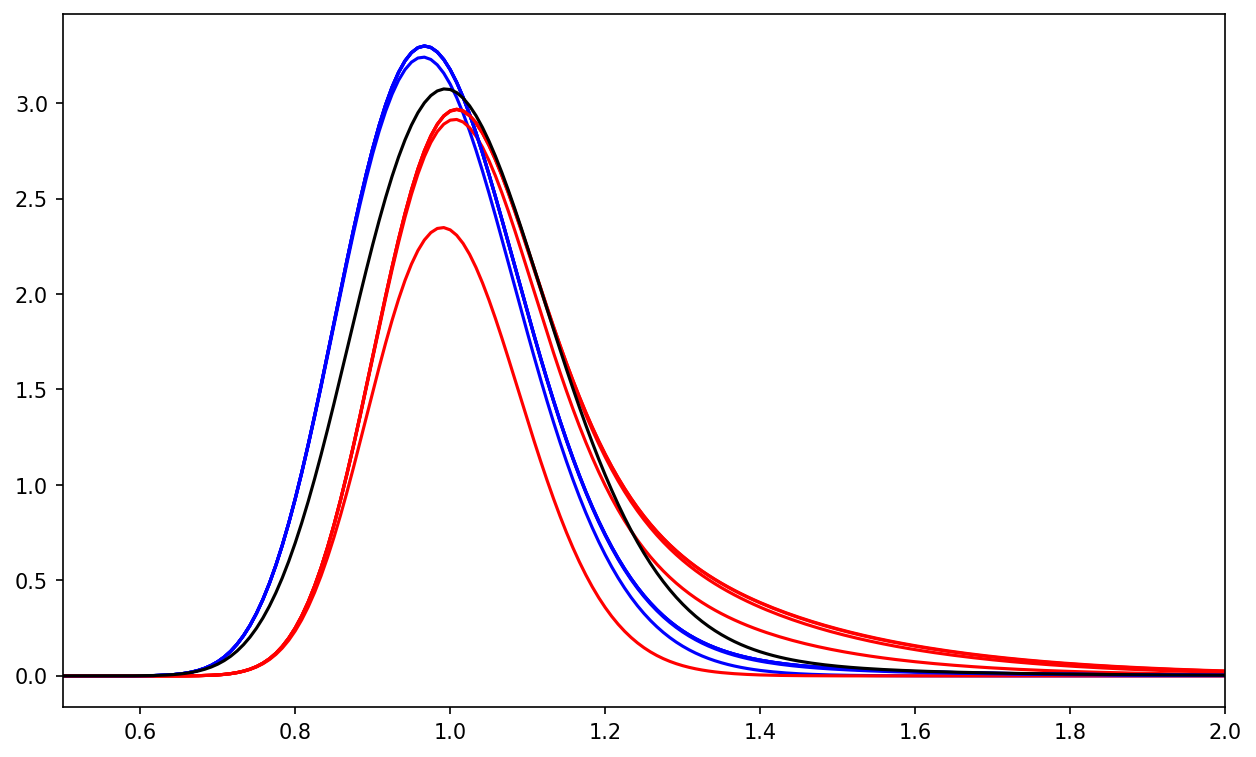

In [928]:
t_ = np.linspace(0,T_,Nt_+1)
for N in range(N_terms):
    btc = np.sum([C*Pe*(k/Pe)**(n) for n,C in enumerate(Ci_2D[:N+1])],axis = 0)[:,-1]
    # btc = (Ci_2D[N]*Pe*(k/Pe)**(N))[:,-1]
    plt.plot(t_,btc,c = 'b')
    plt.plot(t_,np.sum(out[1][:N+1][:,:,-1],axis =0),c = 'r')
    print(np.trapezoid((Ci_2D[N]*Pe*(k/Pe)**(N))[:,-1],t_))
plt.plot(t_[1:],ADEMF_1D(np.linspace(0,T_, Nt_+1)[1:], [1.0], 1.0, Pe, beta, [k,k], exchange, 'infinite')[:,-1],c = 'k')
plt.xlim(0.5,2.0)

IndexError: boolean index did not match indexed array along dimension 0; dimension is 151 but corresponding boolean dimension is 169

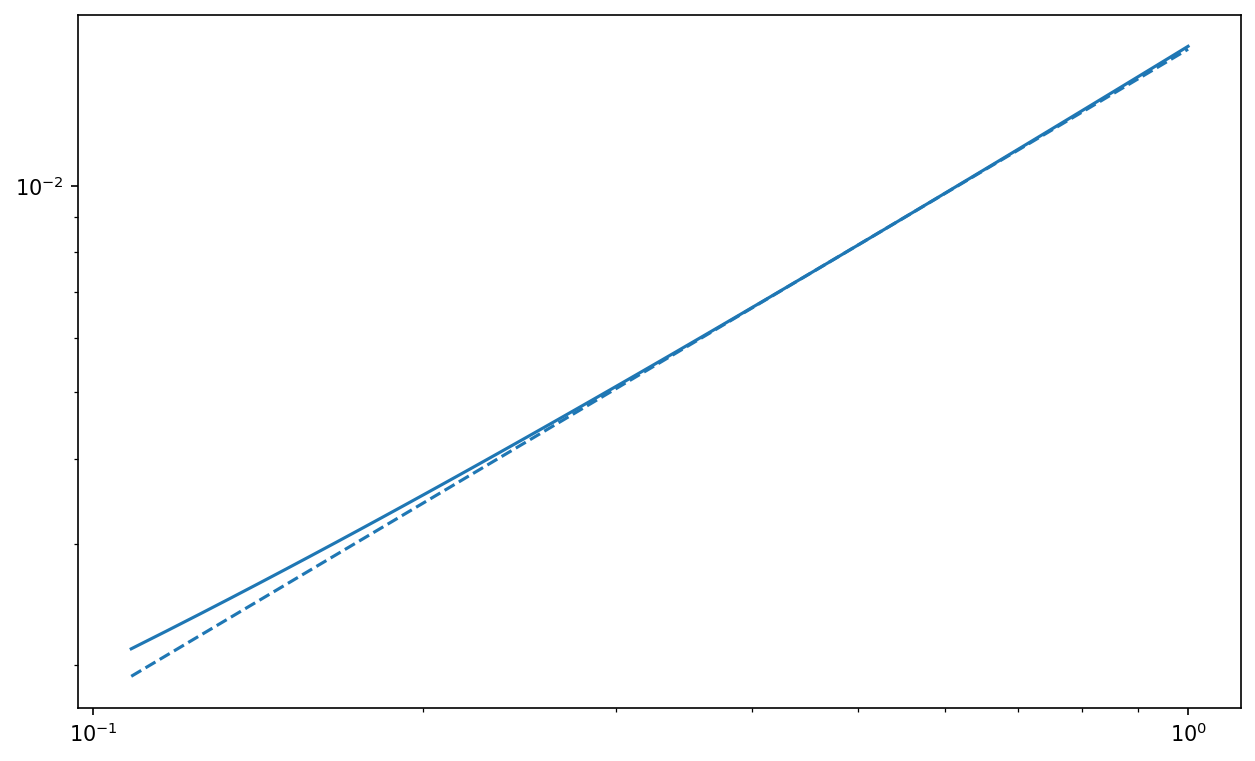

In [929]:
Pe = params[index_][0]
deltax_ = Pe/Nx_
deltat_ = T_*Pe/Nt_
extra_left_points = min((int(extra_left//deltax_))//2*2+2,Nx_)
x_s = np.linspace(-extra_left_points*deltax_,Pe, extra_left_points+Nx_+1)
t_s = np.linspace(0,T_*Pe, Nt_+1)
x_ = x_s/Pe
C_fields = [ADE_analytical_derived_params(x_s, t_s, 0.99,1.0,'center')*Pe,
            np.sum(out[1],axis = 0),
            # ADE_analytical_derived_params(x_s, t_s, params[0][3], params[0][5],'center')*Pe,
            ADE_analytical_derived_params(x_s, t_s, params[0][3],3.8,'center')*Pe,
            C2D]
labels = ['ADE','PhEDEx','Time dependent ADE', 'PhEDEx2']
for i,C_field in enumerate(C_fields):
    m1_s = (np.trapezoid(C_field*t_[:,None],t_s/Pe,axis = 0))/np.trapezoid(C_field,t_,axis = 0)
    m2_s = (np.trapezoid(C_field*(t_[:,None]-m1_s[None,:])**2,t_s/Pe,axis = 0))/np.trapezoid(C_field,t_s/Pe,axis = 0)
    m3_s = (np.trapezoid(C_field*(t_[:,None]-m1_s[None,:])**3,t_s/Pe,axis = 0))/np.trapezoid(C_field,t_s/Pe,axis = 0)
    x__ = x_[x_>=0.1]
    CV_sq_ = m2_s[x_>=0.1]/m1_s[-1]
    i_0_5 = np.argmin(np.abs(x__-0.5))
    slope_0_5 = np.gradient(np.log(CV_sq_),np.log(x__))[i_0_5]
    plt.loglog(x__,CV_sq_,label = labels[i], c = colors[i])
    plt.loglog(x__,(x__/x__[i_0_5])**(slope_0_5)*CV_sq_[i_0_5], c = colors[i], linestyle = 'dashed', label = fr'$\propto x^{{{round(slope_0_5,3)}}}$')
plt.legend()
plt.grid()
plt.grid(which = 'minor', linewidth = 0.2)
plt.scatter(np.array(xs_m_ttl[i_ttl])/xs_m_ttl[i_ttl][-1],var_m_ttl[i_ttl]/m1_m_ttl[i_ttl][-1]**2)
plt.ylim(10**-4,10**-1)
plt.xlim(0.1,1)

In [ ]:
for i,C_field in enumerate(C_fields):
    m1_s = (np.trapezoid(C_field*t_[:,None],t_s/Pe,axis = 0))/np.trapezoid(C_field,t_,axis = 0)
    m2_s = (np.trapezoid(C_field*(t_[:,None]-m1_s[None,:])**2,t_s/Pe,axis = 0))/np.trapezoid(C_field,t_s/Pe,axis = 0)
    m3_s = (np.trapezoid(C_field*(t_[:,None]-m1_s[None,:])**3,t_s/Pe,axis = 0))/np.trapezoid(C_field,t_s/Pe,axis = 0)
    x__ = x_[x_>=0.1]
    CSK = m3_s[x_>=0.1]/m2_s[x_>=0.1]**(3/2)
    i_0_5 = np.argmin(np.abs(x__-0.5))
    slope_0_5 = np.gradient(np.log(CSK),np.log(x__))[i_0_5]
    plt.loglog(x__,CSK,label = labels[i], c = colors[i])
    plt.loglog(x__,(x__/x__[i_0_5])**(slope_0_5)*CSK[i_0_5], c = colors[i], linestyle = 'dashed', label = fr'$\propto x^{{{round(slope_0_5,3)}}}$')
plt.legend()
plt.grid()
plt.grid(which = 'minor', linewidth = 0.2)
plt.ylim(0.01,10.0)
plt.scatter(np.array(xs_m_ttl[i_ttl])[1:]/xs_m_ttl[i_ttl][-1],csks_m_ttl[i_ttl][1:])

IndexError: boolean index did not match indexed array along dimension 0; dimension is 151 but corresponding boolean dimension is 169

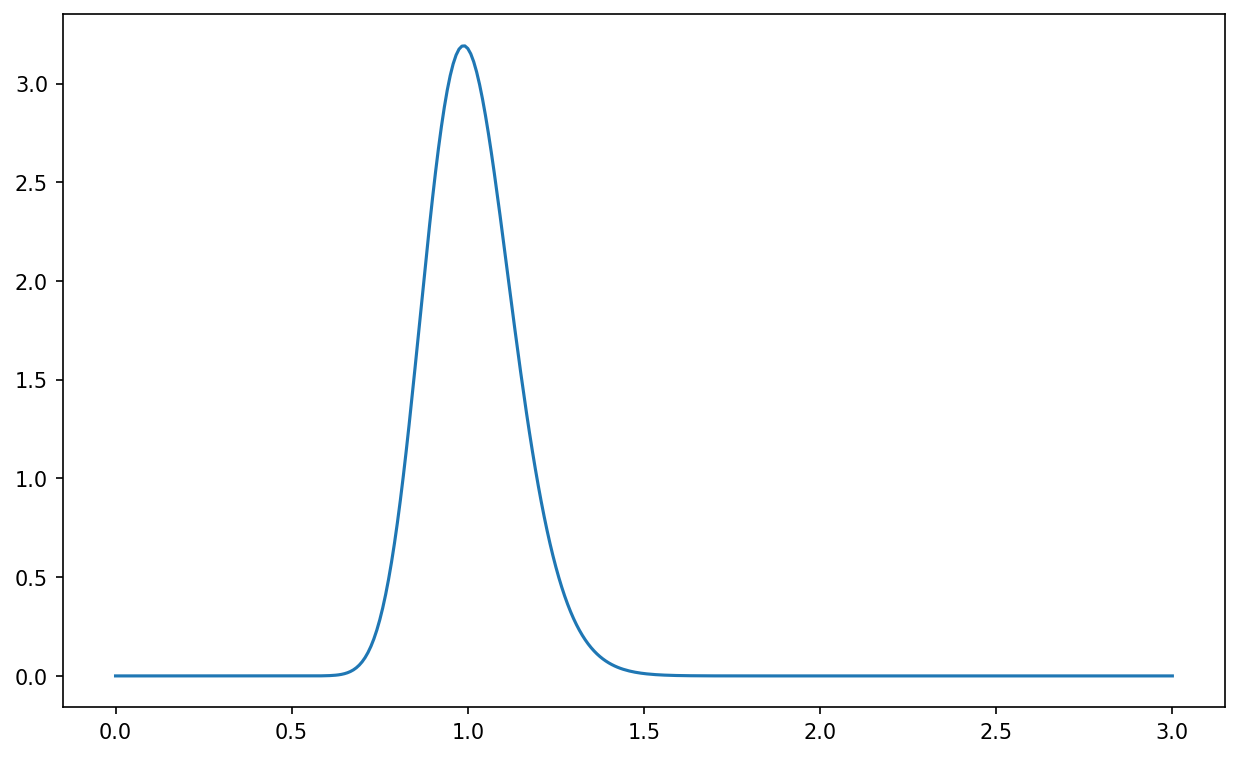

In [930]:
for i,C_field in enumerate(C_fields):
    m1_s = (np.trapezoid(C_field*t_[:,None],t_s/Pe,axis = 0))/np.trapezoid(C_field,t_,axis = 0)
    m2_s = (np.trapezoid(C_field*(t_[:,None]-m1_s[None,:])**2,t_s/Pe,axis = 0))/np.trapezoid(C_field,t_s/Pe,axis = 0)
    m3_s = (np.trapezoid(C_field*(t_[:,None]-m1_s[None,:])**3,t_s/Pe,axis = 0))/np.trapezoid(C_field,t_s/Pe,axis = 0)
    x__ = x_[x_>=0.1]
    m2_s_ = m2_s[x_>=0.1]
    i_0_5 = np.argmin(np.abs(x__-0.5))
    slope_0_5 = np.gradient(np.log(m2_s_),np.log(x__))[i_0_5]
    plt.plot(t_,C_field[:,-1],label = labels[i]+fr', $CSK={round(m3_s[-1]/m2_s[-1]**(3/2),2)}$', c = colors[i])
plt.legend()
plt.grid()
plt.grid(which = 'minor', linewidth = 0.2)
plt.xlim(0.7,2.0)

## Real data

### Plots

In [16]:
def load_btcs(file_path, T_, complete_zeros, min_dimless_res = None):
    """
    Parses and processes breakthrough curve (BTC) data from a CSV file.
    
    The function extracts time series and concentration data for multiple BTCs 
    from a structured CSV file. It filters BTCs based on specific metadata conditions 
    and optionally extends 
    each BTC with zero-padding before and after the observed data 
    to ensure consistent temporal coverage.
    
    Parameters:
        file_path (str): Path to the CSV file containing BTC data in a tabular format.
        complete_zeros (bool): If True, extends the BTCs with zero values before and after 
                               the observation period using interpolation. If False, returns 
                               the trimmed, background-corrected data.
    
    Returns:
        n_btcs (int): Number of valid BTCs processed.
        ts_m (list of np.ndarray): Time arrays for each BTC (possibly extended).
        btcs_m (list of np.ndarray): Concentration arrays for each BTC, background-corrected.
        xs_m (list of float): Streamwise positions (or equivalent spatial data) for each BTC.
        names_list (list of str): List of BTC identifiers or names from the data.
    """
    
    with open(file_path, 'r') as file:
        data_reader = csv.reader(file)
        data_mat =  [[cell for cell in row] for row in data_reader]
        max_len = max(len(row) for row in data_mat)
        padded_data = [row + [''] * (max_len - len(row)) for row in data_mat]
        breakthrough_curves_data = [[[padded_data[i][i_btc*5+j] for i in range(len(padded_data))] for j in range(4)] for i_btc in range(len(padded_data[0])//5)]

    
    ts_m = [np.array([float(c) for c in btc[0][33:] if c!='']) for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    btcs_m = [np.array([float(c) for c in btc[1][33:] if c!='']) for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    xs_m = [btc[2][18] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    xs_m = [float(i) if i!='' else 0.0 for i in xs_m]
    background_cs_m = [btc[2][25] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    background_cs_m = [float(i) if i!='' else 0.0 for i in background_cs_m]
    names_list = [btc[0][31] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    n_btcs = len(ts_m)
    Bs_m = [btc[2][10] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    Bs_m = np.array([float(i) if i!='' else np.nan for i in Bs_m])
    Hs_m = [btc[2][11] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    Hs_m = np.array([float(i) if i!='' else np.nan for i in Hs_m])
    Us_m = [btc[2][3] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    Us_m = np.array([float(i) if i!='' else np.nan for i in Us_m])
    u_stars_m = [btc[2][4] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    u_stars_m = np.array([float(i) if i!='' else np.nan for i in u_stars_m])
    Qs_m = [btc[2][2] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    Qs_m = np.array([float(i) if i!='' else np.nan for i in Qs_m])
    
    for i_btc in range(n_btcs):
        if len(ts_m[i_btc])<len(btcs_m[i_btc]):
            btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
        if len(ts_m[i_btc])>len(btcs_m[i_btc]):
            ts_m[i_btc] = ts_m[i_btc][:len(btcs_m[i_btc])]
    
    if complete_zeros:
        ts_m_0 = []
        btcs_m_0 = []
        for i_btc in range(n_btcs):
            t,btc = ts_m[i_btc],btcs_m[i_btc]
            sorted_indices = np.argsort(t)
            t = t[sorted_indices]
            btc = btc[sorted_indices]
            t_unique,indices_unique = np.unique(t, return_index=True)
            if len(t_unique)!=len(t):
                btc_unique = np.zeros(len(indices_unique))
                for i in range(len(indices_unique)):
                    if i<len(indices_unique)-1:
                        btc_unique[i] = np.mean(btc[indices_unique[i]:indices_unique[i+1]])
                    else:
                        btc_unique[i] = np.mean(btc[indices_unique[i]:])
                t = t_unique
                btc = btc_unique
            deltat = np.max(t[1:]-t[:-1])
            t_ext = np.concatenate((np.arange(t[0],0,-deltat)[1:][::-1],t,np.arange(t[-1],T_*t[np.argmax(btc)],deltat)[1:]))
            btc_ext = np.interp(t_ext,t,btc-background_cs_m[i_btc],left = 0.0,right = 0.0)
            btc_ext = btc_ext
            ts_m_0.append(t_ext)
            btcs_m_0.append(btc_ext)    
    else:
        n_btcs, ts_m_0, btcs_m_0, xs_m, names_list = n_btcs, ts_m, [btcs_m[i_btc]-background_cs_m[i_btc] for i_btc in range(n_btcs)], xs_m, names_list
    
    return n_btcs, ts_m_0, btcs_m_0, xs_m, names_list, T_, Bs_m, Hs_m, Us_m, u_stars_m,Qs_m

In [17]:
Nt = 150
T_ = 4
n_btcs, ts_m, btcs_m, xs_m, names_list, T_, Bs_m, Hs_m, Us_m, u_stars_m, Qs_m = load_btcs('river_solute_tracer_data.csv',T_ = T_,complete_zeros = False, min_dimless_res = 1/Nt)

Text(0, 0.5, 'Number of breakthrough curves')

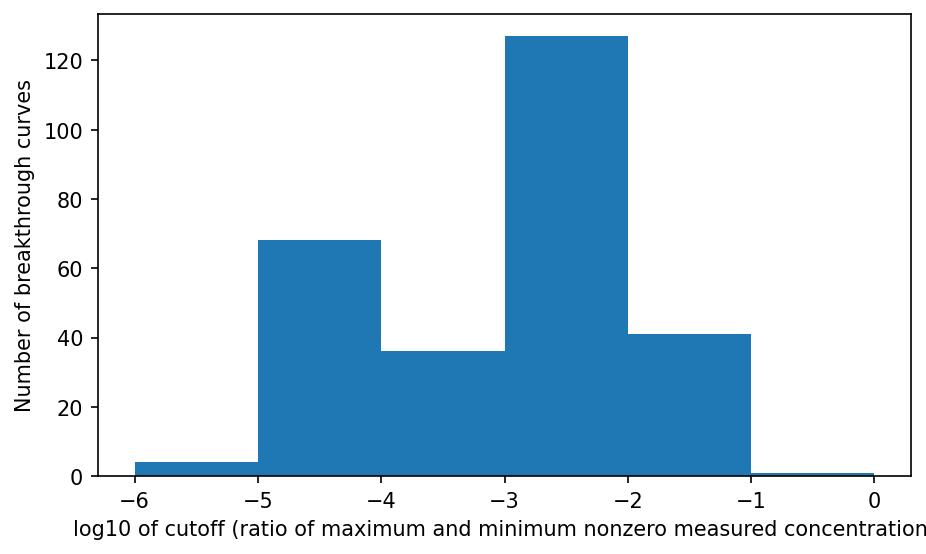

In [18]:
fig,ax = plt.subplots(figsize=(7,4))
ax.hist(np.log10([np.min(btc[btc>0])/np.max(btc) for btc in btcs_m]),bins = np.arange(-6,1))
ax.set_xlabel('log10 of cutoff (ratio of maximum and minimum nonzero measured concentration)')
ax.set_ylabel('Number of breakthrough curves')

(np.float64(3.7475921688723233), np.float64(0.7252983101767877))

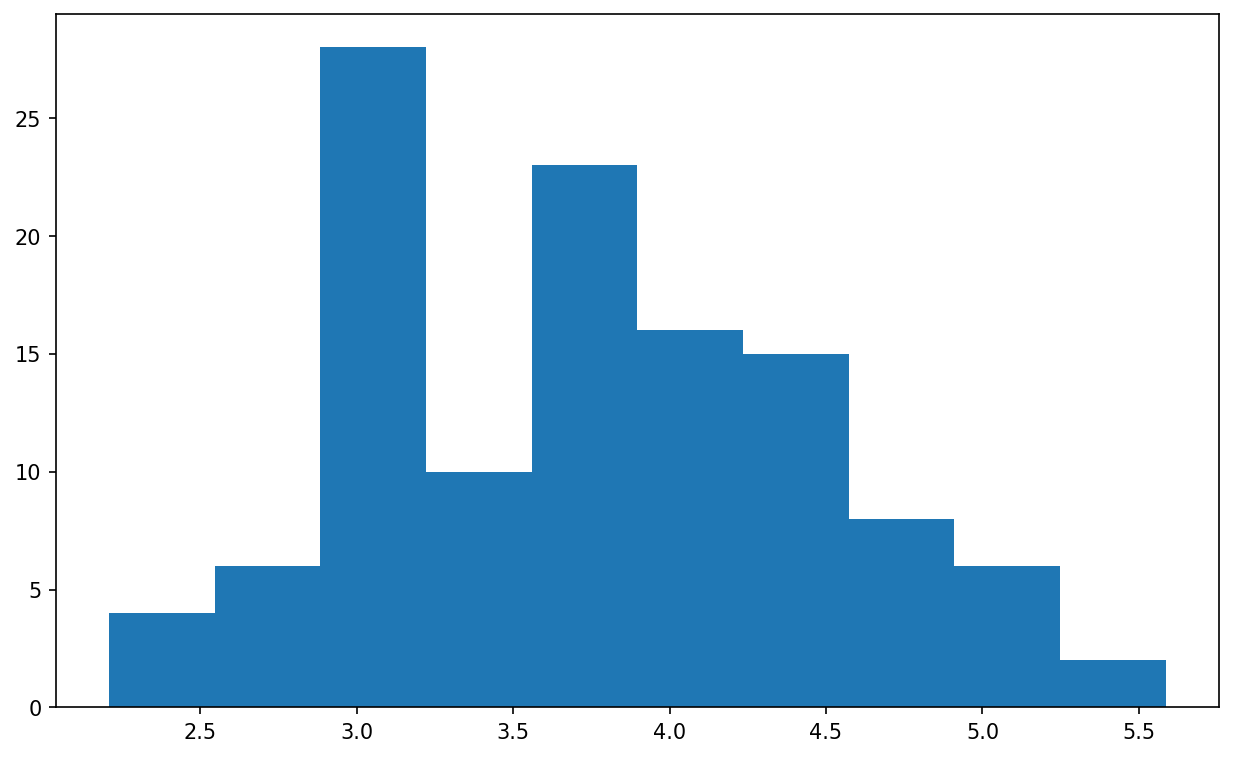

In [19]:
plt.hist(np.log(Bs_m/Hs_m))
np.nanmean(np.log(Bs_m/Hs_m)),np.nanvar(np.log(Bs_m/Hs_m),ddof = 1)**(1/2)

In [20]:
names_test,index_trac_test = np.unique([' '.join(name.split(' ')[:2])+(name[name.find('S')+1])*(name[name.find('S')+1]).isalpha() for name in names_list],return_inverse=True)
index_ttl = [np.arange(len(names_list))[index_trac_test==i] for i in set(index_trac_test)]

In [21]:
def m1_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    return m1
def cv_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    m2 = np.trapezoid(btc*(t-m1)**2,t)/np.trapezoid(btc,t)
    return m2**(1/2)/m1
def var_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    m2 = np.trapezoid(btc*(t-m1)**2,t)/np.trapezoid(btc,t)
    return m2
def csk_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    m2 = np.trapezoid(btc*(t-m1)**2,t)/np.trapezoid(btc,t)
    m3 = np.trapezoid(btc*(t-m1)**3,t)/np.trapezoid(btc,t)
    return m3/m2**(3/2)
def m3_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    m2 = np.trapezoid(btc*(t-m1)**2,t)/np.trapezoid(btc,t)
    m3 = np.trapezoid(btc*(t-m1)**3,t)/np.trapezoid(btc,t)
    return m3
def kurt_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    m2 = np.trapezoid(btc*(t-m1)**2,t)/np.trapezoid(btc,t)
    m3 = np.trapezoid(btc*(t-m1)**3,t)/np.trapezoid(btc,t)
    m4 = np.trapezoid(btc*(t-m1)**4,t)/np.trapezoid(btc,t)
    return m4/m2**(2)
def k4_f(t,btc):
    m1 = np.trapezoid(btc*t,t)/np.trapezoid(btc,t)
    m2 = np.trapezoid(btc*(t-m1)**2,t)/np.trapezoid(btc,t)
    m3 = np.trapezoid(btc*(t-m1)**3,t)/np.trapezoid(btc,t)
    m4 = np.trapezoid(btc*(t-m1)**4,t)/np.trapezoid(btc,t)
    return m4-3*m2**2

In [22]:
import numpy as np

def fit_exponential_tail(t, c):
    """
    Fit c(t) = A * exp(-lambda * t) using last 5 nonzero points.
    Returns A, lambda.
    """
    # Keep only nonzero values
    mask = c > 0
    t_nz = t[mask]
    c_nz = c[mask]

    if len(t_nz) < 5:
        return None, None

    # Take last 5 points
    t_tail = t_nz[-5:]
    c_tail = c_nz[-5:]

    # Fit log-linear: log(c) = log(A) - lambda t
    y = np.log(c_tail)
    X = np.vstack([np.ones_like(t_tail), -t_tail]).T

    coeffs, *_ = np.linalg.lstsq(X, y, rcond=None)
    logA, lambda_ = coeffs

    A = np.exp(logA)
    return A, lambda_


def compute_moments_with_tail(t, c, max_moment=2):
    """
    Compute temporal moments using numerical integration + exponential tail.
    """
    # Fit exponential tail
    A, lambda_ = fit_exponential_tail(t, c)

    if A is None:
        return None  # not enough data

    moments = []

    # Numerical part (up to last measurement)
    for p in range(max_moment + 1):
        m_num = np.trapezoid((t**p) * c, t)

        # Tail correction (analytical)
        t_end = t[-1]

        # Integral of t^p * A exp(-lambda t) from t_end to infinity
        # Use recursive formula or gamma function
        tail = 0.0
        for k in range(p + 1):
            tail += (sp.special.factorial(p) /
                     (sp.special.factorial(k) * lambda_**(p - k + 1))) * \
                    (t_end**k) * np.exp(-lambda_ * t_end)

        tail *= A

        moments.append(m_num + tail)

    return np.array(moments)

import numpy as np

def central_normalized_moments(raw_moments):
    """
    raw_moments: array [m0, m1, m2, m3, m4]
    returns: mean, variance, skewness, kurtosis
    """
    m0 = raw_moments[0]
    m1 = raw_moments[1]
    m2 = raw_moments[2]
    m3 = raw_moments[3] if len(raw_moments) > 3 else None
    m4 = raw_moments[4] if len(raw_moments) > 4 else None

    if m0 == 0:
        return {
        "mean": np.nan,
        "variance": np.nan,
        "skewness": np.nan,
        "kurtosis": np.nan
    }

    mu = m1 / m0

    # Central moments
    mu2 = m2 / m0 - mu**2

    if mu2 <= 0:
        return {
        "mean": np.nan,
        "variance": np.nan,
        "skewness": np.nan,
        "kurtosis": np.nan
    }  # avoid division issues

    sigma = np.sqrt(mu2)

    results = {
        "mean": mu,
        "variance": mu2,
    }

    if m3 is not None:
        mu3 = m3 / m0 - 3*mu*(m2/m0) + 2*mu**3
        skewness = mu3 / sigma**3
        results["skewness"] = skewness

    if m4 is not None:
        mu3 = m3 / m0 - 3*mu*(m2/m0) + 2*mu**3
        mu4 = (m4 / m0
               - 4*mu*(m3/m0)
               + 6*mu**2*(m2/m0)
               - 3*mu**4)
        kurtosis = mu4 / sigma**4
        results["kurtosis"] = kurtosis

    return results

def process_btcs(ts_m, btcs_m, max_moment=4):
    results = []

    for t, c in zip(ts_m, btcs_m):
        if len(t) < 10:
            raw_moments = np.zeros((max_moment+1))
            raw_moments[:]= np.nan
        else:
            raw_moments = compute_moments_with_tail(t, c, max_moment=max_moment)

        shape = central_normalized_moments(raw_moments)
        results.append({
            "raw_moments": raw_moments,
            "shape": shape
        })

    return results

In [23]:
skw_completed = np.array([i['shape']['skewness'] for i in process_btcs(ts_m, btcs_m, max_moment=3)])

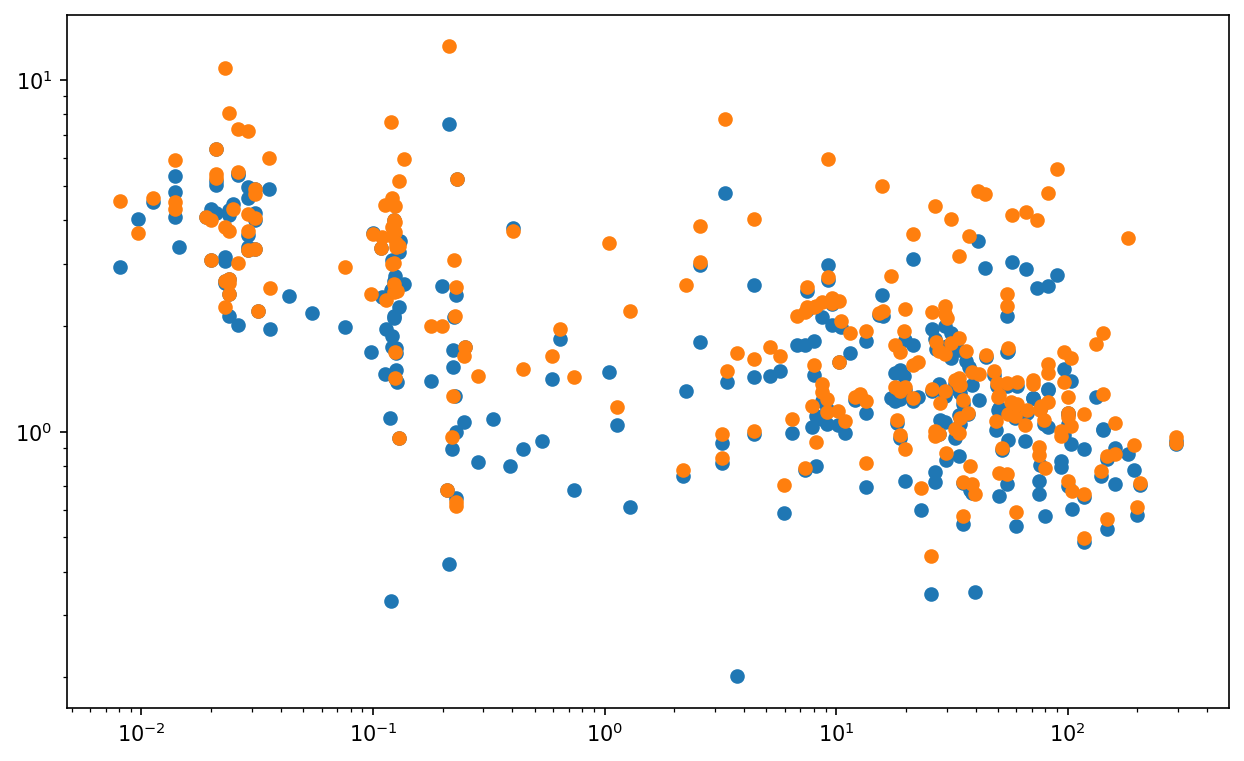

In [24]:
plt.scatter(xs_m,np.array([csk_f(ts_m[j],btcs_m[j]) for j in range(n_btcs)]))
plt.scatter(xs_m,skw_completed)
plt.xscale('log')
plt.yscale('log')

In [25]:
ts_m_ttl = [[ts_m[j] for j in i] for i in index_ttl]
btcs_m_ttl = [[btcs_m[j] for j in i] for i in index_ttl]
xs_m_ttl = [[xs_m[j] for j in i] for i in index_ttl]
covs_m_ttl = [[cv_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]
csks_m_ttl = [[csk_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]
kurt_m_ttl = [[kurt_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]
var_m_ttl = [[var_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]
m3_m_ttl = [[m3_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]
m1_m_ttl = [[m1_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]
m0_m_ttl = [[np.trapezoid(btcs_m[j],x = ts_m[j]) for j in i] for i in index_ttl]
Bs_m_ttl = [[Bs_m[j] for j in i] for i in index_ttl]
Hs_m_ttl = [[Hs_m[j] for j in i] for i in index_ttl]
Us_m_ttl = [[Us_m[j] for j in i] for i in index_ttl]
u_stars_m_ttl = [[u_stars_m[j] for j in i] for i in index_ttl]
Qs_m_ttl = [[Qs_m[j] for j in i] for i in index_ttl]
k4_m_ttl = [[k4_f(ts_m[j],btcs_m[j]) for j in i] for i in index_ttl]

In [26]:
Qs_m_ttl

[[np.float64(9.91089645),
  np.float64(7.3623802199999995),
  np.float64(8.919806805)],
 [np.float64(2.013327822),
  np.float64(2.568338023),
  np.float64(2.712753943),
  np.float64(2.712753943)],
 [np.float64(5.097032459999999),
  np.float64(5.238616695),
  np.float64(7.3623802199999995),
  np.float64(7.787132925),
  np.float64(10.194064919999999),
  np.float64(12.17624421),
  np.float64(12.74258115)],
 [np.float64(1.642377126), np.float64(1.783961361)],
 [np.float64(2.406931995),
  np.float64(2.435248842),
  np.float64(2.435248842),
  np.float64(3.96435858)],
 [np.float64(4.53069552),
  np.float64(5.323567236),
  np.float64(6.371290575),
  np.float64(6.51287481)],
 [np.float64(4.105942815),
  np.float64(4.81386399),
  np.float64(6.51287481),
  np.float64(8.098618242)],
 [np.float64(10.194064919999999),
  np.float64(10.363966),
  np.float64(10.50555024)],
 [np.float64(0.2835000313007782),
  np.float64(0.3160000348890508),
  np.float64(0.32800003621395146)],
 [np.float64(136.2040341),


0.004959762067818674 0.98
0.8389385122244527 1.57
0.9878529610773225 2.89
1.0 1.41
0.5947145583522839 1.72
0.9445628937907464 1.87
0.9831061833365844 2.04
0.99617294373057 1.03
0.8982937798986795 1.22
0.395306832106469 0.58
0.0 1.0
0.6428753368133808 1.39
0.9838796008489118 1.05
0.9175192338378134 1.04
0.6598624941460368 1.14
0.8323533029907874 1.24
0.8608688574749579 1.24
nan 2.0
nan 2.0
nan 2.0
nan 2.0
0.9198497464611213 1.17
0.0 1.0
0.7125163043259892 6.58
0.9099121456796729 1.76
0.9158425557172016 1.26
0.6361075475519846 1.3
0.7877988834090206 1.13
0.9705538149502464 1.21
0.9229031187061238 1.62
0.8871292315747213 1.43
0.8998779474429108 1.4
0.7985775389121526 1.08
0.903944640560018 1.66
0.9748118886286805 0.85
0.7731493064590003 1.73
0.0 1.0
0.19327099652192892 1.01
0.017127009986220965 1.02
0.1354788579678392 1.02
7.968624410659153e-06 1.0
0.9460260368416646 3.27
0.9710943566567223 3.32
0.33277698890601626 1.38
nan 2.0
nan 2.0
0.6051379401879147 1.21
0.058182590022078484 0.28


C:\Users\manue\AppData\Local\Temp\ipykernel_13992\3465023768.py:3: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(xs_m_ttl[i],Qs_m_ttl[i],1)
C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\3465023768.py:3: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(xs_m_ttl[i],Qs_m_ttl[i],1)
C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\3465023768.py:3: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(xs_m_ttl[i],Qs_m_ttl[i],1)
C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\sklearn\metrics\_regress

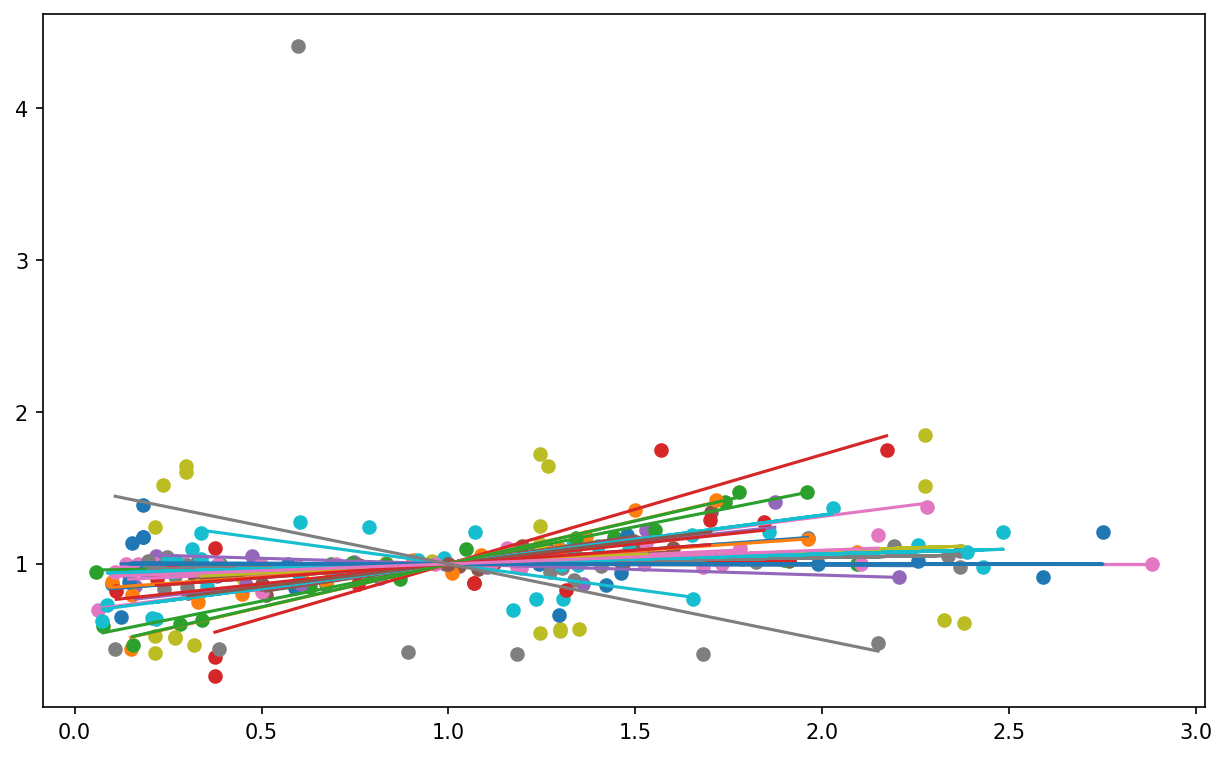

In [27]:
Q_est_change = []
for i in range(len(Qs_m_ttl)):
    a,b = np.polyfit(xs_m_ttl[i],Qs_m_ttl[i],1)
    print(r2_score(Qs_m_ttl[i],b+a*np.array(xs_m_ttl[i])),round((b+a*xs_m_ttl[i][-1])/b,2))
    Q_est_change.append((b+a*xs_m_ttl[i][-1])/b)
    plt.scatter(xs_m_ttl[i]/np.nanmean(xs_m_ttl[i]),Qs_m_ttl[i]/np.nanmean(Qs_m_ttl[i]))
    plt.plot(xs_m_ttl[i]/np.nanmean(xs_m_ttl[i]),(b+a*np.array(xs_m_ttl[i]))/np.nanmean(b+a*np.array(xs_m_ttl[i])))

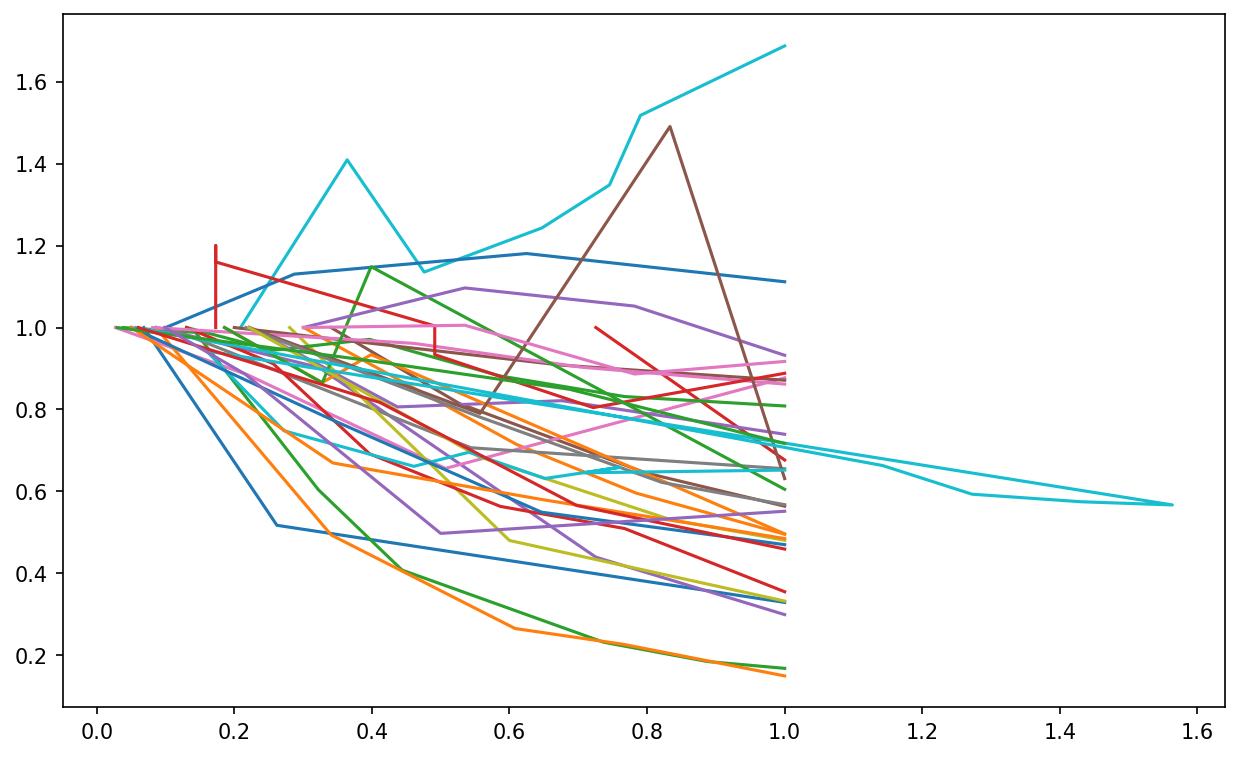

In [28]:
for i in range(35):
    plt.plot(np.array(xs_m_ttl[i])/xs_m_ttl[i][-1],m0_m_ttl[i]/m0_m_ttl[i][0])

In [29]:
m0_m_ttl

[[np.float64(170.4675), np.float64(88.18499999999999), np.float64(56.101)],
 [np.float64(117.435),
  np.float64(83.944655),
  np.float64(69.99499999999999),
  np.float64(58.19)],
 [np.float64(142.51000000000002),
  np.float64(140.84000000000003),
  np.float64(86.1297),
  np.float64(58.134499999999996),
  np.float64(33.032000000000004),
  np.float64(26.336000000000002),
  np.float64(23.9644)],
 [np.float64(33.96000000000001), np.float64(22.979999999999997)],
 [np.float64(108.83600000000001),
  np.float64(98.20999999999965),
  np.float64(47.84),
  np.float64(32.575480000000006)],
 [np.float64(65.47),
  np.float64(53.325),
  np.float64(42.233999999999995),
  np.float64(36.917500000000004)],
 [np.float64(154.51999999999995),
  np.float64(136.70999999999998),
  np.float64(101.38),
  np.float64(135.54)],
 [np.float64(2.637445),
  np.float64(1.8634650000000001),
  np.float64(1.7285199999999998)],
 [np.float64(3560.3512614889196),
  np.float64(1710.0990484379072),
  np.float64(1183.30340235955

C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2990203432.py:4: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(xs_m_ttl[i],m0_m_ttl[i],1)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2990203432.py:8: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(np.log(xs_m_ttl[i]),np.log(m0_m_ttl[i]),1)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2990203432.py:4: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(xs_m_ttl[i],m0_m_ttl[i],1)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2990203432.py:8: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(np.log(xs_m_ttl[i]),np.log(m0_m_ttl[i]),1)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2990203432.py:4: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(xs_m_ttl[i],m0_m_ttl[i],1)
C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2990203432.py:8: RankWarning: Polyfit may be poorly conditioned
  a,b = np.polyfit(np.log(xs_m_ttl[i]),np.log(m0_m_ttl

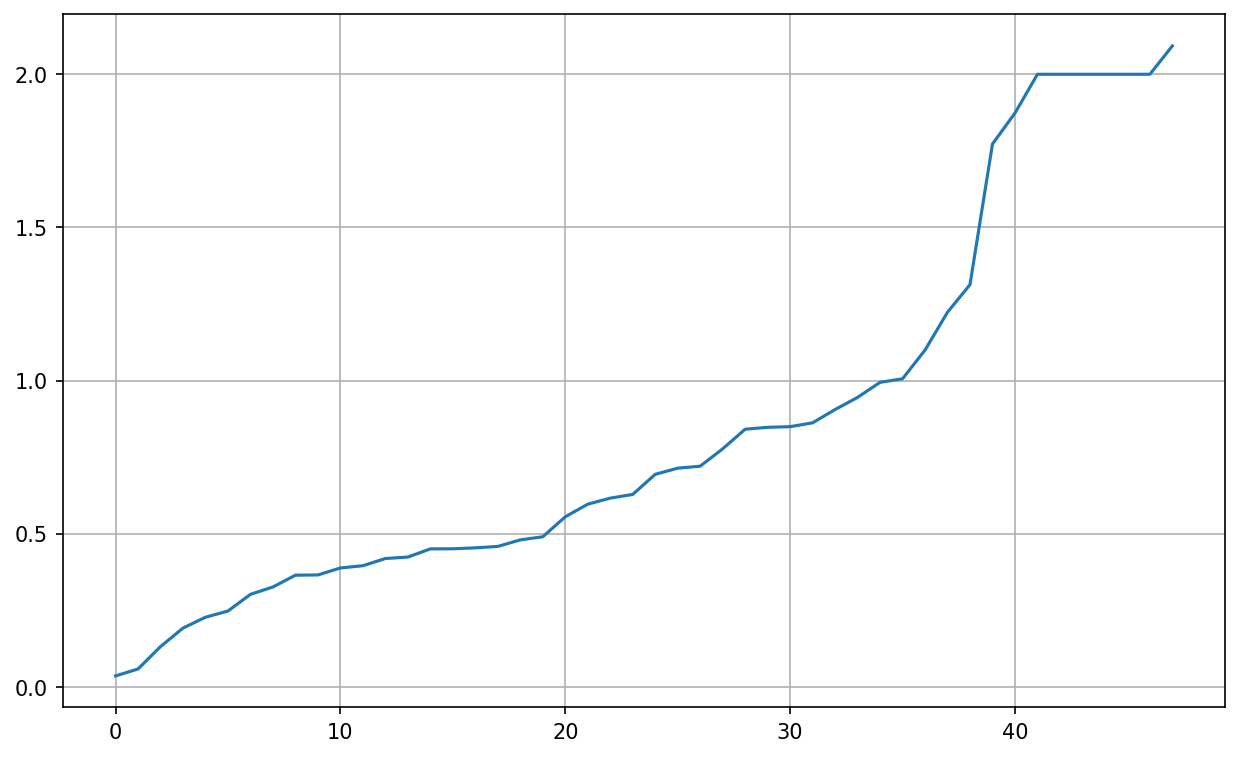

In [30]:
total_fitted_loss = np.zeros(len(index_ttl))
m0_slope_ttl = np.zeros(len(index_ttl))
for i in range(len(index_ttl)):
    a,b = np.polyfit(xs_m_ttl[i],m0_m_ttl[i],1)
    # plt.plot((xs_m_ttl[i]-np.min(xs_m_ttl[i]))/(np.max(xs_m_ttl[i])-np.min(xs_m_ttl[i])),np.array(m0_m_ttl[i])/np.mean(m0_m_ttl[i]))
    # plt.plot((xs_m_ttl[i]-np.min(xs_m_ttl[i]))/(np.max(xs_m_ttl[i])-np.min(xs_m_ttl[i])),(b+a*np.array(xs_m_ttl[i]))/np.mean(m0_m_ttl[i]), c = 'k', alpha = 0.3)
    total_fitted_loss[i] = (b+a*np.max(xs_m_ttl[i]))/b
    a,b = np.polyfit(np.log(xs_m_ttl[i]),np.log(m0_m_ttl[i]),1)
    m0_slope_ttl[i] = a
plt.plot(np.sort(total_fitted_loss))
np.percentile(total_fitted_loss,[25,50,75])
plt.grid()

C:\Users\manue\AppData\Local\Temp\ipykernel_13992\2630292642.py:14: RuntimeWarning: All-NaN slice encountered
  median_est_vels = np.nanmedian(est_vels_interp, axis = 0)
C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Text(0, 0.5, '$\\frac{v_{\\text{peak}}(x)}{v_{\\text{peak}}(L)}$')

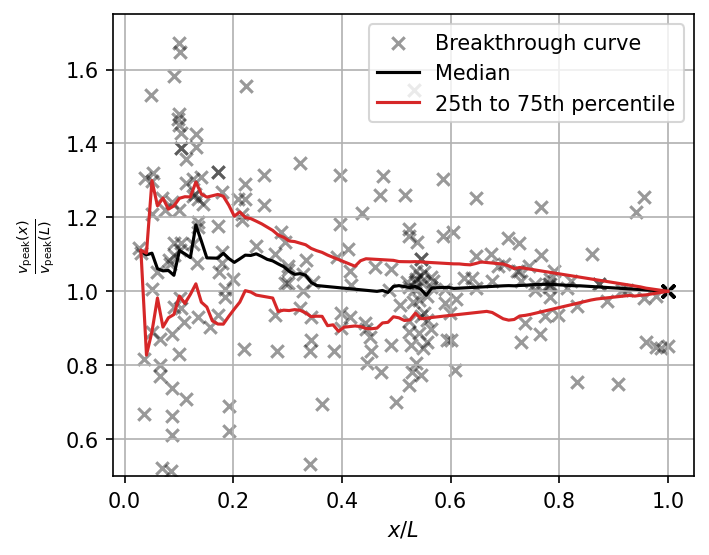

In [31]:
fig, ax = plt.subplots(figsize=(5, 4))
xs_interpolation = np.linspace(0,1,100)
est_vels_interp = np.zeros((len(xs_m_ttl),100))
for i in range(len(xs_m_ttl)):
    xs_sort = np.array(xs_m_ttl[i])[np.argsort(xs_m_ttl[i])]
    # estimated_vels = (np.array(xs_m_ttl[i])/np.array(m1_m_ttl[i]))[np.argsort(xs_m_ttl[i])]
    peaks_t = [ts_[np.argmax(btc_)] for btc_,ts_ in zip(btcs_m_ttl[i],ts_m_ttl[i])]
    estimated_vels = (np.array(xs_m_ttl[i])/np.array(peaks_t))[np.argsort(xs_m_ttl[i])]
    est_vels_interp[i] = np.interp(xs_interpolation,xs_sort/xs_sort[-1],estimated_vels/estimated_vels[-1],left = np.nan, right = np.nan)
    if i == 0:
        ax.scatter(xs_sort/xs_sort[-1],estimated_vels/estimated_vels[-1], c = 'k', marker = 'x', alpha = 0.4, label = 'Breakthrough curve')
    else:
        ax.scatter(xs_sort/xs_sort[-1],estimated_vels/estimated_vels[-1], c = 'k', marker = 'x', alpha = 0.4)
median_est_vels = np.nanmedian(est_vels_interp, axis = 0)
perc25_est_vels,perc75_est_vels = np.nanpercentile(est_vels_interp,[25,75], axis = 0)
ax.plot(xs_interpolation,median_est_vels, c = 'k',label = 'Median')
ax.plot(xs_interpolation,perc25_est_vels, c = 'tab:red',label = '25th to 75th percentile')
ax.plot(xs_interpolation,perc75_est_vels, c = 'tab:red')
ax.set_ylim(0.5,1.75)
ax.legend()
ax.grid()
ax.set_xlabel(r'$x/L$')
ax.set_ylabel(r'$\frac{v_{\text{peak}}(x)}{v_{\text{peak}}(L)}$')

In [32]:
np.argsort([csk_f(ts_m[j],btcs_m[j]) for j in range(len(btcs_m))])

array([241, 126,  65, 165,  81, 264, 239, 199, 108, 191,  31,  69, 193,
       256, 192, 253,  32,  28, 195, 170, 210, 242,  74, 245, 154, 155,
       167, 109, 172,  43, 230, 255, 257, 243,  20, 252, 268, 231, 162,
        27, 233, 260, 238,  24, 138,  40, 133,  22, 234,  51, 145, 171,
       168, 277, 158,  37,  41, 104, 249,  16,  15, 246, 190,  42, 250,
       209, 135, 271, 153,  55, 244, 201, 228, 196, 146, 114, 177, 164,
       157,  26,  29, 194, 166, 159, 163, 215, 269, 267,  50, 181, 276,
        39, 229,  71, 178, 139, 221, 254, 189, 218, 179, 156, 149, 152,
       161, 205, 206, 204, 251, 217, 134, 180, 141,  25, 259, 275,  30,
       143, 136, 147,  23,  58, 186, 185, 188, 261, 265, 220, 198, 137,
       219, 144,  14, 227, 214, 203, 148, 272, 160, 236,  48,  49,  19,
       235,  66, 222, 187, 237,  13, 213, 128, 140, 197,  21,  80, 263,
       248,  96,   9, 266, 202,  35,  36, 169,  83,  47,  18, 142,  91,
       273, 212,  60,  93, 150, 208, 211, 270, 184, 173, 224,  1

In [33]:
np.percentile([csk_f(ts_m[j],btcs_m[j]) for j in range(len(btcs_m))],[5])

array([0.53771519])

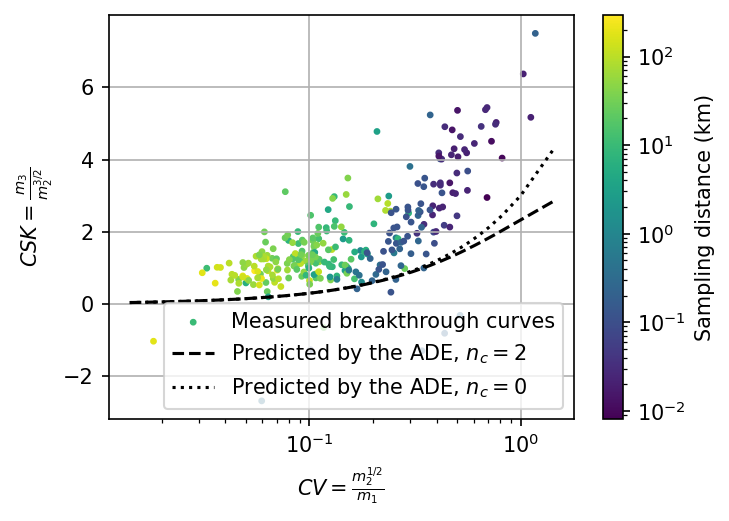

In [34]:
import scipy as sp
import matplotlib.colors as mcolors

fig, axes = plt.subplots(figsize=(5, 3.5))

Pes_ADE = np.linspace(0,10000,10000)
plt.scatter([i for j in covs_m_ttl for i in j],[i for j in csks_m_ttl for i in j], s = 5.0, c = [i for j in xs_m_ttl for i in j], norm=mcolors.LogNorm(), label = 'Measured breakthrough curves')
cb = plt.colorbar()
cb.ax.set_ylabel('Sampling distance (km)')

plt.plot((2*Pes_ADE+8)**(1/2)/(Pes_ADE+2),(12*Pes_ADE+64)/(2*Pes_ADE+8)**(3/2), c = 'k', linestyle = 'dashed',label = r'Predicted by the ADE, $n_c = 2$')
plt.plot((2*Pes_ADE)**(1/2)/(Pes_ADE),(12*Pes_ADE)/(2*Pes_ADE)**(3/2), c = 'k', linestyle = 'dotted',label = r'Predicted by the ADE, $n_c = 0$')
plt.xscale('log')
plt.grid()
plt.xlabel(r'$CV = \frac{m_2^{1/2}}{m_1}$')
plt.ylabel(r'$CSK = \frac{m_3}{m_2^{3/2}}$')
Pes_pred = np.array([sp.optimize.root_scalar(lambda Pe: (2*Pe+8)**(1/2)/(Pe+2)-i,x0 =1.0).root for j in covs_m_ttl for i in j])
plt.legend()

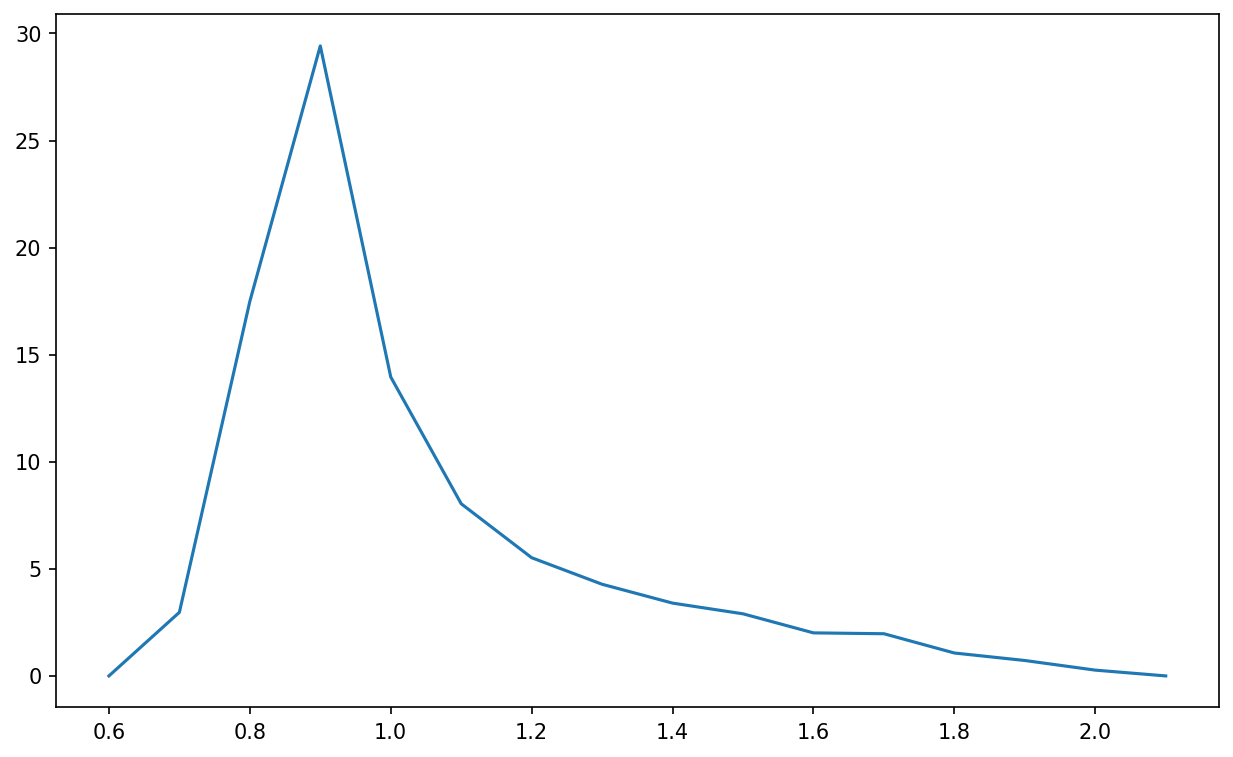

In [35]:
plt.plot(ts_m[np.argsort([i for j in csks_m_ttl for i in j])[-5]],btcs_m[np.argsort([i for j in csks_m_ttl for i in j])[-5]])

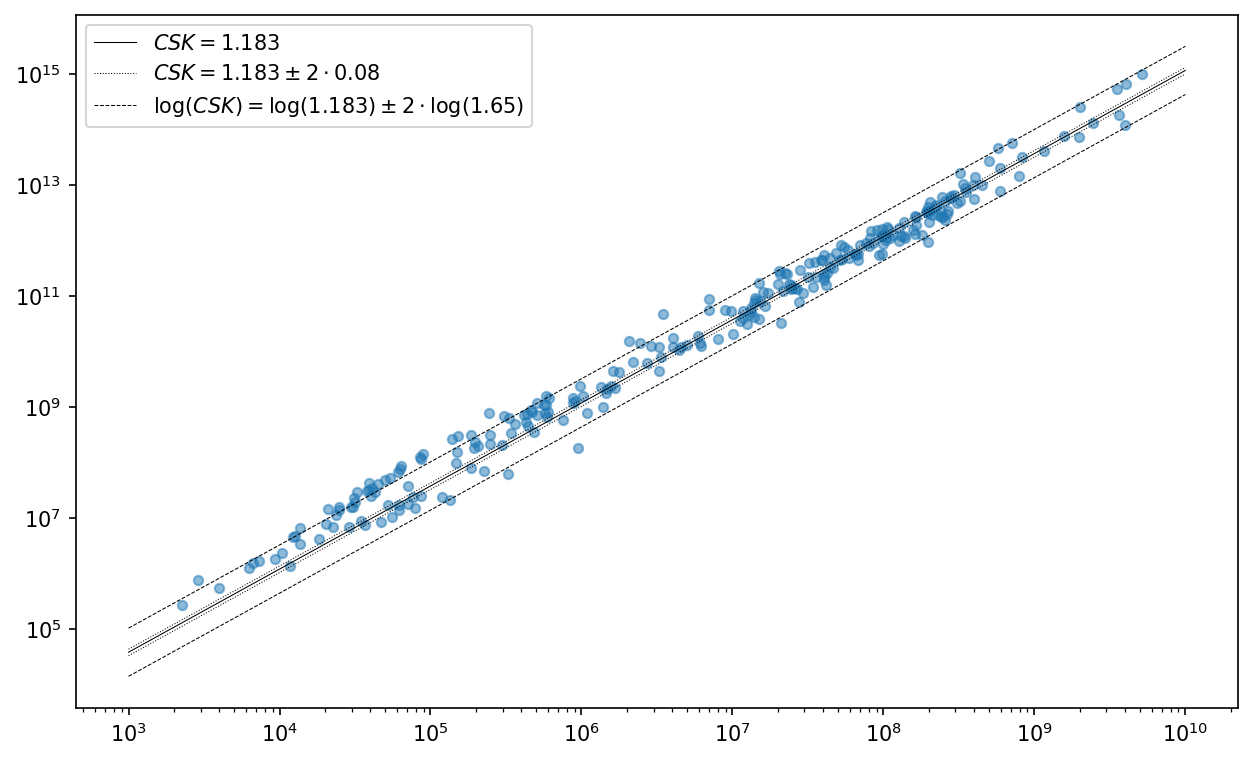

In [36]:
plt.scatter(np.array([i for j in var_m_ttl for i in j])*3600**2,np.array([i for j in m3_m_ttl for i in j])*3600**3 , alpha = 0.5, s = 20)
plt.plot(np.array([10**3,10**10]),np.array([10**3,10**10])**(1.5)*1.183, c = 'k',linewidth = 0.5, label=r'$CSK=1.183$')
plt.plot(np.array([10**3,10**10]),np.array([10**3,10**10])**(1.5)*(1.183+2*0.08), c = 'k',linestyle = 'dotted',linewidth = 0.5, label=r'$CSK=1.183\pm 2\cdot 0.08$')
plt.plot(np.array([10**3,10**10]),np.array([10**3,10**10])**(1.5)*(1.183-2*0.08), c = 'k',linestyle = 'dotted',linewidth = 0.5)
plt.plot(np.array([10**3,10**10]),np.array([10**3,10**10])**(1.5)*1.183*1.65**2, c = 'k',linestyle = 'dashed',linewidth = 0.5, label=r'$\log(CSK)=\log(1.183)\pm 2\cdot \log(1.65)$')
plt.plot(np.array([10**3,10**10]),np.array([10**3,10**10])**(1.5)*1.183/1.65**2, c = 'k',linestyle = 'dashed',linewidth = 0.5)
plt.xscale('log')
plt.yscale('log')
plt.legend()

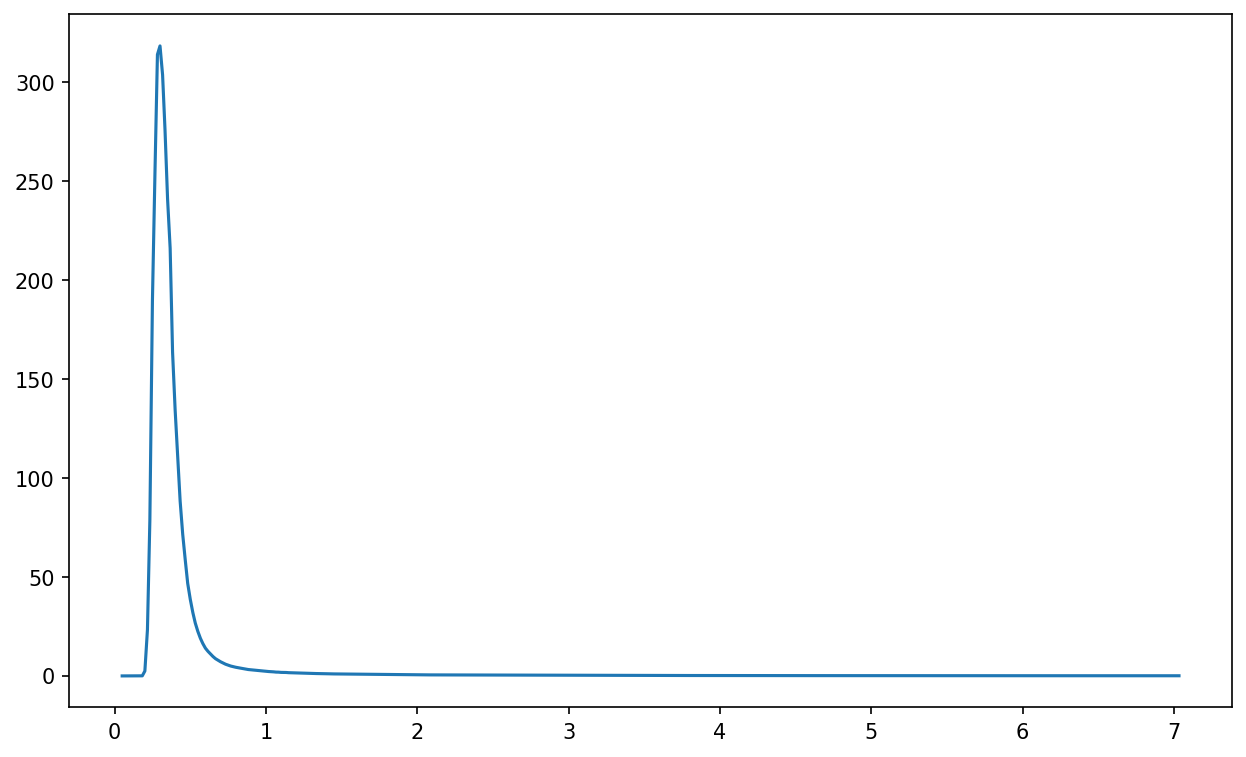

In [37]:
plt.plot([i for j in ts_m_ttl for i in j][np.argmax([i for j in csks_m_ttl for i in j])],[i for j in btcs_m_ttl for i in j][np.argmax([i for j in csks_m_ttl for i in j])])

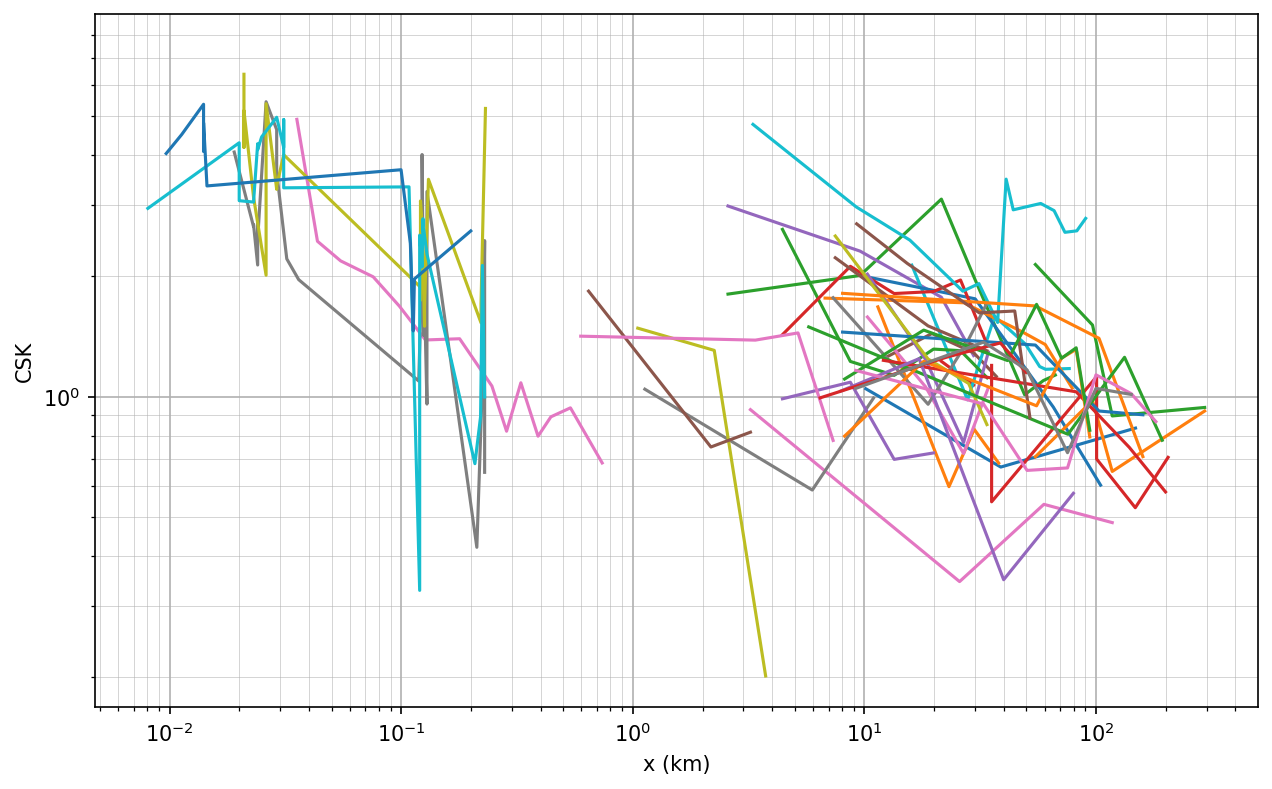

In [38]:
for i in range(len(xs_m_ttl)):
    mask = np.array(csks_m_ttl[i])>0
    x_plot = np.array(xs_m_ttl[i])[mask]
    csk_plot = np.array(csks_m_ttl[i])[mask]
    plt.loglog(x_plot[np.argsort(x_plot)],csk_plot[np.argsort(x_plot)])
plt.xlabel('x (km)')
plt.ylabel('CSK')
plt.grid()
plt.grid(which = 'minor', linewidth = 0.25)

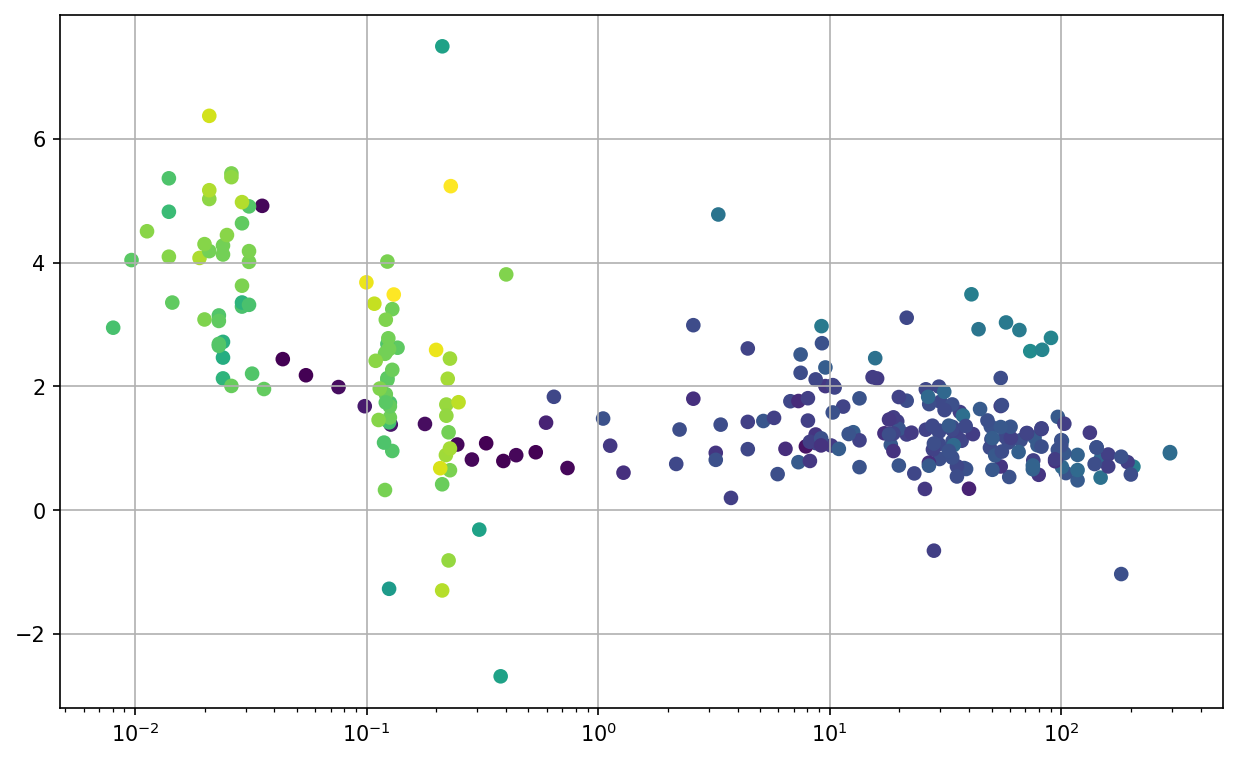

In [39]:
plt.scatter([i for j in xs_m_ttl for i in j],[i for j in csks_m_ttl for i in j],c = np.log([len(i) for j in btcs_m_ttl for i in j]))
plt.xscale('log')
plt.grid()
# plt.yscale('log')

In [40]:
print('Overall loglog slope,',np.polyfit(np.log([i for j in xs_m_ttl for i in j])[np.array([i for j in csks_m_ttl for i in j])>0],
           np.log([i for j in csks_m_ttl for i in j])[np.array([i for j in csks_m_ttl for i in j])>0],1)[0])
print('Overall loglog slope, x>500m,',np.polyfit(np.log([i for j in xs_m_ttl for i in j])[np.array([i for j in xs_m_ttl for i in j])>0.5],
           np.log([i for j in csks_m_ttl for i in j])[np.array([i for j in xs_m_ttl for i in j])>0.5],1)[0])
print('Overall Pearson Correlation coefficient,',sp.stats.pearsonr(np.log([i for j in xs_m_ttl for i in j])[np.array([i for j in csks_m_ttl for i in j])>0],np.log([i for j in csks_m_ttl for i in j])[np.array([i for j in csks_m_ttl for i in j])>0]).statistic)
print('Overall Pearson Correlation coefficient, x>500m,',sp.stats.pearsonr(np.log([i for j in xs_m_ttl for i in j])[np.array([i for j in xs_m_ttl for i in j])>0.5],np.log([i for j in csks_m_ttl for i in j])[np.array([i for j in xs_m_ttl for i in j])>0.5]).statistic)

Overall loglog slope, -0.12417584717520151
Overall loglog slope, x>500m, nan
Overall Pearson Correlation coefficient, -0.6099550343217651
Overall Pearson Correlation coefficient, x>500m, nan


In [41]:
np.mean(np.array([i for j in csks_m_ttl for i in j])/((12*Pes_pred+64)/(2*Pes_pred+8)**(3/2)))

np.float64(3.690430118641612)

In [42]:
gmean = lambda x: np.exp(np.mean(np.log(x)))

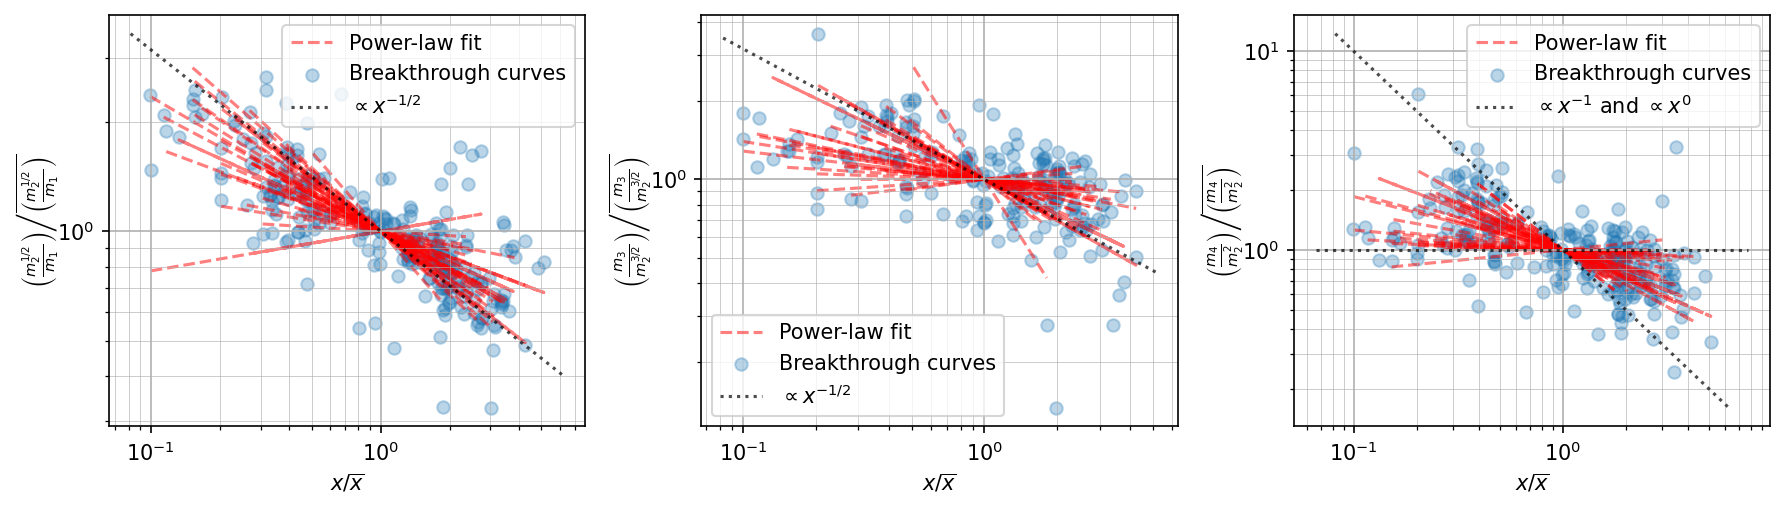

In [43]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 3.5))
cv_slope_ttl = np.zeros(len(index_ttl))
csk_slope_ttl = np.zeros(len(index_ttl))
kurt_slope_ttl = np.zeros(len(index_ttl))

for i in range(len(index_ttl)):
    if len(index_ttl[i]) > 1:
        # Covariance
        lin_coeffs = np.polyfit(np.log(xs_m_ttl[i]), np.log(covs_m_ttl[i]), 1)
        cv_slope_ttl[i] = lin_coeffs[0]
        axes[0].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                     (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                     c='r', linestyle='dashed', alpha=0.5, zorder=1, label='Power-law fit' if i == 0 else "")
        axes[0].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                        covs_m_ttl[i]/gmean(covs_m_ttl[i]),
                        c='tab:blue', alpha=0.3, zorder=0, label='Breakthrough curves' if i == 0 else "")
        
        # Skewness
        if np.all(np.array(csks_m_ttl[i]) > 0):
            lin_coeffs = np.polyfit(np.log(xs_m_ttl[i]), np.log(csks_m_ttl[i]), 1)
            csk_slope_ttl[i] = lin_coeffs[0]
            axes[1].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                         (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                         c='r', linestyle='dashed', alpha=0.5, zorder=1, label='Power-law fit' if i == 0 else "")
            axes[1].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                            csks_m_ttl[i]/gmean(csks_m_ttl[i]),
                            c='tab:blue', alpha=0.3, zorder=0, label='Breakthrough curves' if i == 0 else "")
        else:
            csk_slope_ttl[i] = np.nan
        
        # Kurtosis
        lin_coeffs = np.polyfit(np.log(xs_m_ttl[i]), np.log(kurt_m_ttl[i]), 1)
        kurt_slope_ttl[i] = lin_coeffs[0]
        axes[2].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                     (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                     c='r', linestyle='dashed', alpha=0.5, zorder=1, label='Power-law fit' if i == 0 else "")
        axes[2].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                        kurt_m_ttl[i]/gmean(kurt_m_ttl[i]),
                        c='tab:blue', alpha=0.3, zorder=0, label='Breakthrough curves' if i == 0 else "")
    else:
        cv_slope_ttl[i] = csk_slope_ttl[i] = np.nan




# Axis formatting
for i in range(3):
    axes[i].set_xscale('log')
    axes[i].set_yscale('log')
    axes[i].grid()
    axes[i].grid(which='minor', linewidth=0.3)
    axes[i].set_xlabel(r'$x/\overline{x}$')


axes[0].plot(np.array(axes[0].get_xlim()),np.array(axes[0].get_xlim())**(-1/2), c = 'k', linestyle = 'dotted',zorder = 2,alpha = 0.7, label=r'$\propto x^{-1/2}$')
axes[1].plot(np.array(axes[1].get_xlim()),np.array(axes[1].get_xlim())**(-1/2), c = 'k', linestyle = 'dotted',zorder = 2,alpha = 0.7, label=r'$\propto x^{-1/2}$')
axes[2].plot(np.array(axes[2].get_xlim()),np.array(axes[2].get_xlim())**(-1), c = 'k', linestyle = 'dotted',zorder = 2,alpha = 0.7, label=r'$\propto x^{-1}$ and $\propto x^{0}$')
axes[2].plot(np.array(axes[2].get_xlim()),np.array(axes[2].get_xlim())**(0), c = 'k', linestyle = 'dotted',zorder = 2,alpha = 0.7)
for i in range(3):
    axes[i].legend()

# Y-labels
axes[0].set_ylabel(r'$\left. \left(\frac{m_2^{1/2}}{m_1}\right) \middle/ \overline{\left(\frac{m_2^{1/2}}{m_1}\right)}\right.$', labelpad=-2)
axes[1].set_ylabel(r'$\left. \left(\frac{m_3}{m_2^{3/2}}\right) \middle/ \overline{\left(\frac{m_3}{m_2^{3/2}}\right)}\right.$', labelpad=-2)
axes[2].set_ylabel(r'$\left. \left(\frac{m_4}{m_2^{2}}\right) \middle/ \overline{\left(\frac{m_4}{m_2^{2}}\right)}\right.$', labelpad=-2)

fig.tight_layout()


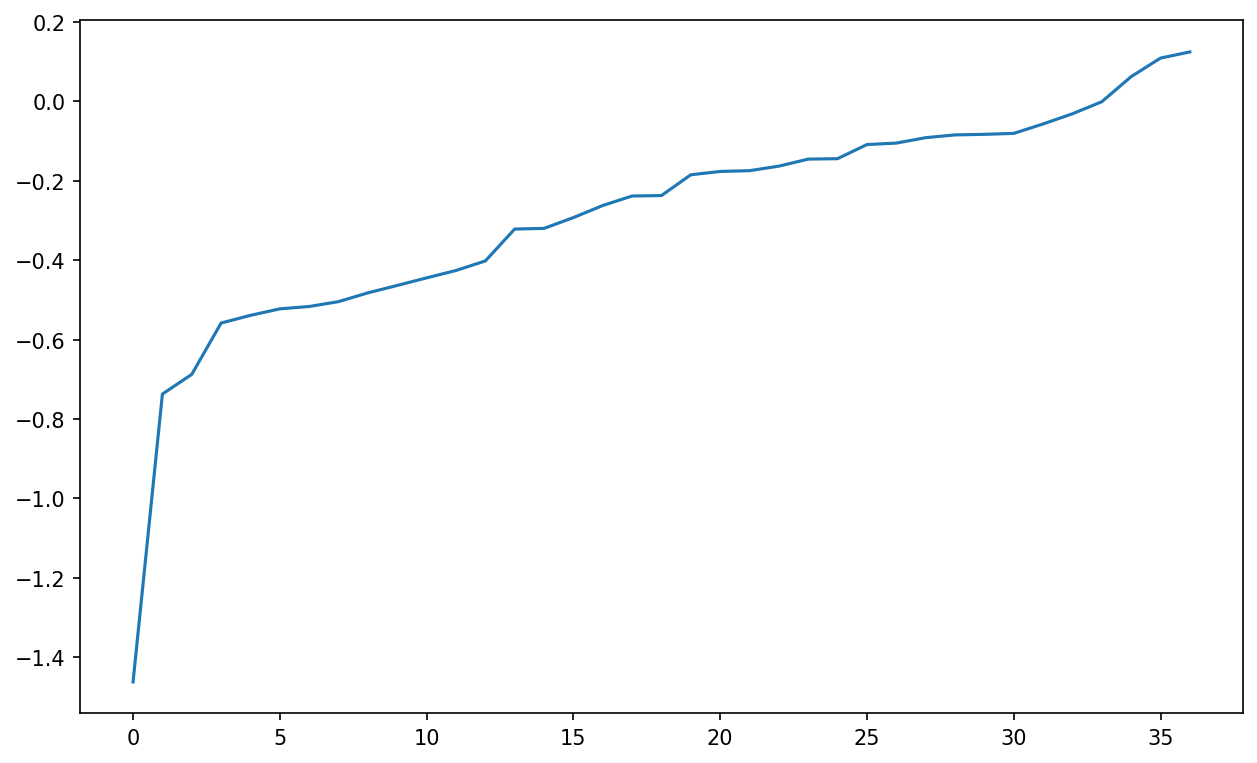

In [44]:
plt.plot(np.sort(csk_slope_ttl[~np.isnan(csk_slope_ttl)]))

C:\Users\manue\AppData\Local\Temp\ipykernel_13992\302411946.py:83: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes['e'].boxplot([m1_slope_ttl[~np.isnan(m1_slope_ttl)],var_slope_ttl[~np.isnan(var_slope_ttl)],m3_slope_ttl[~np.isnan(m3_slope_ttl)],k4_slope_ttl[~np.isnan(k4_slope_ttl)]],


(np.float64(1.3126775384433043),
 np.float64(0.9047619047619048),
 np.float64(1.751611171601962),
 np.float64(0.9285714285714286))

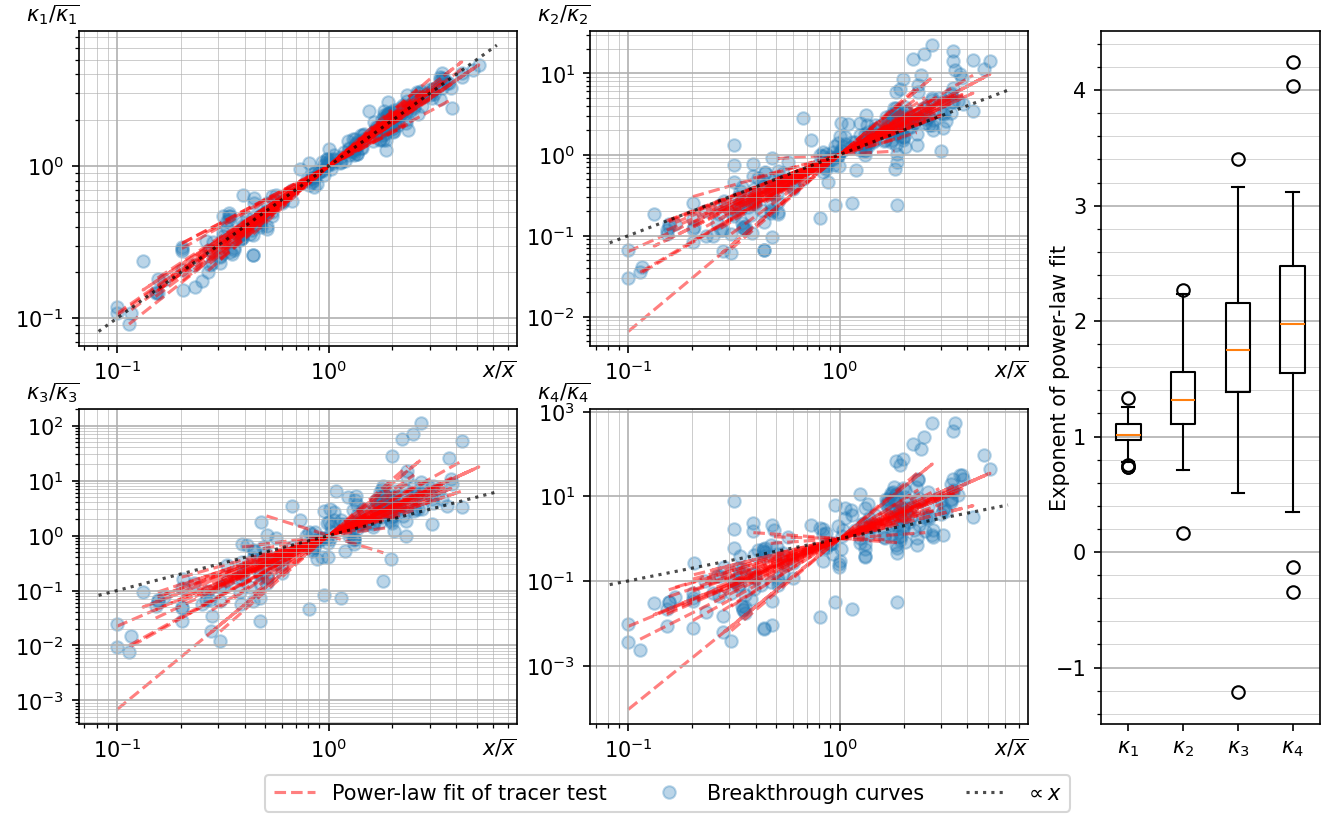

In [45]:
# fig, axes = plt.subplots(ncols=2, nrows = 2, figsize=(12, 8), gridspec_kw={'width_ratios': [4, 1]})
fig, axes = plt.subplot_mosaic([['a','b', 'e'],
                               ['c','d', 'e']],figsize=(9, 5.5), gridspec_kw={'width_ratios': [2,2, 1]})

m1_slope_ttl = np.zeros(len(index_ttl))
for i in range(len(index_ttl)):
    if len(index_ttl[i]) > 1:
        # Variance
        lin_coeffs = np.polyfit(np.log(xs_m_ttl[i]), np.log(m1_m_ttl[i]), 1)
        m1_slope_ttl[i] = lin_coeffs[0]
        axes['a'].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                     (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                     c='r', linestyle='dashed', alpha=0.5, zorder=1)
        axes['a'].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                        m1_m_ttl[i]/gmean(m1_m_ttl[i]),
                        c='tab:blue', alpha=0.3, zorder=0)
    else:
        m1_slope_ttl[i] = np.nan


var_slope_ttl = np.zeros(len(index_ttl))
for i in range(len(index_ttl)):
    if len(index_ttl[i]) > 1:
        # Variance
        lin_coeffs = np.polyfit(np.log(xs_m_ttl[i]), np.log(var_m_ttl[i]), 1)
        var_slope_ttl[i] = lin_coeffs[0]
        axes['b'].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                     (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                     c='r', linestyle='dashed', alpha=0.5, zorder=1)
        axes['b'].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                        var_m_ttl[i]/gmean(var_m_ttl[i]),
                        c='tab:blue', alpha=0.3, zorder=0)
    else:
        var_slope_ttl[i] = np.nan

m3_slope_ttl = np.zeros(len(index_ttl))


for i in range(len(index_ttl)):
    if len(index_ttl[i]) > 1:
        # Variance
        lin_coeffs = np.polyfit(np.log(np.array(xs_m_ttl[i])[np.array(m3_m_ttl[i])>0]), np.log(np.array(m3_m_ttl[i])[np.array(m3_m_ttl[i])>0]), 1)
        m3_slope_ttl[i] = lin_coeffs[0]
        axes['c'].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                     (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                     c='r', linestyle='dashed', alpha=0.5, zorder=1)
        axes['c'].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                        m3_m_ttl[i]/gmean(m3_m_ttl[i]),
                        c='tab:blue', alpha=0.3, zorder=0)
    else:
        m3_slope_ttl[i] = np.nan

k4_slope_ttl = np.zeros(len(index_ttl))
for i in range(len(index_ttl)):
    if len(index_ttl[i]) > 1:
        # Variance
        lin_coeffs = np.polyfit(np.log(xs_m_ttl[i]), np.log(k4_m_ttl[i]), 1)
        k4_slope_ttl[i] = lin_coeffs[0]
        axes['d'].plot(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                     (xs_m_ttl[i]/gmean(xs_m_ttl[i]))**lin_coeffs[0],
                     c='r', linestyle='dashed', alpha=0.5, zorder=1)
        axes['d'].scatter(xs_m_ttl[i]/gmean(xs_m_ttl[i]),
                        k4_m_ttl[i]/gmean(k4_m_ttl[i]),
                        c='tab:blue', alpha=0.3, zorder=0)
    else:
        k4_slope_ttl[i] = np.nan

for i,ax_name in enumerate(['a','b','c','d']):
    axes[ax_name].set_xscale('log')
    axes[ax_name].set_yscale('log')
    axes[ax_name].grid()
    axes[ax_name].grid(which='minor', linewidth=0.3)
    axes[ax_name].set_xlabel(r'$x/\overline{x}$', loc = 'right', labelpad=-12)
    
    axes[ax_name].plot(np.array(axes[ax_name].get_xlim()),np.array(axes[ax_name].get_xlim()), c = 'k', linestyle = 'dotted',zorder = 2,alpha = 0.7)
    
    # Y-labels
    axes[ax_name].set_ylabel(fr'$\kappa_{{{i+1}}} / \overline{{\kappa_{{{i+1}}}}}$', rotation=0, labelpad = -20.0)
    axes[ax_name].yaxis.set_label_coords(-0.06, 1.01) 
# axes[1].set_ylim(0.9*min_norm_m3,1.1*max_norm_m3)


axes['e'].boxplot([m1_slope_ttl[~np.isnan(m1_slope_ttl)],var_slope_ttl[~np.isnan(var_slope_ttl)],m3_slope_ttl[~np.isnan(m3_slope_ttl)],k4_slope_ttl[~np.isnan(k4_slope_ttl)]],
           labels=[r'$\kappa_1$',r'$\kappa_2$',r'$\kappa_3$',r'$\kappa_4$'])
axes['e'].set_ylabel('Exponent of power-law fit', labelpad=-7)
axes['e'].grid(axis='y')

axes['e'].yaxis.minorticks_on()

# 2. Configure minor grid (using 'which' to select minor)
axes['e'].grid(axis='y',which='minor', linewidth='0.25')

fig.legend(handles=[
        plt.Line2D([0], [0], c='r', linestyle='dashed', alpha=0.5, zorder=1, label='Power-law fit of tracer test'),
        plt.Line2D([0], [0], c='tab:blue', marker = 'o', linestyle = 'none', alpha=0.3, zorder=0, label='Breakthrough curves'),
        plt.Line2D([0], [0], c = 'k', linestyle = 'dotted',zorder = 2,alpha = 0.7, label=r'$\propto x$')
        ], loc="lower center", ncol=5)
plt.tight_layout(rect=[0,0.04,1,1])
plt.subplots_adjust(wspace=0.2, hspace=0.2)


np.median(var_slope_ttl[~np.isnan(var_slope_ttl)]),np.mean(var_slope_ttl[~np.isnan(var_slope_ttl)]>1.0),np.median(m3_slope_ttl[~np.isnan(m3_slope_ttl)]),np.mean(m3_slope_ttl[~np.isnan(m3_slope_ttl)]>1.0)

(array([[ 1.        , -0.17660785],
        [-0.17660785,  1.        ]]),
 array([[ 1.        , -0.26325344],
        [-0.26325344,  1.        ]]),
 array([[ 1.        , -0.08176357],
        [-0.08176357,  1.        ]]))

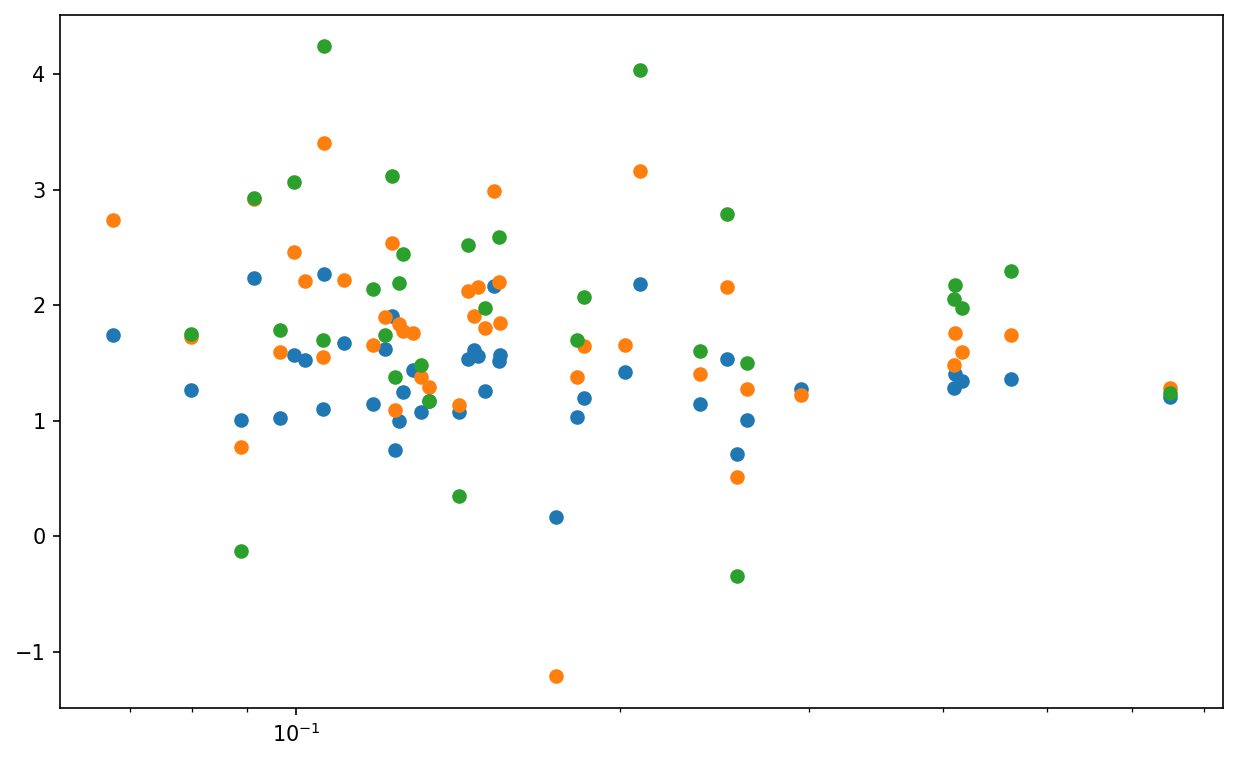

In [46]:
last_covs = np.array([c[0] for c in covs_m_ttl])
plt.scatter(last_covs,var_slope_ttl)
plt.scatter(last_covs,m3_slope_ttl)
plt.scatter(last_covs,k4_slope_ttl)
plt.xscale('log')
(np.corrcoef(np.log(last_covs[~np.isnan(var_slope_ttl)]),var_slope_ttl[~np.isnan(var_slope_ttl)]),
 np.corrcoef(np.log(last_covs[~np.isnan(m3_slope_ttl)]),m3_slope_ttl[~np.isnan(m3_slope_ttl)]),
 np.corrcoef(np.log(last_covs[~np.isnan(k4_slope_ttl)]),k4_slope_ttl[~np.isnan(k4_slope_ttl)]))

(array([[ 1.        , -0.03682214],
        [-0.03682214,  1.        ]]),
 array([[ 1.       , -0.0213006],
        [-0.0213006,  1.       ]]),
 array([[ 1.        , -0.10364286],
        [-0.10364286,  1.        ]]))

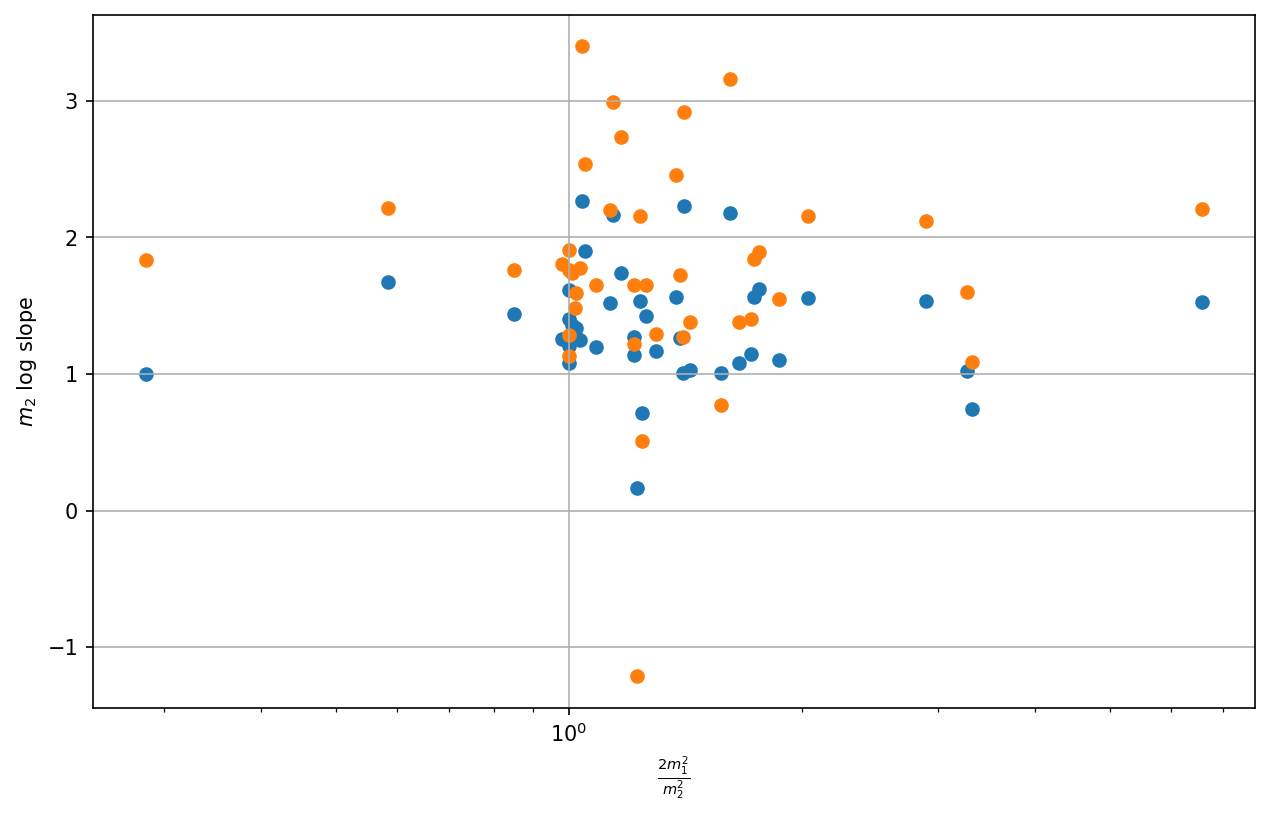

In [53]:
import matplotlib.colors as mcolors
plt.scatter(Q_est_change,var_slope_ttl)
plt.scatter(Q_est_change,m3_slope_ttl)
plt.xscale('log')
plt.grid()
plt.xlabel(r'$\frac{2 m_1^2}{m_2^2}$')
plt.ylabel(r'$m_2$ log slope')
(np.corrcoef(np.log(Q_est_change)[~np.isnan(var_slope_ttl)],var_slope_ttl[~np.isnan(var_slope_ttl)]),
 np.corrcoef(np.log(Q_est_change)[~np.isnan(m3_slope_ttl)],m3_slope_ttl[~np.isnan(m3_slope_ttl)]),
 np.corrcoef(np.log(Q_est_change)[~np.isnan(k4_slope_ttl)],k4_slope_ttl[~np.isnan(k4_slope_ttl)]))

In [54]:
np.mean(np.abs(np.array(Q_est_change)-1)<0.2)

np.float64(0.3333333333333333)

In [55]:
(Qs_m_ttl[16][-1]/Qs_m_ttl[16][0]-1)

np.float64(0.1934156380335188)

In [56]:
(Qs_m_ttl[27][-1]/Qs_m_ttl[27][0]-1)

np.float64(0.08333333333333348)

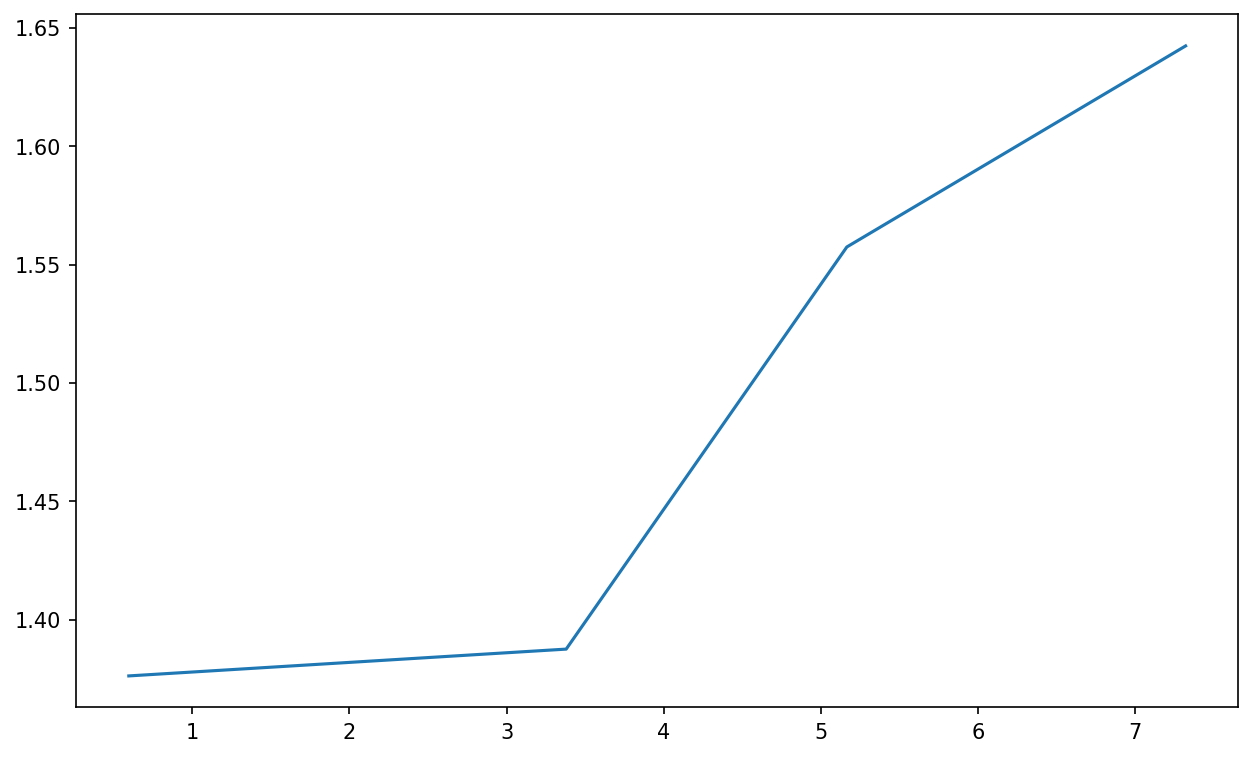

In [57]:
plt.plot(xs_m_ttl[16],Qs_m_ttl[16])

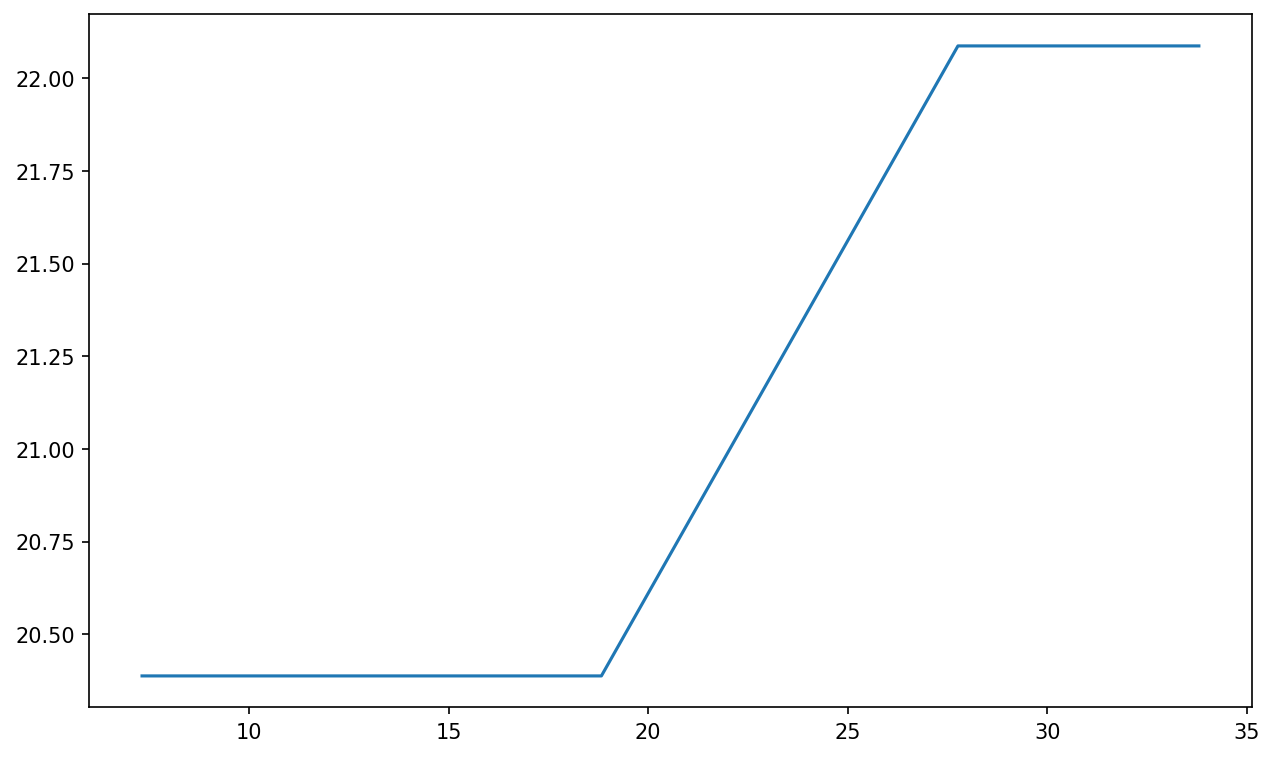

In [58]:
plt.plot(xs_m_ttl[27],Qs_m_ttl[27])

### Variable dispersion

In [59]:
int_D = lambda t,D_inf,D_0,alpha_D: D_inf*t-alpha_D*(D_inf-D_0)*(1-np.exp(-t/alpha_D))
ADE_an_sol = lambda x,t,v,D_inf,D_0,alpha_D: (4*np.pi*int_D(t,D_inf,D_0,alpha_D))**(-1/2)*np.exp(-(x-v*t)**2/(4*int_D(t,D_inf,D_0,alpha_D)))


In [60]:
def norm_cent_moments(t,btc, n):
    m0 = np.trapezoid(btc,t)
    m1 = np.trapezoid(btc*t,t)/m0
    return [m1]+[np.trapezoid(btc*(t-m1)**k,t)/m0 for k in range(2,n+1)]

In [61]:
ts = np.linspace(0,500,100001)[1:]
Pes_ADE = 10**np.linspace(-1.0,5,200)
alphas = 10**np.linspace(-1,2,4)
csk_max_exp = np.zeros((len(alphas),len(Pes_ADE)))
cov_max_exp = np.zeros((len(alphas),len(Pes_ADE)))
kurt_max_exp = np.zeros((len(alphas),len(Pes_ADE)))
for i,alpha_D in enumerate(alphas):
    for j,Pe in enumerate(Pes_ADE):
        m1,m2,m3,m4 = norm_cent_moments(ts,ADE_an_sol(1.0,ts,1.0,1/Pe,0.0,alpha_D), 4)
        csk_max_exp[i][j] = (m3/m2**(3/2))
        cov_max_exp[i][j] = (m2**(1/2)/m1)
        kurt_max_exp[i][j] = (m4/m2**(2))

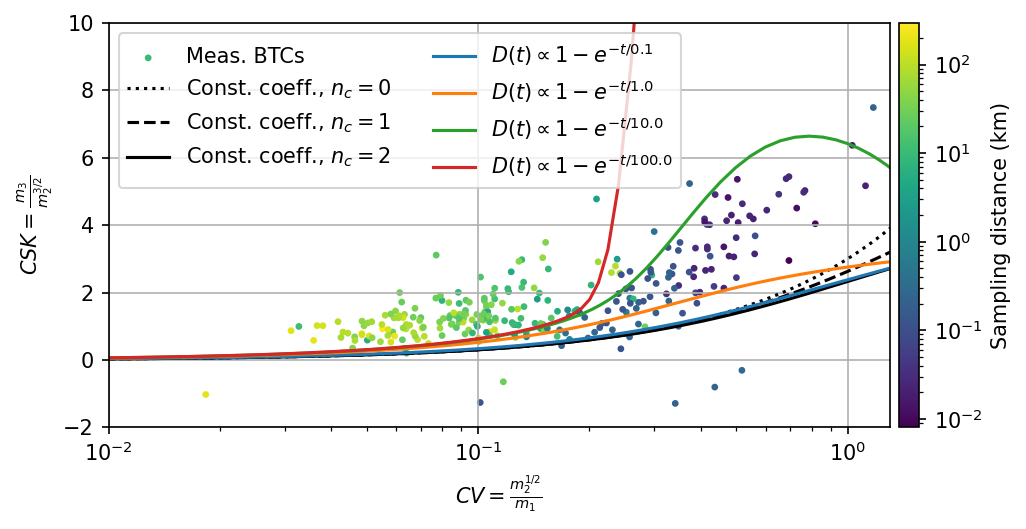

In [62]:
import scipy as sp
import matplotlib.colors as mcolors

fig, axes = plt.subplots(figsize=(8, 3.5))

plt.scatter([i for j in covs_m_ttl for i in j],[i for j in csks_m_ttl for i in j], s = 5.0, c = [i for j in xs_m_ttl for i in j], norm=mcolors.LogNorm(), label = 'Meas. BTCs')
cb = plt.colorbar(pad = 0.01)
cb.ax.set_ylabel('Sampling distance (km)')

plt.plot((2*Pes_ADE)**(1/2)/(Pes_ADE),(12*Pes_ADE)/(2*Pes_ADE)**(3/2), c = 'k', linestyle = 'dotted',label = r'Const. coeff., $n_c = 0$')
plt.plot((2*Pes_ADE+3)**(1/2)/(Pes_ADE+1),(12*Pes_ADE+20)/(2*Pes_ADE+3)**(3/2), c = 'k', linestyle = 'dashed',label = r'Const. coeff., $n_c = 1$')
plt.plot((2*Pes_ADE+8)**(1/2)/(Pes_ADE+2),(12*Pes_ADE+64)/(2*Pes_ADE+8)**(3/2), c = 'k',label = r'Const. coeff., $n_c = 2$')
for i,alpha_D in enumerate(alphas):
    plt.plot(cov_max_exp[i],csk_max_exp[i], label = fr'$D(t)\propto 1-e^{{-t/{alpha_D}}}$')
plt.xscale('log')
plt.grid()
plt.xlabel(r'$CV = \frac{m_2^{1/2}}{m_1}$')
plt.ylabel(r'$CSK = \frac{m_3}{m_2^{3/2}}$')
plt.xlim(0.01,1.3)
plt.ylim(-2,10)
Pes_pred = np.array([sp.optimize.root_scalar(lambda Pe: (2*Pe+8)**(1/2)/(Pe+2)-i,x0 =1.0).root for j in covs_m_ttl for i in j])
plt.legend(ncols = 2)

In [63]:
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d
skw_x_s = []
t_norm_s = []
for j in range(len(ts_m_ttl)):
    t_interp = np.linspace(0,max([t[-1] for t in ts_m_ttl[j]]),2000)
    U_interp = np.linspace(0,1,10000)
    btcs_cum_inv = np.zeros((len(btcs_m_ttl[j]), len(U_interp)))
    for i in range(len(btcs_m_ttl[j])):
        ts,btc,x = ts_m_ttl[j][i],btcs_m_ttl[j][i],xs_m_ttl[j][i]
        btcs_cum_inv[i] = np.interp(U_interp,cumulative_trapezoid(btc, ts, initial=0)/cumulative_trapezoid(btc, ts, initial=0)[-1],ts)
    x_interp = np.linspace(xs_m_ttl[j][0],xs_m_ttl[j][-1],1000)
    btcs_cum_inv_interp = interp1d(xs_m_ttl[j],btcs_cum_inv,axis = 0)(x_interp)
    btcs_cum_interp = np.array([interp1d(btc_cum_inv_interp,U_interp, bounds_error = False, fill_value = (0.0,1.0))(t_interp) for btc_cum_inv_interp in btcs_cum_inv_interp])
    btcs_interp = np.gradient(btcs_cum_interp,t_interp, axis = 1).T
    skw_x_s_ = []
    mask_valid_skw = (btcs_interp[:,-1]<0.0001*np.max(btcs_interp,axis = 1))&(btcs_interp[:,0]<0.0001*np.max(btcs_interp,axis = 1))
    if np.sum(mask_valid_skw)>0:
        for k in np.where(mask_valid_skw)[0]:
            m1_x,m2_x,m3_x = norm_cent_moments(x_interp,btcs_interp[k], 3)
            skw_x_s_.append(m3_x/m2_x**(3/2))
        skw_x_s.append(skw_x_s_)
        t_norm_s.append(t_interp[mask_valid_skw])
    else:
        skw_x_s.append([])
        t_norm_s.append([])

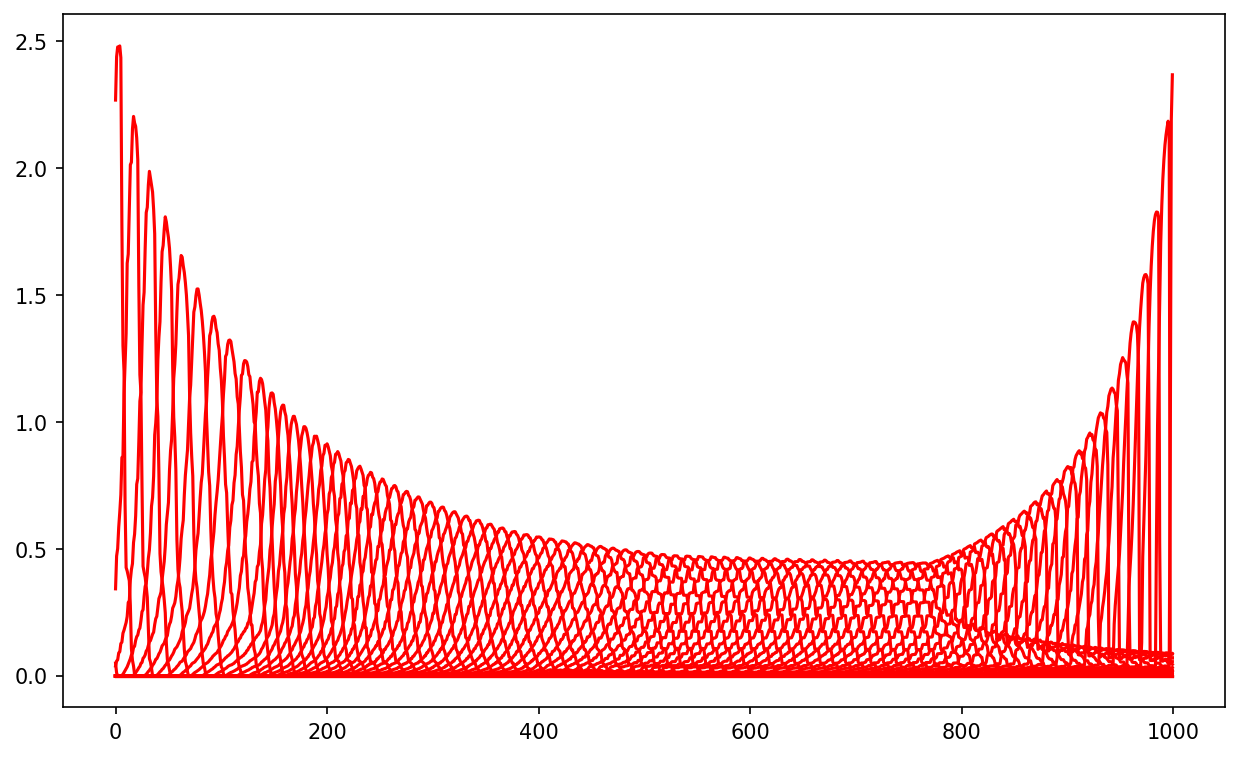

In [64]:
for i in range(100):
    plt.plot(btcs_interp[i*20], c = 'r')

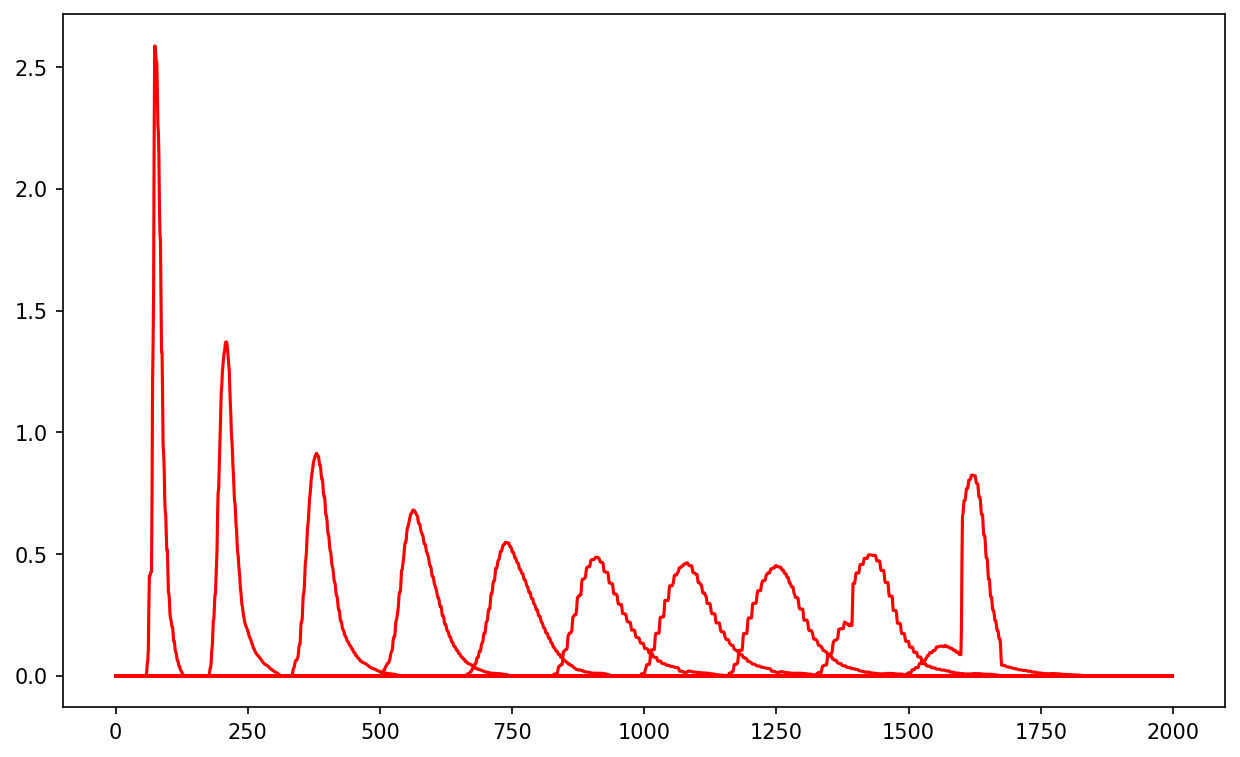

In [65]:
for i in range(10):
    plt.plot(btcs_interp[:,i*100], c = 'r')

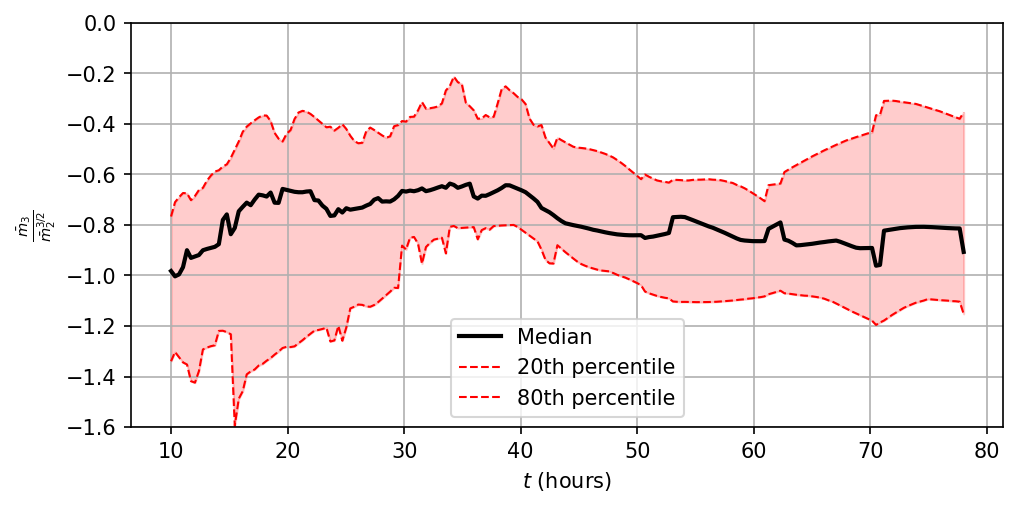

In [66]:
import numpy as np
from scipy.interpolate import interp1d

# Define common grid
t_norm_lims = [10.0,78.0]
t_common = np.linspace(*t_norm_lims, 200)  # 200 points between 0 and 0.8
interpolated = []

for j in range(len(skw_x_s)):
    t = t_norm_s[j]
    y = skw_x_s[j]

    # Only interpolate if curve covers part of [0, 0.8]
    if len(t)>0:
        if np.min(t) <= t_norm_lims[1] and np.max(t) >= t_norm_lims[0]:
            # Restrict interpolation domain
            t_min = max(np.min(t), t_norm_lims[0])
            t_max = min(np.max(t), t_norm_lims[1])
    
            mask = (t_common >= t_min) & (t_common <= t_max)
    
            f = interp1d(t, y, bounds_error=False, fill_value=np.nan)
            y_interp = f(t_common)
    
            # mask out values beyond curve support
            y_interp[~mask] = np.nan
            interpolated.append(y_interp)
            
            

# Convert to array
interpolated = np.array(interpolated)

# Median
median_vals = np.nanmedian(interpolated, axis=0)

# Percentiles
p20 = np.nanpercentile(interpolated, 20, axis=0)
p80 = np.nanpercentile(interpolated, 80, axis=0)

fig, ax = plt.subplots(figsize=(7.5, 3.5))

ax.plot(t_common, median_vals, c='k', lw=2, label='Median')
ax.plot(t_common, p20, c='r', ls='--', lw=1, label='20th percentile')
ax.plot(t_common, p80, c='r', ls='--', lw=1, label='80th percentile')

# Optionally shade between 20th–90th
ax.fill_between(t_common, p20, p80, color='r', alpha=0.2)

plt.ylim(-1.6, 0.0)
ax.grid()
ax.set_xlabel(r'$t$ (hours)')
ax.set_ylabel(r'$\frac{\bar{m}_{3}}{\bar{m}_{2}^{3/2}}$')
ax.legend()


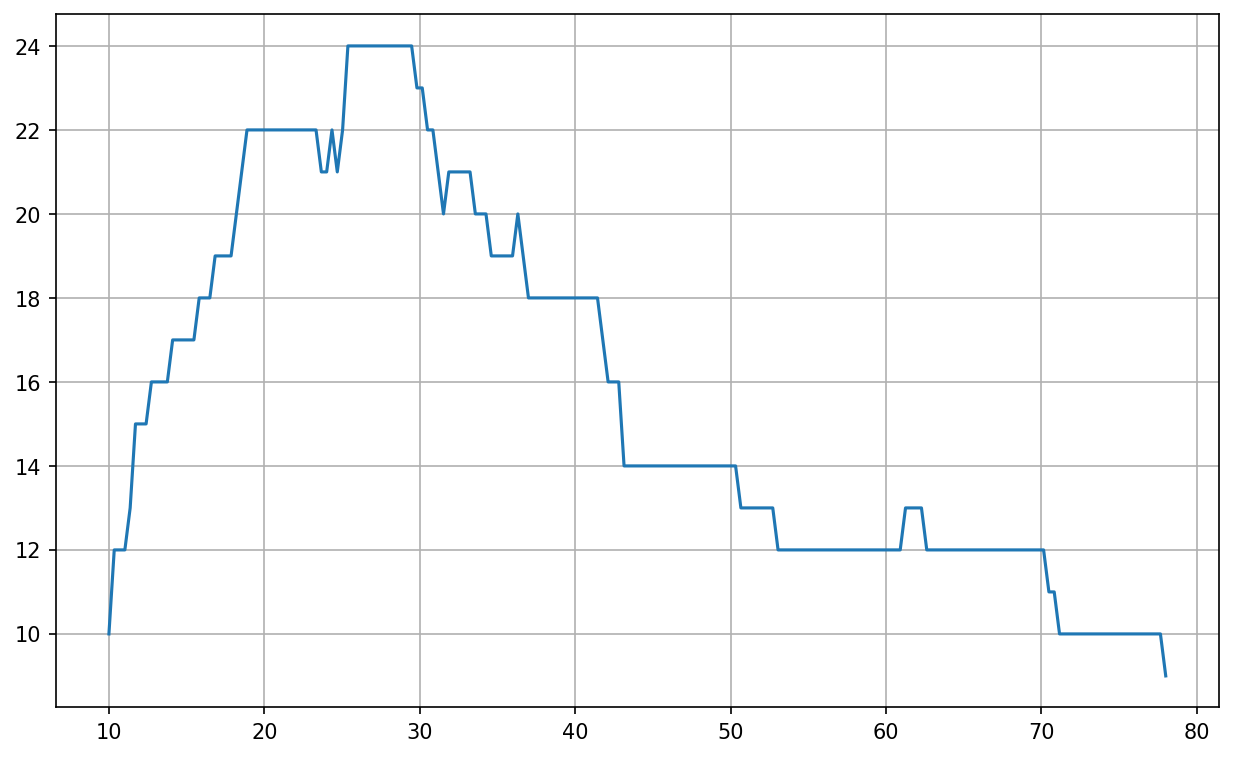

In [67]:
plt.plot(t_common,np.sum(~np.isnan(interpolated),axis= 0))
plt.grid()

### Parameter estimation

In [68]:
def central_moments_to_cumulants(moments):
    """
    Computes cumulants from central moments.
    moments: array-like of central moments [mu_1, mu_2, mu_3, ..., mu_n]
             Note: mu_1 MUST be 0.0 by definition.
    """
    n = len(moments)
    
    # Treat central moments as raw moments of a centered distribution (g_0 = 1)
    g = np.concatenate(([1.0,0.0], moments[1:])) 
    
    kappa = np.zeros(n + 1)
    
    for i in range(1, n + 1):
        kappa[i] = g[i]
        for k in range(1, i):
            # Standard raw moment to cumulant recursion
            comb = sp.special.comb(i - 1, k - 1, exact=True)
            kappa[i] -= comb * kappa[k] * g[i - k]
            
    return np.concatenate(([moments[0]],kappa[2:]))

In [69]:
N_moms = 4
for i_ttl in range(len(xs_m_ttl)):
    if len(xs_m_ttl[i_ttl])==4:
        xs_i = xs_m_ttl[i_ttl]
        ts_i = ts_m_ttl[i_ttl]
        btcs_m_i = btcs_m_ttl[i_ttl]
        m0= np.array([np.trapezoid(btcs_m_i[i],x = ts_i[i]) for i in range(len(btcs_m_i))])
        m1= np.array([np.trapezoid(btcs_m_i[i]*ts_i[i],x = ts_i[i]) for i in range(len(btcs_m_i))])/m0
        moms_ref = np.concatenate((m1[:,None],np.array([[np.trapezoid(btcs_m_i[i]*(ts_i[i]-m1[i])**n,x = ts_i[i]) for n in range(2,N_moms+1)] for i in range(len(btcs_m_i))])/m0[:,None]),axis = 1)
        cumul_ref = np.array([central_moments_to_cumulants(mom) for mom in moms_ref])
        slopes_print = []
        r2_slope_print = []
        mix_T_over_t_peak = (1/((0.6*np.nanmean(u_stars_m_ttl[i_ttl])*np.nanmean(Hs_m_ttl[i_ttl]))/np.nanmean(Bs_m_ttl[i_ttl])**2))/(ts_i[-1][np.argmax(btcs_m_i[-1])]*3600)
        Pe_a_tracer = lambda a: ((3*(a+3)**2+9*(a+1)*(a+3))*xs_i[-1]*1000*0.6*np.nanmean(u_stars_m_ttl[i_ttl])*np.nanmean(Hs_m_ttl[i_ttl]))/(np.nanmean(Us_m_ttl[i_ttl])*np.nanmean(Bs_m_ttl[i_ttl])**2)
        B_tracer = np.nanmean(Bs_m_ttl[i_ttl])
        H_tracer = np.nanmean(Hs_m_ttl[i_ttl])
        for i in range(N_moms):
            fit_out = np.polyfit(np.log(xs_i),np.log(cumul_ref[:,i]),1)
            slopes_print.append(fit_out[0])
            if not np.any(np.isnan(np.log(cumul_ref[:,i]))):
                r2_slope_print.append(r2_score(np.log(cumul_ref[:,i]),np.polyval(fit_out,np.log(xs_i))))
            else:
                r2_slope_print.append(np.nan)
        if not np.any(np.isnan(slopes_print)) and not np.any(np.array(slopes_print)<0):
            print(i_ttl,names_list[index_ttl[i_ttl][0]]+',',
                  np.round(covs_m_ttl[i_ttl][-1],3),
                  ', m1,',
                  round(np.abs(slopes_print[0]-1),3),
                  round(np.abs(r2_slope_print[0]),3),
                  ', other moms,',
                  *np.round(slopes_print[1:],3),
                  ', Mixing length,',
                  round(mix_T_over_t_peak,3),
                 round(Pe_a_tracer(1.37*np.log(1.33*B_tracer/H_tracer))),
                 round(2/np.sqrt(Pe_a_tracer(1.37*np.log(1.33*B_tracer/H_tracer))),3),
                 round(Qs_m_ttl[i_ttl][-1]/Qs_m_ttl[i_ttl][0]-1,3))

4 ANT 8-18-70 SA1, 0.067 , m1, 0.068 0.992 , other moms, 1.146 1.4 1.6 , Mixing length, 0.233 1093 0.06 0.647
5 ANT 8-18-70 SB1, 0.079 , m1, 0.173 0.996 , other moms, 1.102 1.548 1.695 , Mixing length, 0.205 2123 0.043 0.437
16 LIT 9-6-68 S1, 0.135 , m1, 0.007 0.998 , other moms, 1.532 2.155 2.786 , Mixing length, 0.852 436 0.096 0.193
22 MIS 8-7-68 S1, 0.07 , m1, 0.029 0.998 , other moms, 1.078 1.135 0.348 , Mixing length, 3.497 263 0.123 0.0
24 MON 11-14-67 SC1, 0.101 , m1, 0.002 0.999 , other moms, 1.623 1.895 1.74 , Mixing length, 0.87 871 0.068 0.421
26 MON 6-7-68 SC1, 0.085 , m1, 0.001 1.0 , other moms, 1.169 1.29 1.166 , Mixing length, 0.775 815 0.07 0.191
27 MON 6-7-68 SD1 !, 0.095 , m1, 0.071 0.998 , other moms, 1.519 2.198 2.586 , Mixing length, 1.27 519 0.088 0.083
30 RED 3-13-72 S1, 0.057 , m1, 0.089 0.999 , other moms, 1.028 1.379 1.695 , Mixing length, 0.604 1366 0.054 0.343
31 RED 4-14-71 S1, 0.051 , m1, 0.014 0.997 , other moms, 1.006 1.272 1.495 , Mixing length, 1.409 

In [122]:
i_ttl = 16
xs_i = xs_m_ttl[i_ttl]
ts_i = ts_m_ttl[i_ttl]
btcs_m_i = btcs_m_ttl[i_ttl]
print(ts_i[-1][-1]/ts_i[-1][np.argmax(btcs_m_i[-1])])


1.5833333333333333


In [123]:
T_ = 2.0
Pe_a_tracer = lambda a: ((3*(a+3)**2+9*(a+1)*(a+3))*xs_i[-1]*1000*0.6*np.nanmean(u_stars_m_ttl[i_ttl])*np.nanmean(Hs_m_ttl[i_ttl]))/(np.nanmean(Us_m_ttl[i_ttl])*np.nanmean(Bs_m_ttl[i_ttl])**2)
B_tracer = np.nanmean(Bs_m_ttl[i_ttl])
H_tracer = np.nanmean(Hs_m_ttl[i_ttl])

In [124]:

m0= np.array([np.trapezoid(btcs_m_i[i],x = ts_i[i]) for i in range(len(btcs_m_i))])
m1= np.array([np.trapezoid(btcs_m_i[i]*ts_i[i],x = ts_i[i]) for i in range(len(btcs_m_i))])/m0
moms_ref = np.concatenate((m1[:,None],np.array([[np.trapezoid(btcs_m_i[i]*(ts_i[i]-m1[i])**n,x = ts_i[i]) for n in range(2,N_moms+1)] for i in range(len(btcs_m_i))])/m0[:,None]),axis = 1)
cumul_ref = np.array([central_moments_to_cumulants(mom) for mom in moms_ref])
def moms_loss(moms):
    moms_ratio = moms/moms_ref
    A = np.sign(moms_ratio)*np.abs(moms_ratio)**(1/(np.arange(1,N_moms+1)))
    t_scale = np.sum(A[:,0])/np.sum(A[:,0]**2)
    loss = np.sum((A*t_scale-1)**2)
    return loss,t_scale
print(cumul_ref)

[[1.03222719e+00 6.74936357e-02 2.48272274e-02 6.98031461e-03]
 [5.73379066e+00 1.16695512e+00 1.74493173e+00 3.28406713e+00]
 [8.21573616e+00 1.81476297e+00 3.52693921e+00 9.57495221e+00]
 [1.30478776e+01 3.10639480e+00 4.26056109e+00 2.97179709e+00]]


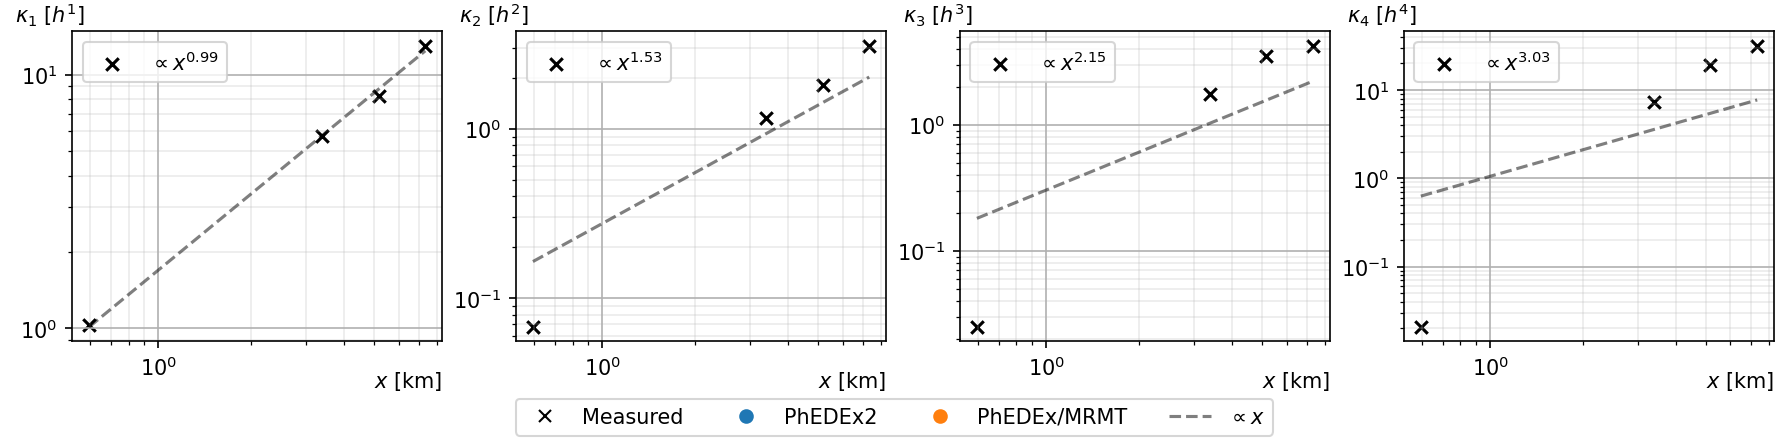

In [125]:
fig,axes = plt.subplots(ncols = N_moms, figsize = (N_moms*3,3))
axes = axes.flatten()
end_est_moms = []
for i in range(N_moms):
    ax = axes[i]
    coeff_pl = np.polyfit(np.log(xs_i)[moms_ref[:,i]>0],np.log(moms_ref[:,i][moms_ref[:,i]>0]),1)
    if i+1 == 4:
        end_est_moms.append(np.exp(np.mean(np.log(moms_ref[:,i]/xs_i)[moms_ref[:,i]>0]))*xs_i[-1])
    else:
        end_est_moms.append(np.exp(np.mean(np.log(moms_ref[:,i])-np.log(xs_i)))*xs_i[-1])
    ax.scatter(xs_i,moms_ref[:,i],label = fr'$\propto x^{{{coeff_pl[0]:.2f}}}$', c = 'k', marker = 'x')
    ax.plot(xs_i,np.array(xs_i)*np.exp(np.mean(np.log(moms_ref[:,i]/xs_i)[moms_ref[:,i]>0])), c = 'k', linestyle = 'dashed', alpha = 0.5)
    ax.set_xlabel(r'$x$ [km]',loc = 'right', labelpad = -5.0)
    ax.set_ylabel(fr'$\kappa_{i+1}$ [$h^{i+1}$]', rotation=0, labelpad = -20.0)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(which = 'major')
    ax.grid(which = 'minor', linewidth = 0.2)
    ax.yaxis.set_label_coords(-0.06, 1.01) 
    ax.tick_params(axis='both', which='major', labelbottom=True, labelleft=True)
    ax.tick_params(axis='both', which='minor', labelbottom=False, labelleft=False)
    ax.tick_params(axis='y', which='minor', labelbottom=True, labelleft=True, labelsize = 8,pad = -0.1)
    ax.tick_params(axis='x', which='minor', labelbottom=True, labelleft=True, labelsize = 8,pad = -0.1)
    # # ax.tick_params(axis='x', which='minor', labelsize=8)
    # ax.xaxis.set_major_formatter(lambda x,y: format(x,'.0f'))
    # # ax.yaxis.set_minor_formatter(lambda x,y: format(x,'.0f'))
    # # ax.tick_params(axis='y', which='minor', labelsize=8)
    # ax.yaxis.set_major_formatter(lambda x,y: format(x,'.0f'))
fig.legend(handles=[
        plt.Line2D([0], [0], marker='x', c = 'k',linestyle = 'none', label="Measured"),
        plt.Line2D([0], [0], marker='o', color="tab:blue",linestyle = 'none', label="PhEDEx2"),
        plt.Line2D([0], [0], marker='o', color="tab:orange",linestyle = 'none', label="PhEDEx/MRMT"),
        plt.Line2D([0], [0], c = 'k', linestyle = 'dashed', alpha = 0.5, label=r"$\propto x$")
        ], loc="lower center", ncol=5)
plt.tight_layout(rect=[0,0.06,1,1])
plt.subplots_adjust(wspace=0.2)

In [126]:
ts = np.linspace(0,2*T_,int(200*2*T_))[1:]
def moms_par_MRMT_analyt(pars):
    moms = np.zeros((len(xs_i),N_moms))
    for i in range(len(xs_i)):
        parameters = np.array([1.0,10**pars[0]/xs_i[-1]*xs_i[i],10**(pars[1]-pars[2]),10**pars[2]/xs_i[-1]*xs_i[i]])
        moms[i] = moms_analyt(parameters,xs_i[i]/xs_i[-1],'semi-infinite-conc','first order')**np.arange(1,N_moms+1)
    return moms
def mom_MRMT_fun(pars,reg,Pe_ref):
    mom_loss = moms_loss(moms_par_MRMT_analyt(pars))[0]
    Pe_loss = (pars[0]-np.log10(Pe_ref))**2
    return mom_loss+reg*Pe_loss
def moms_par_MRMT_num(par):
    moms_out = np.zeros((len(btcs_m_i),N_moms))
    btcs = ADEMF_1D(ts,np.array(xs_i)/xs_i[-1],1.0,10**par[0],10**par[1]/10**par[2],[10**par[2],10**par[2]],'first order','semi-infinite-conc').T
    for i in range(len(btcs_m_i)):
        synth_btc = btcs[i]
        m0 = np.trapezoid(synth_btc,x = ts)
        m1 = np.trapezoid(synth_btc*ts,x = ts)/m0
        moms_out[i] = [m1]+[np.trapezoid(synth_btc*(ts-m1)**n,x = ts)/m0 for n in range(2,N_moms+1)]
    return moms_out

In [127]:
bounds = [(1,3.5),(-4,2.0),(0,2.5)]
Pe_ref = Pe_a_tracer(1.37*np.log(1.33*B_tracer/H_tracer))#1/0.75**2*2/((moms_ref[-1,1]**(1/2)/moms_ref[-1,0]))**2
result_MRMT_reg = sp.optimize.differential_evolution(mom_MRMT_fun, args = (10**5,Pe_ref),
                                       bounds=bounds)
result_MRMT_no_reg = sp.optimize.differential_evolution(mom_MRMT_fun, args = (0.001,Pe_ref),bounds=bounds)

In [128]:
params_log_MRMT_reg = result_MRMT_reg.x.copy()
moms_MRMT_reg = moms_par_MRMT_analyt(params_log_MRMT_reg)
t_scale_opt_MRMT_reg = moms_loss(moms_MRMT_reg)[1]
cumuls_opt_MRMT_reg = np.array([central_moments_to_cumulants(mom) for mom in moms_MRMT_reg])

In [129]:
params_log_MRMT_no_reg = result_MRMT_no_reg.x.copy()
moms_MRMT_no_reg = moms_par_MRMT_analyt(params_log_MRMT_no_reg)
t_scale_opt_MRMT_no_reg = moms_loss(moms_MRMT_no_reg)[1]
cumuls_opt_MRMT_no_reg = np.array([central_moments_to_cumulants(mom) for mom in moms_MRMT_no_reg])

In [130]:
mom_MRMT_fun(params_log_MRMT_reg,0.0,1.0),format(mom_MRMT_fun(params_log_MRMT_reg,0.0,1.0)/mom_MRMT_fun(params_log_MRMT_no_reg,0.0,1.0)-1,'.3%')

(np.float64(1.4895431012981808), '0.475%')

In [131]:
10**params_log_MRMT_reg,10**params_log_MRMT_no_reg

(array([435.52386128,  35.58046135,  65.15849438]),
 array([3162.27766017,   45.64237575,   45.96734815]))

In [132]:
ts_plot = np.linspace(0,T_*2,int(300*T_*2))[1:]
btcs_MRMT_reg = ADEMF_1D(ts_plot,np.array(xs_i)/xs_i[-1],1.0,10**params_log_MRMT_reg[0],
                         10**params_log_MRMT_reg[1]/10**params_log_MRMT_reg[2],
                         [10**params_log_MRMT_reg[2],10**params_log_MRMT_reg[2]],'first order','semi-infinite-conc').T
btcs_MRMT_no_reg = ADEMF_1D(ts_plot,np.array(xs_i)/xs_i[-1],1.0,10**params_log_MRMT_no_reg[0],
                         10**params_log_MRMT_no_reg[1]/10**params_log_MRMT_no_reg[2],
                         [10**params_log_MRMT_no_reg[2],10**params_log_MRMT_no_reg[2]],'first order','semi-infinite-conc').T

In [133]:
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args

In [134]:
def moms_par(par):
    out = run_PhEDEx2(10**par[0],
           10**par[1]/10**par[2],
           10**par[2],
           10**par[3],
           par[4],
           par[5],
           T_ = T_, N_terms = 10, Nx_ = 120)
    moms_out = np.zeros((len(btcs_m_i),N_moms))
    btcs = []
    for i in range(len(btcs_m_i)):
        interp_fac = np.array([np.interp(xs_i[i]/xs_i[-1],out[0],vec) for vec in np.eye(len(out[0]))]) 
        synth_btc = out[2]@interp_fac
        btcs.append(synth_btc)
        m0 = np.trapezoid(synth_btc,x = out[1])
        m1 = np.trapezoid(synth_btc*out[1],x = out[1])/m0
        moms_out[i] = [m1]+[np.trapezoid(synth_btc*(out[1]-m1)**n,x = out[1])/m0 for n in range(2,N_moms+1)]
    return moms_out,out[1],btcs

def mom_fun(par,reg,Pe_ref):
    if len(par)==3 or par[-3]==0.0:
        loss_mom = moms_loss(moms_par_MRMT(par[:3]))[0]
    else:
        moms,t,btcs = moms_par(par)
        loss_mom,t_scale_opt = moms_loss(moms)
    Pe_corr = 10**par[0]/int_D_ratio_uniform(T_, 10**par[0], 10**par[3], par[5])[-1]
    print(10**par[0],Pe_corr,Pe_ref)
    Pe_loss = np.log10(Pe_corr/Pe_ref)**2
    total_loss = loss_mom+reg*Pe_loss
    print(loss_mom,Pe_loss,total_loss)
    return total_loss

In [135]:
%%time
from scipy.optimize import minimize, Bounds
bounds_np = np.array([[1.7, -3, 0.0, -3.0, 0, 1.0], [3.5, 0.5, 2.0, 0.0, 1, 8.0]])
bounds = Bounds(*bounds_np) 
x0 = [np.log10(Pe_ref),params_log_MRMT_reg[1],params_log_MRMT_reg[2],-3,1.0,8.0]
x0 = np.clip(x0,a_min = bounds_np[0],a_max = bounds_np[1])
result_reg = minimize(mom_fun,x0 = x0, args = (10.0,Pe_ref), method = 'Nelder-Mead', bounds = bounds, options= {'maxfev' :40})

[np.float64(435.5237689509107), np.float64(0.0485320861096588), np.float64(65.15849438293621), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
435.5237689509107 450.9595417709989 435.52376895091083
1.8007866987032537 0.00022878736512332208 1.803074572354487
[np.float64(590.1500590902044), np.float64(0.0485320861096588), np.float64(65.15849438293621), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
590.1500590902044 605.4579168548163 435.52376895091083
2.219970732074805 0.020469625932661453 2.42466699140142
[np.float64(435.5237689509107), np.float64(0.045817243740668374), np.float64(65.15849438293621), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
435.5237689509107 450.9595417709989 435.52376895091083
1.8214932069855152 0.00022878736512332208 1.8237810806367485
[np.float64(435.5237689509107), np.float64(0.03938495988516674), np.float64(80.29150389865863), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
435.5237689509107 450.9595417709989 435.52376895091083
2.071670

In [136]:
%%time
from scipy.optimize import minimize, Bounds
x0 = [np.log10(Pe_ref),params_log_MRMT_reg[1]-1,params_log_MRMT_reg[2],-3,1.0,8.0]
x0 = np.clip(x0,a_min = bounds_np[0],a_max = bounds_np[1])
result_no_reg = minimize(mom_fun,x0 = x0, args = (0.0,Pe_ref), method = 'Nelder-Mead', bounds = bounds, options= {'maxfev' :40})

[np.float64(435.5237689509107), np.float64(0.0485320861096588), np.float64(65.15849438293621), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
435.5237689509107 450.9595417709989 435.52376895091083
1.8007866987032537 0.00022878736512332208 1.8007866987032537
[np.float64(590.1500590902044), np.float64(0.0485320861096588), np.float64(65.15849438293621), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
590.1500590902044 605.4579168548163 435.52376895091083
2.219970732074805 0.020469625932661453 2.219970732074805
[np.float64(435.5237689509107), np.float64(0.045817243740668374), np.float64(65.15849438293621), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
435.5237689509107 450.9595417709989 435.52376895091083
1.8214932069855152 0.00022878736512332208 1.8214932069855152
[np.float64(435.5237689509107), np.float64(0.03938495988516674), np.float64(80.29150389865863), np.float64(0.001), np.float64(1.0), np.float64(8.0)]
435.5237689509107 450.9595417709989 435.52376895091083
2.0716

In [137]:
%%time
params_log_no_reg = result_no_reg.x
out_opt_no_reg = run_PhEDEx2(10**params_log_no_reg[0],
           10**params_log_no_reg[1]/10**params_log_no_reg[2],
           10**params_log_no_reg[2],
           10**params_log_no_reg[3],
           params_log_no_reg[4],
           params_log_no_reg[5],
           T_ = 1.5*T_, N_terms = 10, Nx_ = 120)

[np.float64(65.10960831217811), np.float64(0.0297355421082647), np.float64(100.0), np.float64(0.001), np.float64(0.6752390996847804), np.float64(7.559405032339747)]
CPU times: total: 1min 4s
Wall time: 1min 4s


In [138]:
moms_out_no_reg = np.zeros((len(btcs_m_i),N_moms))
cumuls_out_no_reg = np.zeros((len(btcs_m_i),N_moms))
btcs_no_reg = []
for i in range(len(btcs_m_i)):
    interp_fac = np.array([np.interp(xs_i[i]/xs_i[-1],out_opt_no_reg[0],vec) for vec in np.eye(len(out_opt_no_reg[0]))]) 
    synth_btc = out_opt_no_reg[2]@interp_fac
    btcs_no_reg.append(synth_btc)
    m0 = np.trapezoid(synth_btc,x = out_opt_no_reg[1])
    m1 = np.trapezoid(synth_btc*out_opt_no_reg[1],x = out_opt_no_reg[1])/m0
    moms_out_no_reg[i] = [m1]+[np.trapezoid(synth_btc*(out_opt_no_reg[1]-m1)**n,x = out_opt_no_reg[1])/m0 for n in range(2,N_moms+1)]
    cumuls_out_no_reg[i] = central_moments_to_cumulants(moms_out_no_reg[i])
t_scale_opt_no_reg = moms_loss(moms_out_no_reg)[1]

In [139]:
%%time
params_log_reg = result_reg.x
out_opt_reg = run_PhEDEx2(10**params_log_reg[0],
           10**params_log_reg[1]/10**params_log_reg[2],
           10**params_log_reg[2],
           10**params_log_reg[3],
           params_log_reg[4],
           params_log_reg[5],
           T_ = 1.5*T_, N_terms = 10, Nx_ = 120)

[np.float64(374.1420877375416), np.float64(0.06849249260923265), np.float64(44.431437244809835), np.float64(0.001), np.float64(0.9666666666666668), np.float64(7.733333333333334)]
CPU times: total: 1min
Wall time: 1min


In [140]:
moms_out_reg = np.zeros((len(btcs_m_i),N_moms))
cumuls_out_reg = np.zeros((len(btcs_m_i),N_moms))
btcs_reg = []
for i in range(len(btcs_m_i)):
    interp_fac = np.array([np.interp(xs_i[i]/xs_i[-1],out_opt_reg[0],vec) for vec in np.eye(len(out_opt_reg[0]))]) 
    synth_btc = out_opt_reg[2]@interp_fac
    btcs_reg.append(synth_btc)
    m0 = np.trapezoid(synth_btc,x = out_opt_reg[1])
    m1 = np.trapezoid(synth_btc*out_opt_reg[1],x = out_opt_reg[1])/m0
    moms_out_reg[i] = [m1]+[np.trapezoid(synth_btc*(out_opt_reg[1]-m1)**n,x = out_opt_reg[1])/m0 for n in range(2,N_moms+1)]
    cumuls_out_reg[i] = central_moments_to_cumulants(moms_out_reg[i])
t_scale_opt_reg = moms_loss(moms_out_reg)[1]

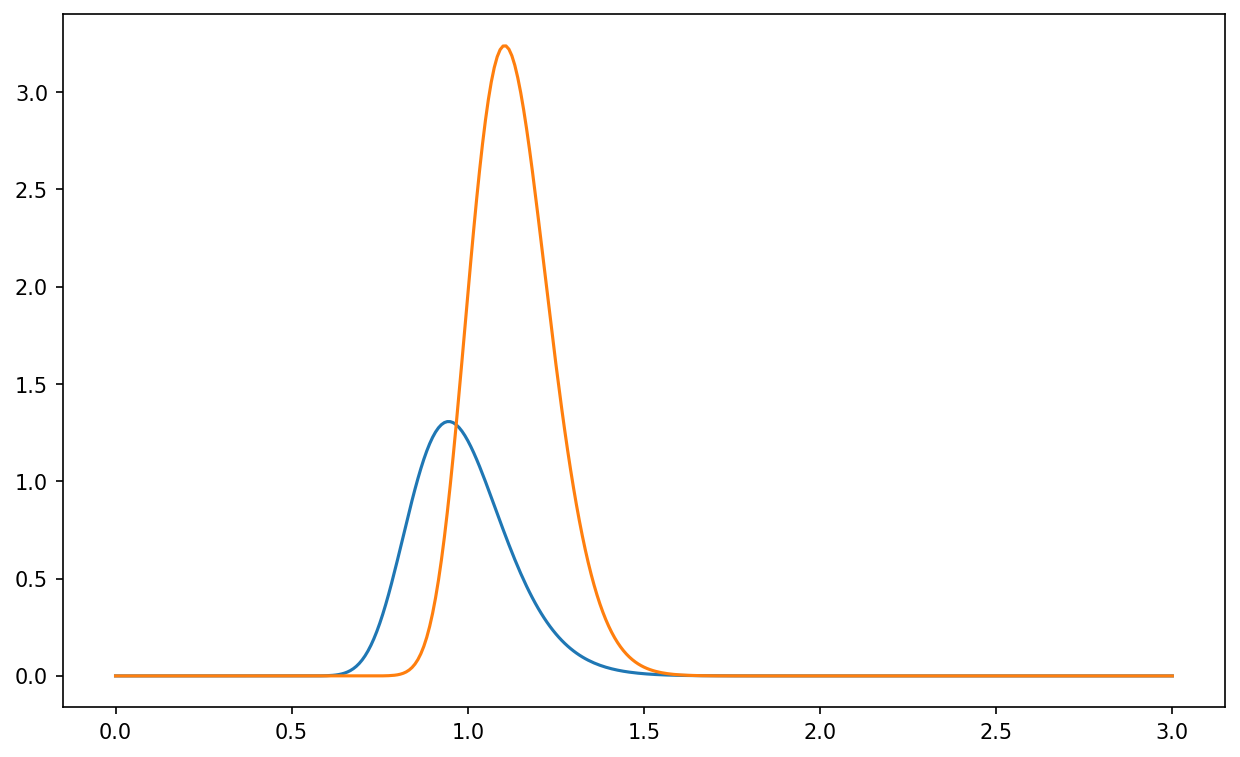

In [141]:
plt.plot(out_opt_no_reg[1],btcs_no_reg[-1]/np.trapezoid(btcs_no_reg[-2],out_opt_no_reg[1]))
plt.plot(out_opt_reg[1],btcs_reg[-1]/np.trapezoid(btcs_reg[-2],out_opt_reg[1]))
# for params_log in [params_log_no_reg,params_log_reg]:
#     Pe = 10**params_log[0]
#     xs_Pe= np.linspace(0,1,200)*Pe
#     ts_Pe = ts*Pe
#     beta_k = 0.0#10**params_log[1]
#     D_fac = 10**params_log[3]
#     kappa = params_log[4]
#     a = params_log[5]
#     cs = ADE_forced_analytical_derived_params(xs_Pe,ts_Pe, xs_Pe[1]-xs_Pe[0],ts_Pe[1]-ts_Pe[0],beta_k/Pe, D_fac, kappa, a,'uniform')
#     plt.plot(ts_Pe[1:]/Pe,cs[1:,-1]/np.trapezoid(cs[1:,-1],x=ts_Pe[1:]/Pe))

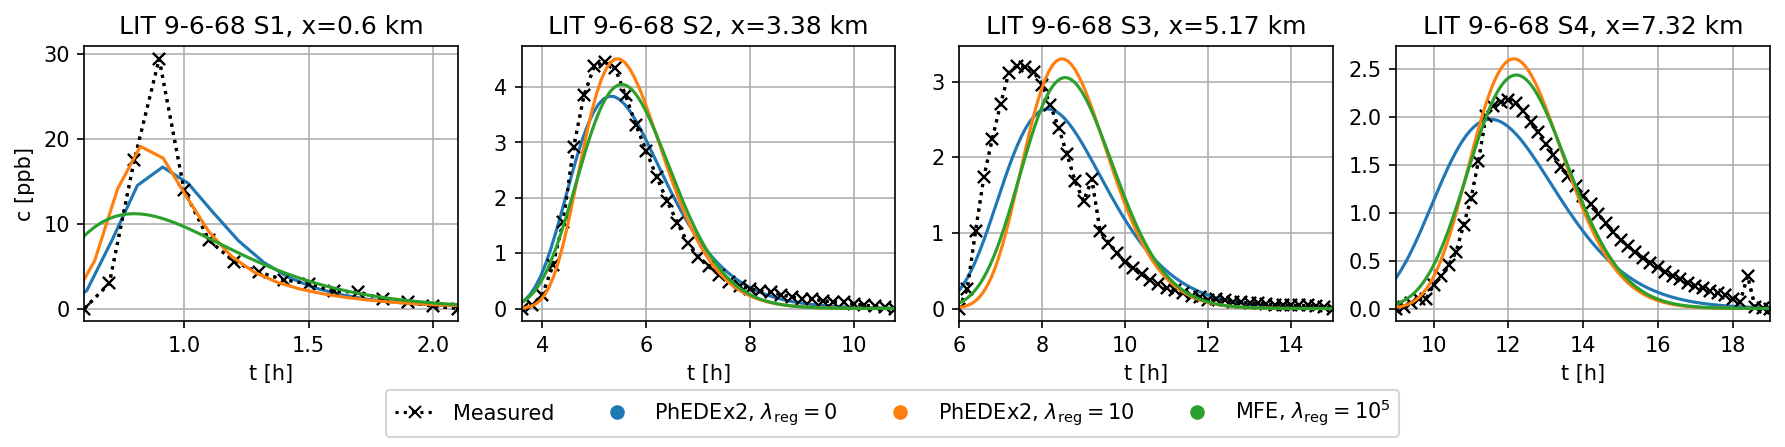

In [142]:
fig,axes = plt.subplots(ncols = 4, figsize = (len(btcs_m_i)*3,3))
axes = axes.flatten()
moms_MRMT_ = np.zeros((4,4))
moms_PhEDEx2_ = np.zeros((4,4))
for i in range(len(btcs_m_i)):
    ax = axes[i]
    interp_fac_no_reg = np.array([np.interp(xs_i[i]/xs_i[-1],out_opt_no_reg[0],vec) for vec in np.eye(len(out_opt_no_reg[0]))])
    synth_btc_no_reg = out_opt_no_reg[2]@interp_fac_no_reg
    ax.plot(ts_i[i],btcs_m_i[i],c = 'k', linestyle = 'dotted', marker = 'x')
    ax.plot(out_opt_no_reg[1]*t_scale_opt_no_reg,synth_btc_no_reg/np.trapezoid(synth_btc_no_reg,out_opt_no_reg[1]*t_scale_opt_no_reg)*np.trapezoid(btcs_m_i[i],ts_i[i]),
             c = 'tab:blue')
    
    interp_fac_reg = np.array([np.interp(xs_i[i]/xs_i[-1],out_opt_reg[0],vec) for vec in np.eye(len(out_opt_reg[0]))])
    synth_btc_reg = out_opt_reg[2]@interp_fac_reg
    ax.plot(ts_i[i],btcs_m_i[i],c = 'k', linestyle = 'dotted', marker = 'x')
    ax.plot(out_opt_reg[1]*t_scale_opt_reg,synth_btc_reg/np.trapezoid(synth_btc_reg,out_opt_reg[1]*t_scale_opt_reg)*np.trapezoid(btcs_m_i[i],ts_i[i]),
             c = 'tab:orange')
    
    # ax.plot(ts_plot*t_scale_opt_MRMT_no_reg,btcs_MRMT_no_reg[i]/np.trapezoid(btcs_MRMT_no_reg[i],ts_plot*t_scale_opt_MRMT_no_reg)*np.trapezoid(btcs_m_i[i],ts_i[i]),
    #         c = 'tab:orange')
    ax.plot(ts_plot*t_scale_opt_MRMT_reg,btcs_MRMT_reg[i]/np.trapezoid(btcs_MRMT_reg[i],ts_plot*t_scale_opt_MRMT_reg)*np.trapezoid(btcs_m_i[i],ts_i[i]),
            c = 'tab:green')
    ax.set_xlim(ts_i[i][0],ts_i[i][-1])
    ax.set_title(names_list[index_ttl[i_ttl][i]]+', x='+str(round(xs_i[i],2))+' km')
    if i == 0:
        ax.set_ylabel('c [ppb]')
    ax.set_xlabel('t [h]')
    ax.grid()
fig.legend(handles=[
        plt.Line2D([0], [0], c = 'k',linestyle = 'dotted',marker = 'x', label="Measured"),
        plt.Line2D([0], [0], marker='o', color="tab:blue",linestyle = 'none', label=r"PhEDEx2, $\lambda_{\text{reg}}=0$"),
        plt.Line2D([0], [0], marker='o', color="tab:orange",linestyle = 'none', label=r"PhEDEx2, $\lambda_{\text{reg}}=10$"),
        plt.Line2D([0], [0], marker='o', color="tab:green",linestyle = 'none', label=r"MFE, $\lambda_{\text{reg}}=10^{5}$"),
        ], loc="lower center", ncol=5)
plt.tight_layout(rect=[0,0.08,1,1])
plt.subplots_adjust(wspace=0.17)

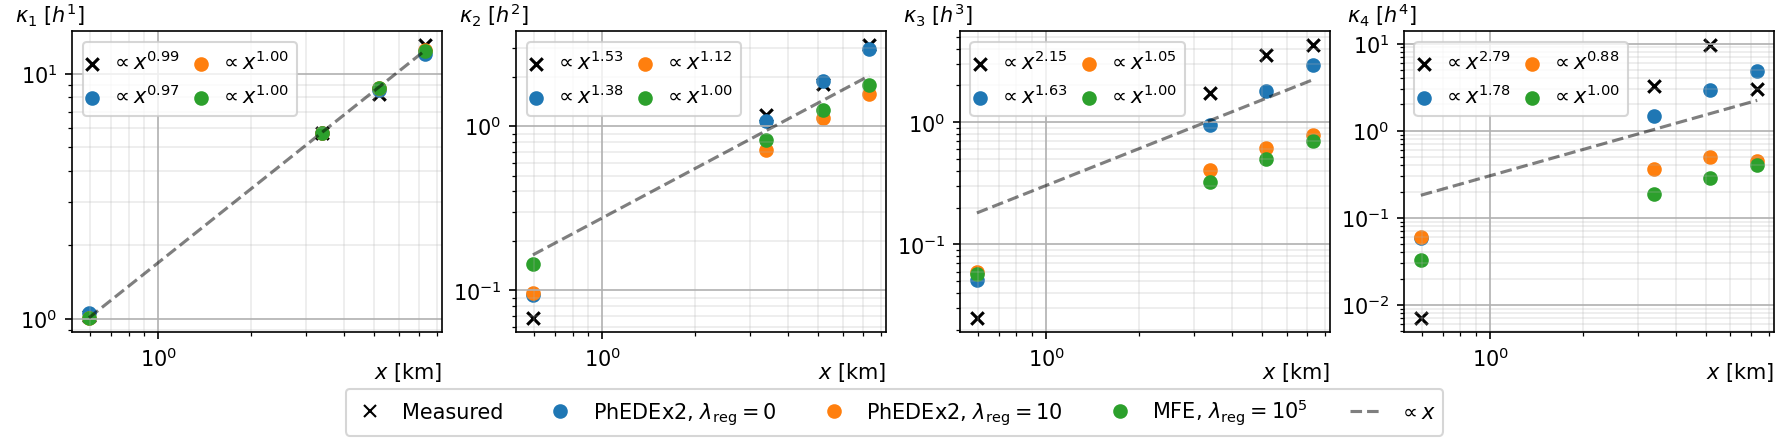

In [143]:
fig,axes = plt.subplots(ncols = N_moms, figsize = (N_moms*3,3))
axes = axes.flatten()

for i in range(N_moms):
    ax = axes[i]
    ax.scatter(xs_i,cumul_ref[:,i],label = fr'$\propto x^{{{np.polyfit(np.log(xs_i)[cumul_ref[:,i]>0],np.log(cumul_ref[:,i][cumul_ref[:,i]>0]),1)[0]:.2f}}}$', c = 'k', marker = 'x')
    ax.scatter(xs_i,cumuls_out_no_reg[:,i]*t_scale_opt_no_reg**(i+1),label = fr'$\propto x^{{{np.polyfit(np.log(xs_i),np.log(cumuls_out_no_reg[:,i]),1)[0]:.2f}}}$')
    ax.scatter(xs_i,cumuls_out_reg[:,i]*t_scale_opt_reg**(i+1),label = fr'$\propto x^{{{np.polyfit(np.log(xs_i),np.log(cumuls_out_reg[:,i]),1)[0]:.2f}}}$')
    # ax.scatter(xs_i,np.array([central_moments_to_cumulants(mom) for mom in moms_PhEDEx2_])[:,i]*moms_loss(moms_PhEDEx2_)[1]**(i+1),label = fr'$\propto x^{{{np.polyfit(np.log(xs_i),np.log([central_moments_to_cumulants(mom) for mom in moms_PhEDEx2_])[:,i],1)[0]:.2f}}}$')
    # ax.scatter(xs_i,cumuls_opt_MRMT_no_reg[:,i]*t_scale_opt_MRMT_no_reg**(i+1),label = fr'$\propto x^{{{np.polyfit(np.log(xs_i),np.log(cumuls_opt_MRMT_no_reg[:,i]),1)[0]:.2f}}}$')
    ax.scatter(xs_i,cumuls_opt_MRMT_reg[:,i]*t_scale_opt_MRMT_reg**(i+1),label = fr'$\propto x^{{{np.polyfit(np.log(xs_i),np.log(cumuls_opt_MRMT_reg[:,i]),1)[0]:.2f}}}$')
    a = np.exp(np.mean(np.log(cumul_ref[:,i])-np.log(xs_i)))
    ax.plot(xs_i,np.array(xs_i)*a, c = 'k', linestyle = 'dashed', alpha = 0.5)
    ax.set_xlabel(r'$x$ [km]',loc = 'right', labelpad = -5.0)
    ax.set_ylabel(fr'$\kappa_{i+1}$ [$h^{i+1}$]', rotation=0, labelpad = -20.0)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(ncols = 2, columnspacing=1.0, handlelength=0.1)
    ax.grid(which = 'major')
    ax.grid(which = 'minor', linewidth = 0.2)
    ax.yaxis.set_label_coords(-0.06, 1.01) 
    ax.tick_params(axis='both', which='major', labelbottom=True, labelleft=True)
    ax.tick_params(axis='both', which='minor', labelbottom=False, labelleft=False)
    ax.tick_params(axis='y', which='minor', labelbottom=True, labelleft=True, labelsize = 8,pad = -0.1)
    ax.tick_params(axis='x', which='minor', labelbottom=True, labelleft=True, labelsize = 8,pad = -0.1)
    # # ax.tick_params(axis='x', which='minor', labelsize=8)
    # ax.xaxis.set_major_formatter(lambda x,y: format(x,'.0f'))
    # # ax.yaxis.set_minor_formatter(lambda x,y: format(x,'.0f'))
    # # ax.tick_params(axis='y', which='minor', labelsize=8)
    # ax.yaxis.set_major_formatter(lambda x,y: format(x,'.0f'))
fig.legend(handles=[
        plt.Line2D([0], [0], marker='x', c = 'k',linestyle = 'none', label="Measured"),
        plt.Line2D([0], [0], marker='o', color="tab:blue",linestyle = 'none', label=r"PhEDEx2, $\lambda_{\text{reg}}=0$"),
        plt.Line2D([0], [0], marker='o', color="tab:orange",linestyle = 'none', label=r"PhEDEx2, $\lambda_{\text{reg}}=10$"),
        plt.Line2D([0], [0], marker='o', color="tab:green",linestyle = 'none', label=r"MFE, $\lambda_{\text{reg}}=10^{5}$"),
        plt.Line2D([0], [0], c = 'k', linestyle = 'dashed', alpha = 0.5, label=r"$\propto x$")
        ], loc="lower center", ncol=5, handlelength=1.5)
plt.tight_layout(rect=[0,0.08,1,1])
plt.subplots_adjust(wspace=0.2)

In [144]:
from IPython.display import display, Math
print('a=', round(1.37*np.log(1.33*B_tracer/H_tracer),2))
print('Pe_a(a) =', round(Pe_a_tracer(1.37*np.log(1.33*B_tracer/H_tracer)),1))
print('PhEDEx2 no reg')
display(*[Math(name+r'=$'+format(par,f'.{prec}f')) for par,prec,name in zip([10**params_log_no_reg[0],10**params_log_no_reg[1],10**params_log_no_reg[2],10**params_log_no_reg[3],params_log_no_reg[4],params_log_no_reg[5]],
                                       [1,2,2,3,3,2],[r'$Pe',r'$\beta \hat{k}_{f,\infty}',r'$\hat{k}_r',r'$d',r'$\kappa_{bk}',r'$\alpha'])]) 
display(Math(r'$L(\gamma)=$'+format(moms_loss(moms_out_no_reg)[0],'.3f')))
print('PhEDEx2 reg')
display(*[Math(name+r'=$'+format(par,f'.{prec}f')) for par,prec,name in zip([10**params_log_reg[0],10**params_log_reg[1],10**params_log_reg[2],10**params_log_reg[3],params_log_reg[4],params_log_reg[5]],
                                       [1,2,2,3,3,2],[r'$Pe',r'$\beta \hat{k}_{f,\infty}',r'$\hat{k}_r',r'$d',r'$\kappa_{bk}',r'$\alpha'])]) 
display(Math(r'$L(\gamma)=$'+format(moms_loss(moms_out_reg)[0],'.3f')))
print('MFE reg')
display(*[Math(name+r'=$'+format(par,f'.{prec}f')) for par,prec,name in zip([10**params_log_MRMT_reg[0],10**params_log_MRMT_reg[1],10**params_log_MRMT_reg[2]],
                                       [1,2,2],[r'$Pe',r'$\beta \hat{k}_{f,\infty}',r'$\hat{k}_r'])]) 
display(Math(r'$L(\gamma)=$'+format(moms_loss(moms_MRMT_reg)[0],'.3f')))
# print('MFE no reg')
# display(*[Math(name+r'=$'+format(par,f'.{prec}f')) for par,prec,name in zip([10**params_log_MRMT_no_reg[0],10**params_log_MRMT_no_reg[1],10**params_log_MRMT_no_reg[2]],
#                                        [1,2,2],[r'$Pe',r'$\beta \hat{k}_{f,\infty}',r'$\hat{k}_r'])]) 
# display(Math(r'$L(\gamma)=$'+format(moms_loss(moms_MRMT_no_reg)[0],'.3f')))

a= 6.25
Pe_a(a) = 435.5
PhEDEx2 no reg


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (11 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>